# **CLAM Pipeline**

## *downloads SVS files from Google Drive links*

In [ ]:
"""
CLAM Project Setup Script
This script sets up the environment, installs required libraries,
and downloads SVS files from Google Drive links for CLAM pipeline processing.
"""

import os
import sys
import subprocess
import urllib.request
import zipfile
from pathlib import Path
import logging

# Setup logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

class CLAMSetup:
    def __init__(self):
        self.project_dir = Path("CLAM_project")
        self.data_dir = self.project_dir / "data" / "svs_files"
        self.results_dir = self.project_dir / "results"

        # Google Drive file IDs extracted from the provided links
        self.file_ids = [
            "1K1A0ebOAm6RwLHPKdCRymj9ewgILjV38",
            "1x4kGKXJoDz70gyHNRES5OqCK1YIIa8PB",
            "18FnkbWFhiI7VYVJWkmZoyAgplkQydBcQ",
            "1AekGGam2LLCdoK79r9XaO3gilaoRCXCs",
            "1hHHMYAgN9QSy6jFZWxlmuT_38ihUMt11",
            "1sxo63tpah5SyOxNSlHco_jzmMOK_o4rM",
            "166KxMY11jPwst3iGKvuOqltQzr1BaG1e"
        ]

    def create_directories(self):
        """Create necessary project directories"""
        logger.info("Creating project directories...")
        directories = [
            self.project_dir,
            self.data_dir,
            self.results_dir,
            self.project_dir / "patches",
            self.project_dir / "features",
            self.project_dir / "models",
            self.project_dir / "magnifications" / "5x",
            self.project_dir / "magnifications" / "10x",
            self.project_dir / "magnifications" / "20x",
            self.project_dir / "magnifications" / "40x"
        ]

        for directory in directories:
            directory.mkdir(parents=True, exist_ok=True)
            logger.info(f"Created directory: {directory}")

    def install_system_dependencies(self):
        """Install system-level dependencies required for CLAM"""
        logger.info("Installing system dependencies...")

        # Check if running on Ubuntu/Debian
        if os.path.exists("/etc/apt/sources.list"):
            commands = [
                "sudo apt-get update",
                "sudo apt-get install -y openslide-tools python3-openslide",
                "sudo apt-get install -y libvips-dev",
                "sudo apt-get install -y python3-dev python3-pip"
            ]
        # Check if running on CentOS/RHEL
        elif os.path.exists("/etc/redhat-release"):
            commands = [
                "sudo yum update -y",
                "sudo yum install -y openslide openslide-devel",
                "sudo yum install -y vips-devel",
                "sudo yum install -y python3-devel python3-pip"
            ]
        # MacOS
        elif sys.platform == "darwin":
            commands = [
                "brew install openslide",
                "brew install vips"
            ]
        else:
            logger.warning("Unsupported OS. Please install openslide and vips manually.")
            return

        for cmd in commands:
            try:
                logger.info(f"Running: {cmd}")
                subprocess.run(cmd.split(), check=True)
            except subprocess.CalledProcessError as e:
                logger.error(f"Failed to run command: {cmd}")
                logger.error(f"Error: {e}")

    def create_conda_environment(self):
        """Create and setup conda environment for CLAM"""
        logger.info("Creating conda environment for CLAM...")

        # Create conda environment
        env_commands = [
            "conda create -n clam python=3.8 -y",
            "conda activate clam"
        ]

        try:
            # Create environment file
            env_file_content = """name: clam
channels:
  - pytorch
  - conda-forge
  - defaults
dependencies:
  - python=3.8
  - pytorch>=1.6.0
  - torchvision
  - cudatoolkit=11.1  # Adjust based on your CUDA version
  - numpy
  - pandas
  - scipy
  - scikit-learn
  - matplotlib
  - seaborn
  - tqdm
  - h5py
  - opencv
  - pillow
  - openslide-python
  - pip
  - pip:
    - openslide-python==1.1.2
    - smooth-topk
    - captum
    - tensorboard
    - wandb
    - timm
    - einops
    - nystrom-attention
"""

            env_file_path = self.project_dir / "environment.yml"
            with open(env_file_path, 'w') as f:
                f.write(env_file_content)

            logger.info(f"Created environment file: {env_file_path}")
            logger.info("Run 'conda env create -f environment.yml' to create the environment")

        except Exception as e:
            logger.error(f"Error creating conda environment: {e}")

    def install_python_dependencies(self):
        """Install Python dependencies for CLAM"""
        logger.info("Installing Python dependencies...")

        # CLAM specific requirements
        requirements = [
            "torch>=1.6.0",
            "torchvision>=0.7.0",
            "numpy>=1.19.2",
            "pandas>=1.1.3",
            "scipy>=1.5.4",
            "scikit-learn>=0.23.2",
            "matplotlib>=3.3.2",
            "seaborn>=0.11.0",
            "tqdm>=4.50.2",
            "h5py>=2.10.0",
            "opencv-python>=4.4.0",
            "Pillow>=8.0.1",
            "openslide-python>=1.1.2",
            "smooth-topk",
            "captum",
            "tensorboard",
            "wandb",
            "timm>=0.4.12",
            "einops>=0.3.0",
            "nystrom-attention",
            "gdown>=4.0.0"  # For Google Drive downloads
        ]

        # Create requirements.txt
        req_file_path = self.project_dir / "requirements.txt"
        with open(req_file_path, 'w') as f:
            for req in requirements:
                f.write(f"{req}\n")

        logger.info(f"Created requirements file: {req_file_path}")

        # Install requirements
        try:
            cmd = f"pip install -r {req_file_path}"
            logger.info(f"Running: {cmd}")
            subprocess.run(cmd.split(), check=True)
            logger.info("Successfully installed Python dependencies")
        except subprocess.CalledProcessError as e:
            logger.error(f"Failed to install requirements: {e}")

    def download_svs_files(self):
        """Download SVS files from Google Drive"""
        logger.info("Downloading SVS files from Google Drive...")

        try:
            import gdown
        except ImportError:
            logger.error("gdown not installed. Installing...")
            subprocess.run([sys.executable, "-m", "pip", "install", "gdown"], check=True)
            import gdown

        for i, file_id in enumerate(self.file_ids, 1):
            try:
                logger.info(f"Downloading file {i}/7 (ID: {file_id})")
                url = f"https://drive.google.com/uc?id={file_id}"
                output_path = self.data_dir / f"slide_{i}.svs"

                # Download file
                gdown.download(url, str(output_path), quiet=False)

                # Verify file was downloaded
                if output_path.exists():
                    file_size = output_path.stat().st_size / (1024*1024)  # Size in MB
                    logger.info(f"Successfully downloaded: {output_path} ({file_size:.2f} MB)")
                else:
                    logger.error(f"Failed to download: {output_path}")

            except Exception as e:
                logger.error(f"Error downloading file {i}: {e}")
                logger.info("Trying alternative download method...")

                # Alternative download method
                try:
                    alt_url = f"https://drive.google.com/file/d/{file_id}/view?usp=sharing"
                    download_url = f"https://drive.google.com/uc?export=download&id={file_id}"
                    output_path = self.data_dir / f"slide_{i}.svs"

                    urllib.request.urlretrieve(download_url, output_path)
                    logger.info(f"Alternative download successful: {output_path}")
                except Exception as alt_e:
                    logger.error(f"Alternative download also failed: {alt_e}")

    def clone_clam_repository(self):
        """Clone the CLAM repository"""
        logger.info("Cloning CLAM repository...")

        clam_dir = self.project_dir / "CLAM"
        if clam_dir.exists():
            logger.info("CLAM repository already exists")
            return

        try:
            cmd = f"git clone https://github.com/mahmoodlab/CLAM.git {clam_dir}"
            subprocess.run(cmd.split(), check=True)
            logger.info(f"Successfully cloned CLAM to: {clam_dir}")
        except subprocess.CalledProcessError as e:
            logger.error(f"Failed to clone CLAM repository: {e}")

    def create_config_files(self):
        """Create configuration files for CLAM pipeline"""
        logger.info("Creating configuration files...")

        # Create data processing config
        config_content = f"""# CLAM Configuration File
# Data directories
DATA_ROOT_DIR: {self.data_dir}
RESULTS_DIR: {self.results_dir}

# Patch extraction settings
PATCH_SIZE: 256
PATCH_LEVEL: 0
STEP_SIZE: 256

# Magnification levels for processing
MAGNIFICATIONS: [5, 10, 20, 40]

# Feature extraction settings
FEATURE_EXTRACTOR: "resnet50"
BATCH_SIZE: 512

# Model training settings
MODEL_TYPE: "clam_sb"  # or "clam_mb" for multi-branch
N_CLASSES: 2
BAG_LOSS: "ce"
INST_LOSS: "ce"
BAG_WEIGHT: 0.7
"""

        config_path = self.project_dir / "config.yaml"
        with open(config_path, 'w') as f:
            f.write(config_content)

        logger.info(f"Created configuration file: {config_path}")

        # Create processing script template
        script_content = """#!/usr/bin/env python3
'''
CLAM Pipeline Processing Script Template
Run this after setup is complete
'''

import os
import sys
from pathlib import Path

# Add CLAM to Python path
project_dir = Path(__file__).parent
clam_dir = project_dir / "CLAM"
sys.path.insert(0, str(clam_dir))

def main():
    print("CLAM Pipeline Processing")
    print("=" * 50)

    # 1. Patch extraction at different magnifications
    print("Step 1: Patch extraction...")
    # Add patch extraction code here

    # 2. Feature extraction
    print("Step 2: Feature extraction...")
    # Add feature extraction code here

    # 3. Model training
    print("Step 3: Model training...")
    # Add training code here

    print("Pipeline completed!")

if __name__ == "__main__":
    main()
"""

        script_path = self.project_dir / "run_pipeline.py"
        with open(script_path, 'w') as f:
            f.write(script_content)

        os.chmod(script_path, 0o755)  # Make executable
        logger.info(f"Created processing script: {script_path}")

    def verify_setup(self):
        """Verify the setup is complete"""
        logger.info("Verifying setup...")

        # Check directories
        required_dirs = [self.data_dir, self.results_dir]
        for directory in required_dirs:
            if directory.exists():
                logger.info(f"✓ Directory exists: {directory}")
            else:
                logger.error(f"✗ Directory missing: {directory}")

        # Check downloaded files
        svs_files = list(self.data_dir.glob("*.svs"))
        logger.info(f"✓ Found {len(svs_files)} SVS files")

        # Check Python packages
        required_packages = ["torch", "openslide", "pandas", "numpy", "sklearn"]
        for package in required_packages:
            try:
                __import__(package)
                logger.info(f"✓ Package available: {package}")
            except ImportError:
                logger.error(f"✗ Package missing: {package}")

        logger.info("Setup verification completed!")

    def run_setup(self):
        """Run the complete setup process"""
        logger.info("Starting CLAM project setup...")

        try:
            self.create_directories()
            self.install_system_dependencies()
            self.create_conda_environment()
            self.install_python_dependencies()
            self.clone_clam_repository()
            self.download_svs_files()
            self.create_config_files()
            self.verify_setup()

            logger.info("=" * 60)
            logger.info("CLAM SETUP COMPLETED SUCCESSFULLY!")
            logger.info("=" * 60)
            logger.info("Next steps:")
            logger.info("1. Activate conda environment: conda activate clam")
            logger.info("2. Navigate to project directory: cd CLAM_project")
            logger.info("3. Run the pipeline: python run_pipeline.py")
            logger.info("4. Check the results in the results/ directory")

        except Exception as e:
            logger.error(f"Setup failed: {e}")
            raise

def main():
    """Main function to run the setup"""
    setup = CLAMSetup()
    setup.run_setup()

if __name__ == "__main__":
    main()

ERROR:__main__:Failed to install requirements: Command '['pip', 'install', '-r', 'CLAM_project/requirements.txt']' returned non-zero exit status 1.
Downloading...
From (original): https://drive.google.com/uc?id=1K1A0ebOAm6RwLHPKdCRymj9ewgILjV38
From (redirected): https://drive.google.com/uc?id=1K1A0ebOAm6RwLHPKdCRymj9ewgILjV38&confirm=t&uuid=b55a8271-bf94-4e5e-a7f9-093c4aec8332
To: /content/CLAM_project/data/svs_files/slide_1.svs
100%|██████████| 405M/405M [00:16<00:00, 24.8MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1x4kGKXJoDz70gyHNRES5OqCK1YIIa8PB
From (redirected): https://drive.google.com/uc?id=1x4kGKXJoDz70gyHNRES5OqCK1YIIa8PB&confirm=t&uuid=3bac61b4-ce3f-40f1-a6f7-b02087ee894d
To: /content/CLAM_project/data/svs_files/slide_2.svs
100%|██████████| 463M/463M [00:08<00:00, 55.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=18FnkbWFhiI7VYVJWkmZoyAgplkQydBcQ
To: /content/CLAM_project/data/svs_files/slide_3.svs
100%|██████████| 88.1M/88.1M [00:01<00:

## *CLAM Environment*

In [ ]:
"""
Improved CLAM Environment Setup for Google Colab
Handles environment refresh and installation issues
"""

import os
import sys
import subprocess
import logging
import time
from pathlib import Path

# Setup logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

class CLAMEnvironmentSetup:
    def __init__(self):
        self.setup_complete_file = Path("/content/.clam_setup_complete")
        self.packages_installed_file = Path("/content/.clam_packages_installed")

    def is_setup_complete(self):
        """Check if setup was already completed"""
        return self.setup_complete_file.exists()

    def are_packages_installed(self):
        """Check if packages were already installed"""
        return self.packages_installed_file.exists()

    def mark_setup_complete(self):
        """Mark setup as complete"""
        self.setup_complete_file.touch()

    def mark_packages_installed(self):
        """Mark packages as installed"""
        self.packages_installed_file.touch()

    def install_system_dependencies(self):
        """Install system dependencies for Colab"""
        logger.info("Installing system dependencies for Colab...")

        commands = [
            "apt-get update -qq",
            "apt-get install -y -qq openslide-tools",
            "apt-get install -y -qq python3-openslide",
            "apt-get install -y -qq libvips-dev",
            "apt-get install -y -qq libopenjp2-7-dev",
            "ldconfig"  # Refresh library cache
        ]

        for cmd in commands:
            try:
                logger.info(f"Running: {cmd}")
                result = subprocess.run(cmd.split(), capture_output=True, text=True, check=True)
                logger.info(f"✓ Success: {cmd}")
                time.sleep(1)  # Small delay between commands
            except subprocess.CalledProcessError as e:
                logger.error(f"✗ Failed: {cmd}")
                logger.error(f"Error: {e.stderr}")

    def setup_environment_variables(self):
        """Setup environment variables for Colab"""
        logger.info("Setting up environment variables...")

        # Set library path for OpenSlide
        lib_paths = [
            '/usr/lib/x86_64-linux-gnu',
            '/usr/local/lib',
            '/usr/lib',
            '/lib/x86_64-linux-gnu'
        ]

        current_path = os.environ.get('LD_LIBRARY_PATH', '')
        new_path = ':'.join(lib_paths + ([current_path] if current_path else []))
        os.environ['LD_LIBRARY_PATH'] = new_path

        # Set Python path
        python_paths = [
            '/usr/lib/python3/dist-packages',
            '/usr/local/lib/python3.10/dist-packages'
        ]

        for path in python_paths:
            if path not in sys.path:
                sys.path.insert(0, path)

        # Set OpenSlide cache size
        os.environ['OPENSLIDE_CACHE_SIZE'] = '1000000000'  # 1GB cache

        logger.info(f"Set LD_LIBRARY_PATH: {new_path}")
        logger.info("Set OpenSlide cache size to 1GB")
        logger.info("Updated Python path")

    def install_python_packages(self):
        """Install Python packages with better error handling"""
        if self.are_packages_installed():
            logger.info("Packages already installed, skipping...")
            return True

        logger.info("Installing Python packages...")

        # Core packages that should work
        core_packages = [
            ("torch", "torch torchvision torchaudio"),
            ("numpy", "numpy"),
            ("pandas", "pandas"),
            ("scipy", "scipy"),
            ("scikit-learn", "scikit-learn"),
            ("matplotlib", "matplotlib"),
            ("seaborn", "seaborn"),
            ("tqdm", "tqdm"),
            ("h5py", "h5py"),
            ("opencv-python", "opencv-python"),
            ("Pillow", "Pillow")
        ]

        # Install core packages
        for package_name, install_cmd in core_packages:
            try:
                logger.info(f"Installing {package_name}...")
                subprocess.run([sys.executable, "-m", "pip", "install"] + install_cmd.split() + ["-q"],
                             check=True, capture_output=True, text=True, timeout=300)
                logger.info(f"✓ {package_name} installed")
                time.sleep(2)  # Delay between installations
            except Exception as e:
                logger.error(f"✗ Failed to install {package_name}: {e}")

        # Try different OpenSlide installations with restart handling
        self._install_openslide()

        # Install additional packages
        additional_packages = [
            "timm",
            "einops",
            "captum",
            "tensorboard"
        ]

        for package in additional_packages:
            try:
                logger.info(f"Installing {package}...")
                subprocess.run([sys.executable, "-m", "pip", "install", package, "-q"],
                             check=True, capture_output=True, text=True, timeout=180)
                logger.info(f"✓ {package} installed")
                time.sleep(1)
            except Exception as e:
                logger.warning(f"⚠ Optional package {package} failed: {e}")

        self.mark_packages_installed()
        return True

    def _install_openslide(self):
        """Install OpenSlide with multiple fallback options"""
        logger.info("Installing OpenSlide Python bindings...")

        openslide_options = [
            ("openslide-python==1.2.0", "pip"),
            ("openslide-python==1.1.2", "pip"),
            ("openslide-python", "pip"),
            ("openslide-python", "conda")
        ]

        openslide_success = False
        for option, method in openslide_options:
            try:
                logger.info(f"Trying {option} via {method}...")

                if method == "pip":
                    subprocess.run([sys.executable, "-m", "pip", "install", option, "-q"],
                                 check=True, capture_output=True, text=True, timeout=300)
                elif method == "conda":
                    subprocess.run(["conda", "install", "-c", "conda-forge", option, "-y", "-q"],
                                 check=True, capture_output=True, text=True, timeout=300)

                logger.info(f"✓ {option} installed successfully via {method}")
                openslide_success = True
                break

            except Exception as e:
                logger.warning(f"⚠ {option} via {method} failed: {e}")
                time.sleep(2)

        if not openslide_success:
            logger.error("Could not install openslide-python")
            logger.info("Will try system package approach...")

    def test_imports_with_retry(self, max_retries=3):
        """Test if critical packages can be imported with retry logic"""
        logger.info("Testing package imports...")

        test_packages = {
            'torch': 'PyTorch',
            'torchvision': 'TorchVision',
            'numpy': 'NumPy',
            'pandas': 'Pandas',
            'sklearn': 'Scikit-learn',
            'cv2': 'OpenCV',
            'PIL': 'Pillow',
            'openslide': 'OpenSlide'
        }

        working_packages = []
        failed_packages = []

        for pkg, name in test_packages.items():
            success = False

            for attempt in range(max_retries):
                try:
                    if pkg == 'openslide':
                        # Special handling for OpenSlide
                        self.setup_environment_variables()
                        time.sleep(1)

                    __import__(pkg)
                    logger.info(f"✓ {name} import successful (attempt {attempt + 1})")
                    working_packages.append(name)
                    success = True
                    break

                except ImportError as e:
                    if attempt < max_retries - 1:
                        logger.warning(f"⚠ {name} import failed (attempt {attempt + 1}): {e}")
                        time.sleep(2)
                    else:
                        logger.error(f"✗ {name} import failed after {max_retries} attempts: {e}")

            if not success:
                failed_packages.append(name)

        logger.info(f"Working packages: {', '.join(working_packages)}")
        if failed_packages:
            logger.warning(f"Failed packages: {', '.join(failed_packages)}")

        return len(failed_packages) == 0

    def verify_svs_files(self):
        """Verify the downloaded SVS files"""
        logger.info("Verifying SVS files...")

        data_dir = Path("/content/CLAM_project/data/svs_files")
        if not data_dir.exists():
            logger.error(f"Data directory not found: {data_dir}")
            return False

        svs_files = list(data_dir.glob("*.svs"))
        logger.info(f"Found {len(svs_files)} SVS files:")

        total_size = 0
        for svs_file in svs_files:
            size_mb = svs_file.stat().st_size / (1024 * 1024)
            total_size += size_mb
            logger.info(f"  {svs_file.name}: {size_mb:.1f} MB")

        logger.info(f"Total size: {total_size:.1f} MB")
        return len(svs_files) >= 6  # At least 6 files as mentioned

    def clone_clam_repo(self):
        """Clone CLAM repository if not exists"""
        logger.info("Setting up CLAM repository...")

        clam_dir = Path("/content/CLAM_project/CLAM")
        if clam_dir.exists():
            logger.info("CLAM repository already exists")
            return True

        try:
            subprocess.run([
                "git", "clone",
                "https://github.com/mahmoodlab/CLAM.git",
                str(clam_dir)
            ], check=True, capture_output=True, text=True, timeout=120)
            logger.info("✓ CLAM repository cloned successfully")
            return True
        except Exception as e:
            logger.error(f"✗ Failed to clone CLAM: {e}")
            return False

    def create_test_script(self):
        """Create a comprehensive test script"""
        test_script = '''
import os
import sys
from pathlib import Path
import time

def test_environment():
    """Test the complete environment"""
    success = True

    print("🔧 Testing CLAM Environment")
    print("=" * 50)

    # Test 1: Basic imports
    try:
        import torch
        import numpy as np
        import pandas as pd
        print("✓ Basic packages imported")
    except Exception as e:
        print(f"✗ Basic packages failed: {e}")
        success = False

    # Test 2: OpenSlide with retry
    openslide_success = False
    for attempt in range(3):
        try:
            import openslide
            print(f"✓ OpenSlide imported (attempt {attempt + 1})")
            openslide_success = True
            break
        except Exception as e:
            print(f"⚠ OpenSlide attempt {attempt + 1} failed: {e}")
            time.sleep(2)

    if not openslide_success:
        print("✗ OpenSlide failed after all attempts")
        success = False

    # Test 3: SVS file access
    if openslide_success:
        try:
            data_dir = Path("/content/CLAM_project/data/svs_files")
            svs_files = list(data_dir.glob("*.svs"))

            if svs_files:
                test_file = svs_files[0]
                print(f"Testing with: {test_file.name}")

                slide = openslide.OpenSlide(str(test_file))
                print(f"✓ Successfully opened slide")
                print(f"  Dimensions: {slide.dimensions}")
                print(f"  Level count: {slide.level_count}")
                slide.close()
                print("✓ SVS file test completed!")
            else:
                print("⚠ No SVS files found")
                success = False

        except Exception as e:
            print(f"✗ SVS file test failed: {e}")
            success = False

    print("=" * 50)
    if success:
        print("🎉 All tests passed! Environment is ready.")
    else:
        print("⚠ Some tests failed. You may need to restart runtime.")

    return success

if __name__ == "__main__":
    test_environment()
'''

        test_file = Path("/content/CLAM_project/test_environment.py")
        test_file.parent.mkdir(parents=True, exist_ok=True)
        with open(test_file, 'w') as f:
            f.write(test_script)

        logger.info(f"Created test script: {test_file}")
        return test_file

    def run_setup(self):
        """Main setup function with restart detection"""
        logger.info("=" * 60)
        logger.info("IMPROVED CLAM ENVIRONMENT SETUP FOR GOOGLE COLAB")
        logger.info("=" * 60)

        try:
            # Check if this is a restart/rerun
            if self.is_setup_complete():
                logger.info(" Setup was previously completed, running verification...")
                self.setup_environment_variables()
                imports_ok = self.test_imports_with_retry(max_retries=2)

                if imports_ok:
                    logger.info(" Environment verified successfully!")
                    test_file = self.create_test_script()
                    logger.info(f" Run: python {test_file} for full verification")
                    return True
                else:
                    logger.warning("⚠ Verification failed, running full setup...")
                    # Continue with full setup

            # Step 1: Install system dependencies
            logger.info(" Installing system dependencies...")
            self.install_system_dependencies()

            # Step 2: Setup environment variables
            logger.info("🔧 Setting up environment...")
            self.setup_environment_variables()

            # Step 3: Install Python packages
            logger.info(" Installing Python packages...")
            self.install_python_packages()

            # Small delay for environment to settle
            logger.info(" Waiting for environment to settle...")
            time.sleep(3)

            # Step 4: Test imports with retry
            logger.info(" Testing imports...")
            imports_ok = self.test_imports_with_retry()

            # Step 5: Verify SVS files
            logger.info(" Verifying SVS files...")
            files_ok = self.verify_svs_files()

            # Step 6: Clone CLAM repo
            logger.info(" Setting up CLAM repository...")
            repo_ok = self.clone_clam_repo()

            # Step 7: Create test script
            test_file = self.create_test_script()

            # Mark setup complete
            self.mark_setup_complete()

            logger.info("=" * 60)
            logger.info(" ENVIRONMENT SETUP COMPLETED!")
            logger.info("=" * 60)

            if imports_ok and files_ok and repo_ok:
                logger.info(" All components ready!")
                logger.info(" Next steps:")
                logger.info(f"   1. Run: python {test_file}")
                logger.info("   2. If test passes, proceed with your MAE feature extraction")
                logger.info("   3. If any issues, the setup will auto-recover on rerun")
            else:
                logger.warning("⚠ Some components may need attention")
                logger.info(" Solution: Restart runtime and run this script again")
                if not imports_ok:
                    logger.warning("   - Package imports need retry")
                if not files_ok:
                    logger.warning("   - SVS files verification failed")
                if not repo_ok:
                    logger.warning("   - CLAM repository setup failed")

            return imports_ok and files_ok and repo_ok

        except Exception as e:
            logger.error(f" Environment setup failed: {e}")
            # Clean up marker files on failure
            if self.setup_complete_file.exists():
                self.setup_complete_file.unlink()
            if self.packages_installed_file.exists():
                self.packages_installed_file.unlink()
            raise

def setup_clam_environment():
    """Convenience function to run setup"""
    setup = CLAMEnvironmentSetup()
    return setup.run_setup()

# Run setup
if __name__ == "__main__":
    setup_clam_environment()

## *Extract JPEG images from corrupted TIFF files*

In [ ]:
"""
JPEG Extractor and CLAM-Compatible Reader
Extract JPEG images from corrupted TIFF files and create CLAM-compatible interface
"""

import os
import io
import numpy as np
from pathlib import Path
from PIL import Image
import struct
import json

class JPEGExtractor:
    def __init__(self, data_dir):
        self.data_dir = Path(data_dir)
        self.extracted_dir = self.data_dir.parent / "extracted_images"
        self.extracted_dir.mkdir(exist_ok=True)

    def extract_jpegs_from_file(self, filepath):
        """Extract all JPEG images from a corrupted TIFF file"""
        print(f"🔍 Extracting JPEGs from {filepath.name}...")

        with open(filepath, 'rb') as f:
            data = f.read()

        jpegs = []
        i = 0

        while i < len(data) - 1:
            # Look for JPEG SOI marker
            start = data.find(b'\xff\xd8', i)
            if start == -1:
                break

            # Look for JPEG EOI marker
            end = data.find(b'\xff\xd9', start + 2)
            if end == -1:
                break

            # Extract JPEG data
            jpeg_data = data[start:end + 2]

            # Validate JPEG
            try:
                img = Image.open(io.BytesIO(jpeg_data))
                img.verify()  # Check if valid

                # Re-open for use (verify() invalidates the image)
                img = Image.open(io.BytesIO(jpeg_data))

                # Only keep reasonable sized images (not thumbnails)
                if img.size[0] >= 200 and img.size[1] >= 200:
                    jpegs.append({
                        'data': jpeg_data,
                        'size': img.size,
                        'mode': img.mode,
                        'format': img.format
                    })
                    print(f"   Found JPEG: {img.size[0]}x{img.size[1]} ({len(jpeg_data)/1024:.1f} KB)")

            except Exception:
                pass  # Invalid JPEG, skip

            i = end + 2

        return jpegs

    def find_best_jpeg(self, jpegs):
        """Find the largest/best quality JPEG from extracted images"""
        if not jpegs:
            return None

        # Sort by size (area)
        best_jpeg = max(jpegs, key=lambda x: x['size'][0] * x['size'][1])
        return best_jpeg

    def extract_and_save_best_images(self):
        """Extract best images from all corrupted files"""
        print(" EXTRACTING BEST IMAGES FROM CORRUPTED FILES")
        print("="*60)

        corrupted_files = [
            "slide_1.svs", "slide_2.svs", "slide_3.svs",
            "slide_4.svs", "slide_5.svs"
        ]

        extracted_info = {}

        for filename in corrupted_files:
            filepath = self.data_dir / filename
            if not filepath.exists():
                continue

            print(f"\n Processing {filename}...")

            # Extract JPEGs
            jpegs = self.extract_jpegs_from_file(filepath)

            if jpegs:
                # Find best JPEG
                best_jpeg = self.find_best_jpeg(jpegs)

                if best_jpeg:
                    # Save as clean image
                    clean_filename = f"clean_{filename.replace('.svs', '.jpg')}"
                    clean_path = self.extracted_dir / clean_filename

                    with open(clean_path, 'wb') as f:
                        f.write(best_jpeg['data'])

                    extracted_info[filename] = {
                        'clean_file': str(clean_path),
                        'original_size': best_jpeg['size'],
                        'mode': best_jpeg['mode'],
                        'jpeg_count': len(jpegs)
                    }

                    print(f"    Saved clean image: {clean_filename}")
                    print(f"    Size: {best_jpeg['size'][0]}x{best_jpeg['size'][1]}")
                else:
                    print(f"   No suitable JPEG found")
            else:
                print(f"   No JPEGs extracted")

        # Save extraction info
        info_file = self.extracted_dir / "extraction_info.json"
        with open(info_file, 'w') as f:
            json.dump(extracted_info, f, indent=2)

        print(f"\n EXTRACTION SUMMARY:")
        print(f" Successfully extracted: {len(extracted_info)}/5 files")
        print(f" Clean images saved to: {self.extracted_dir}")

        return extracted_info

class CLAMCompatibleReader:
    """OpenSlide-compatible interface for extracted JPEG images"""

    def __init__(self, image_path):
        self.image_path = Path(image_path)
        self.image = None
        self._load_image()

    def _load_image(self):
        """Load the extracted JPEG image"""
        try:
            self.image = Image.open(self.image_path)
            if self.image.mode != 'RGB':
                self.image = self.image.convert('RGB')
        except Exception as e:
            raise ValueError(f"Could not load image {self.image_path}: {e}")

    @property
    def dimensions(self):
        """Get image dimensions (OpenSlide compatible)"""
        if self.image:
            return self.image.size
        return (0, 0)

    @property
    def level_count(self):
        """Number of pyramid levels (simplified to 1)"""
        return 1

    @property
    def level_dimensions(self):
        """Dimensions at each level"""
        return [self.dimensions]

    @property
    def level_downsamples(self):
        """Downsample factors for each level"""
        return [1.0]

    @property
    def properties(self):
        """Slide properties (mimics OpenSlide)"""
        return {
            'openslide.vendor': 'extracted_jpeg',
            'aperio.AppMag': '20',  # Assume 20x magnification
            'openslide.mpp-x': '0.5',
            'openslide.mpp-y': '0.5',
            'openslide.comment': f'Extracted JPEG from corrupted TIFF: {self.image_path.name}'
        }

    def read_region(self, location, level, size):
        """Read a region from the image (OpenSlide compatible)"""
        if level != 0:
            raise ValueError("Only level 0 supported for extracted images")

        x, y = location
        w, h = size

        # Ensure coordinates are within bounds
        img_w, img_h = self.image.size
        x = max(0, min(x, img_w - w))
        y = max(0, min(y, img_h - h))
        w = min(w, img_w - x)
        h = min(h, img_h - y)

        # Crop the region
        region = self.image.crop((x, y, x + w, y + h))

        return region

    def close(self):
        """Close the image"""
        if self.image:
            self.image.close()
            self.image = None

class UnifiedSlideReader:
    """Unified reader that works with both OpenSlide and extracted images"""

    def __init__(self, slide_path):
        self.slide_path = Path(slide_path)
        self.reader = None
        self.reader_type = None
        self._initialize_reader()

    def _initialize_reader(self):
        """Initialize appropriate reader based on file type"""
        # First try OpenSlide
        try:
            import openslide
            self.reader = openslide.OpenSlide(str(self.slide_path))
            self.reader_type = "openslide"
            print(f" {self.slide_path.name}: Using OpenSlide")
            return
        except Exception:
            pass

        # If OpenSlide fails, look for extracted JPEG
        extracted_dir = self.slide_path.parent.parent / "extracted_images"
        clean_filename = f"clean_{self.slide_path.stem}.jpg"
        clean_path = extracted_dir / clean_filename

        if clean_path.exists():
            try:
                self.reader = CLAMCompatibleReader(clean_path)
                self.reader_type = "extracted_jpeg"
                print(f" {self.slide_path.name}: Using extracted JPEG")
                return
            except Exception:
                pass

        raise ValueError(f"Could not initialize reader for {self.slide_path}")

    def __getattr__(self, name):
        """Delegate all attributes to the underlying reader"""
        if self.reader is None:
            raise ValueError("No reader initialized")
        return getattr(self.reader, name)

def create_clam_patch_extractor():
    """Create CLAM-compatible patch extraction script"""

    patch_extractor_code = '''
#!/usr/bin/env python3
"""
CLAM Patch Extraction with Unified Reader
Extract patches from both OpenSlide-compatible and extracted JPEG files
"""

import sys
import numpy as np
from pathlib import Path
from tqdm import tqdm
import cv2

# Add the parent directory to path for imports
sys.path.append(str(Path(__file__).parent))
from jpeg_extractor_clam import UnifiedSlideReader

class CLAMPatchExtractor:
    def __init__(self, data_dir, output_dir):
        self.data_dir = Path(data_dir)
        self.output_dir = Path(output_dir)
        self.patch_size = 256
        self.step_size = 256

        # Create output directories
        for mag in ['5x', '10x', '20x', '40x']:
            (self.output_dir / "patches" / mag).mkdir(parents=True, exist_ok=True)

    def extract_patches_from_slide(self, slide_path, target_magnifications=[5, 10, 20, 40]):
        """Extract patches at different magnifications"""
        print(f"\\n🔬 Processing {slide_path.name}...")

        try:
            slide = UnifiedSlideReader(slide_path)

            # Get slide info
            width, height = slide.dimensions
            print(f"   📐 Dimensions: {width}x{height}")

            # For extracted JPEGs, simulate different magnifications by resizing
            for target_mag in target_magnifications:
                print(f"   🔍 Extracting patches at {target_mag}x...")

                # Calculate resize factor (assuming base is 20x)
                base_mag = 20
                resize_factor = target_mag / base_mag

                # Resize image for this magnification
                if resize_factor != 1.0:
                    new_width = int(width * resize_factor)
                    new_height = int(height * resize_factor)

                    # Read full image and resize
                    full_image = slide.read_region((0, 0), 0, (width, height))
                    resized_image = full_image.resize((new_width, new_height), Image.Resampling.LANCZOS)

                    # Update dimensions for patch extraction
                    patch_width, patch_height = new_width, new_height
                    source_image = resized_image
                else:
                    patch_width, patch_height = width, height
                    source_image = None  # Will read regions directly

                # Extract patches
                patches_extracted = 0
                output_dir = self.output_dir / "patches" / f"{target_mag}x"

                x_coords = range(0, patch_width - self.patch_size + 1, self.step_size)
                y_coords = range(0, patch_height - self.patch_size + 1, self.step_size)

                for x in tqdm(x_coords, desc=f"   {target_mag}x patches"):
                    for y in y_coords:
                        # Extract patch
                        if source_image:
                            patch = source_image.crop((x, y, x + self.patch_size, y + self.patch_size))
                        else:
                            patch = slide.read_region((x, y), 0, (self.patch_size, self.patch_size))

                        # Simple tissue detection
                        if self._is_tissue_patch(patch):
                            patch_filename = f"{slide_path.stem}_{target_mag}x_{x}_{y}.jpg"
                            patch_path = output_dir / patch_filename
                            patch.save(patch_path, quality=90)
                            patches_extracted += 1

                print(f"      {patches_extracted} patches extracted at {target_mag}x")

            slide.close()
            return True

        except Exception as e:
            print(f"    Failed to process {slide_path.name}: {e}")
            return False

    def _is_tissue_patch(self, patch, tissue_threshold=0.1):
        """Simple tissue detection"""
        # Convert to numpy array
        patch_array = np.array(patch)

        # Convert to grayscale
        if len(patch_array.shape) == 3:
            gray = cv2.cvtColor(patch_array, cv2.COLOR_RGB2GRAY)
        else:
            gray = patch_array

        # Calculate tissue percentage using simple thresholding
        _, binary = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY_INV)
        tissue_ratio = np.sum(binary > 0) / binary.size

        return tissue_ratio > tissue_threshold

    def process_all_slides(self):
        """Process all available slides"""
        print(" CLAM PATCH EXTRACTION WITH UNIFIED READER")
        print("="*60)

        svs_files = list(self.data_dir.glob("*.svs"))
        print(f" Found {len(svs_files)} SVS files")

        successful = 0
        for svs_file in svs_files:
            success = self.extract_patches_from_slide(svs_file)
            if success:
                successful += 1

        print(f"\\n PATCH EXTRACTION SUMMARY:")
        print(f" Successfully processed: {successful}/{len(svs_files)} files")
        print(f" Patches saved to: {self.output_dir}/patches/")

if __name__ == "__main__":
    data_dir = "/content/CLAM_project/data/svs_files"
    output_dir = "/content/CLAM_project/results"

    extractor = CLAMPatchExtractor(data_dir, output_dir)
    extractor.process_all_slides()
'''

    # Save the patch extractor
    script_path = Path("/content/CLAM_project/clam_patch_extractor.py")
    with open(script_path, 'w') as f:
        f.write(patch_extractor_code)

    print(f" CLAM patch extractor created: {script_path}")
    return script_path

def main():
    """Main function to extract JPEGs and create CLAM interface"""
    print(" JPEG EXTRACTION AND CLAM INTERFACE SETUP")
    print("="*60)

    data_dir = "/content/CLAM_project/data/svs_files"

    # Step 1: Extract JPEGs from corrupted files
    extractor = JPEGExtractor(data_dir)
    extraction_info = extractor.extract_and_save_best_images()

    # Step 2: Test unified reader
    print(f"\\n TESTING UNIFIED READER")
    print("="*40)

    all_files = list(Path(data_dir).glob("*.svs"))
    working_readers = 0

    for svs_file in all_files:
        try:
            reader = UnifiedSlideReader(svs_file)
            dims = reader.dimensions
            levels = reader.level_count
            reader.close()

            print(f" {svs_file.name}: {dims[0]}x{dims[1]}, {levels} levels")
            working_readers += 1

        except Exception as e:
            print(f" {svs_file.name}: Failed - {e}")

    # Step 3: Create CLAM patch extractor
    patch_script = create_clam_patch_extractor()

    print(f"\\n SETUP COMPLETE!")
    print(f" Working readers: {working_readers}/7 files")
    print(f" Extracted images: {len(extraction_info)} files")
    print(f" Ready for CLAM pipeline!")
    print(f"\\nNext step: Run patch extraction:")
    print(f"python {patch_script}")

if __name__ == "__main__":
    main()

Streaming output truncated to the last 5000 lines.
   Found JPEG: 240x240 (46.0 KB)
   Found JPEG: 240x240 (46.1 KB)
   Found JPEG: 240x240 (47.0 KB)
   Found JPEG: 240x240 (48.8 KB)
   Found JPEG: 240x240 (49.5 KB)
   Found JPEG: 240x240 (45.3 KB)
   Found JPEG: 240x240 (49.5 KB)
   Found JPEG: 240x240 (47.9 KB)
   Found JPEG: 240x240 (46.4 KB)
   Found JPEG: 240x240 (18.9 KB)
   Found JPEG: 240x240 (4.9 KB)
   Found JPEG: 240x240 (4.7 KB)
   Found JPEG: 240x240 (4.7 KB)
   Found JPEG: 240x240 (4.7 KB)
   Found JPEG: 240x240 (4.7 KB)
   Found JPEG: 240x240 (2.4 KB)
   Found JPEG: 240x240 (5.0 KB)
   Found JPEG: 240x240 (5.0 KB)
   Found JPEG: 240x240 (4.9 KB)
   Found JPEG: 240x240 (5.0 KB)
   Found JPEG: 240x240 (5.0 KB)
   Found JPEG: 240x240 (5.1 KB)
   Found JPEG: 240x240 (5.2 KB)
   Found JPEG: 240x240 (5.2 KB)
   Found JPEG: 240x240 (5.0 KB)
   Found JPEG: 240x240 (5.9 KB)
   Found JPEG: 240x240 (5.8 KB)
   Found JPEG: 240x240 (5.6 KB)
   Found JPEG: 240x240 (5.2 KB)
   Found JP

## *Patch Extraction - 5x Magnification*

In [ ]:
# CLAM Patch Extraction - 5x Magnification
import sys
import os
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import cv2
import h5py
from tqdm import tqdm
import json
import time

# Add custom reader - fix the path
sys.path.append('/content/CLAM_project')
try:
    from jpeg_extractor_clam import UnifiedSlideReader
except ImportError:
    # If import fails, create the reader inline
    print(" Creating inline UnifiedSlideReader...")

    class CLAMCompatibleReader:
        """OpenSlide-compatible interface for extracted JPEG images"""

        def __init__(self, image_path):
            self.image_path = Path(image_path)
            self.image = None
            self._load_image()

        def _load_image(self):
            """Load the extracted JPEG image"""
            try:
                self.image = Image.open(self.image_path)
                if self.image.mode != 'RGB':
                    self.image = self.image.convert('RGB')
            except Exception as e:
                raise ValueError(f"Could not load image {self.image_path}: {e}")

        @property
        def dimensions(self):
            """Get image dimensions (OpenSlide compatible)"""
            if self.image:
                return self.image.size
            return (0, 0)

        @property
        def level_count(self):
            """Number of pyramid levels (simplified to 1)"""
            return 1

        @property
        def level_dimensions(self):
            """Dimensions at each level"""
            return [self.dimensions]

        @property
        def level_downsamples(self):
            """Downsample factors for each level"""
            return [1.0]

        @property
        def properties(self):
            """Slide properties (mimics OpenSlide)"""
            return {
                'openslide.vendor': 'extracted_jpeg',
                'aperio.AppMag': '20',  # Assume 20x magnification
                'openslide.mpp-x': '0.5',
                'openslide.mpp-y': '0.5',
                'openslide.comment': f'Extracted JPEG from corrupted TIFF: {self.image_path.name}'
            }

        def read_region(self, location, level, size):
            """Read a region from the image (OpenSlide compatible)"""
            if level != 0:
                raise ValueError("Only level 0 supported for extracted images")

            x, y = location
            w, h = size

            # Ensure coordinates are within bounds
            img_w, img_h = self.image.size
            x = max(0, min(x, img_w - w))
            y = max(0, min(y, img_h - h))
            w = min(w, img_w - x)
            h = min(h, img_h - y)

            # Crop the region
            region = self.image.crop((x, y, x + w, y + h))

            return region

        def close(self):
            """Close the image"""
            if self.image:
                self.image.close()
                self.image = None

    class UnifiedSlideReader:
        """Unified reader that works with both OpenSlide and extracted images"""

        def __init__(self, slide_path):
            self.slide_path = Path(slide_path)
            self.reader = None
            self.reader_type = None
            self._initialize_reader()

        def _initialize_reader(self):
            """Initialize appropriate reader based on file type"""
            # First try OpenSlide
            try:
                import openslide
                self.reader = openslide.OpenSlide(str(self.slide_path))
                self.reader_type = "openslide"
                print(f" {self.slide_path.name}: Using OpenSlide")
                return
            except Exception:
                pass

            # If OpenSlide fails, look for extracted JPEG
            extracted_dir = self.slide_path.parent.parent / "extracted_images"
            clean_filename = f"clean_{self.slide_path.stem}.jpg"
            clean_path = extracted_dir / clean_filename

            if clean_path.exists():
                try:
                    self.reader = CLAMCompatibleReader(clean_path)
                    self.reader_type = "extracted_jpeg"
                    print(f" {self.slide_path.name}: Using extracted JPEG")
                    return
                except Exception:
                    pass

            raise ValueError(f"Could not initialize reader for {self.slide_path}")

        def __getattr__(self, name):
            """Delegate all attributes to the underlying reader"""
            if self.reader is None:
                raise ValueError("No reader initialized")
            return getattr(self.reader, name)

class CLAMPatchExtractor5x:
    def __init__(self):
        self.data_dir = Path("/content/CLAM_project/data/svs_files")
        self.output_dir = Path("/content/CLAM_project/results")
        self.magnification = "5x"
        self.target_mag = 5
        self.patch_size = 256
        self.step_size = 256
        self.tissue_threshold = 0.1

        # Create output directories
        self.patches_dir = self.output_dir / "patches" / self.magnification
        self.patches_dir.mkdir(parents=True, exist_ok=True)

        self.coords_dir = self.output_dir / "coords" / self.magnification
        self.coords_dir.mkdir(parents=True, exist_ok=True)

        print(f" CLAM Patch Extraction - {self.magnification} Magnification")
        print(f" Output directory: {self.patches_dir}")
        print(f" Patch size: {self.patch_size}x{self.patch_size}")
        print(f" Step size: {self.step_size}")

    def is_tissue_patch(self, patch):
        """Detect if patch contains tissue (CLAM methodology) - No OpenCV version"""
        # Convert to numpy array
        patch_np = np.array(patch)

        # Handle different image modes
        if len(patch_np.shape) == 3:
            # RGB image - convert to grayscale manually
            if patch_np.shape[2] == 3:  # RGB
                gray = np.dot(patch_np[...,:3], [0.2989, 0.5870, 0.1140])
            elif patch_np.shape[2] == 4:  # RGBA
                gray = np.dot(patch_np[...,:3], [0.2989, 0.5870, 0.1140])
            else:
                gray = patch_np[:,:,0]  # Take first channel
        else:
            # Already grayscale
            gray = patch_np

        # Simple tissue detection - check for non-white pixels
        # White background typically has values > 200
        tissue_pixels = np.sum(gray < 220)
        total_pixels = gray.size
        tissue_ratio = tissue_pixels / total_pixels

        return tissue_ratio > self.tissue_threshold

    def calculate_magnification_level(self, slide, target_mag=5):
        """Calculate the best pyramid level for target magnification"""
        try:
            if hasattr(slide, 'properties'):
                # Get objective magnification from slide properties
                objective_mag = float(slide.properties.get('aperio.AppMag', 20))
            else:
                # Default for extracted images
                objective_mag = 20.0

            if hasattr(slide, 'level_downsamples'):
                # Find best level for target magnification
                best_level = 0
                best_diff = float('inf')

                for level, downsample in enumerate(slide.level_downsamples):
                    level_mag = objective_mag / downsample
                    diff = abs(level_mag - target_mag)
                    if diff < best_diff:
                        best_diff = diff
                        best_level = level

                actual_mag = objective_mag / slide.level_downsamples[best_level]
                return best_level, actual_mag, slide.level_downsamples[best_level]
            else:
                # For extracted images, calculate resize factor
                resize_factor = target_mag / objective_mag
                return 0, target_mag, 1.0 / resize_factor

        except Exception as e:
            print(f"    Magnification calculation failed: {e}")
            return 0, target_mag, 1.0

    def extract_patches_from_slide(self, slide_path):
        """Extract patches from a single slide at 5x magnification"""
        slide_name = slide_path.stem
        print(f"\n Processing {slide_name} at {self.magnification}...")

        try:
            # Open slide with unified reader
            slide = UnifiedSlideReader(slide_path)

            # Get slide dimensions
            width, height = slide.dimensions
            print(f"    Original dimensions: {width}x{height}")

            # Calculate magnification parameters
            level, actual_mag, downsample = self.calculate_magnification_level(slide, self.target_mag)
            print(f"    Using level {level}, actual mag: {actual_mag:.1f}x, downsample: {downsample:.1f}")

            # For extracted small images, adjust patch extraction strategy
            if width <= 512 and height <= 512:
                print(f"    Small image detected, adjusting patch size...")
                patch_size = min(128, width//2, height//2)
                step_size = patch_size // 2
            else:
                patch_size = self.patch_size
                step_size = self.step_size

            # Calculate extraction grid
            if hasattr(slide, 'level_dimensions') and level < len(slide.level_dimensions):
                level_width, level_height = slide.level_dimensions[level]
            else:
                # For extracted images, calculate scaled dimensions
                level_width = int(width / downsample)
                level_height = int(height / downsample)

            print(f"    Level dimensions: {level_width}x{level_height}")
            print(f"    Patch parameters: {patch_size}x{patch_size}, step: {step_size}")

            # Generate coordinates
            coords = []
            patches_extracted = 0

            x_coords = range(0, level_width - patch_size + 1, step_size)
            y_coords = range(0, level_height - patch_size + 1, step_size)

            total_positions = len(x_coords) * len(y_coords)
            print(f"    Total positions to check: {total_positions}")

            # Extract patches with progress bar
            with tqdm(total=total_positions, desc=f"   {self.magnification} patches") as pbar:
                for x in x_coords:
                    for y in y_coords:
                        try:
                            # Read patch at calculated level
                            if hasattr(slide, 'read_region'):
                                # Scale coordinates back to level 0 if needed
                                level_0_x = int(x * downsample)
                                level_0_y = int(y * downsample)
                                patch = slide.read_region((level_0_x, level_0_y), level, (patch_size, patch_size))
                            else:
                                # For simple readers, crop directly
                                patch = slide.read_region((x, y), 0, (patch_size, patch_size))

                            # Convert RGBA to RGB if needed
                            if patch.mode == 'RGBA':
                                patch = patch.convert('RGB')

                            # Check if patch contains tissue
                            if self.is_tissue_patch(patch):
                                # Save patch
                                patch_filename = f"{slide_name}_{self.magnification}_{x}_{y}.jpg"
                                patch_path = self.patches_dir / patch_filename
                                patch.save(patch_path, quality=90)

                                # Store coordinates
                                coords.append({
                                    'x': level_0_x if 'level_0_x' in locals() else x,
                                    'y': level_0_y if 'level_0_y' in locals() else y,
                                    'level': level,
                                    'patch_size': patch_size,
                                    'magnification': actual_mag,
                                    'filename': patch_filename
                                })

                                patches_extracted += 1

                        except Exception as e:
                            print(f"      Failed to extract patch at ({x}, {y}): {e}")

                        pbar.update(1)

            # Save coordinates to H5 file (CLAM format)
            if coords:
                coords_df = pd.DataFrame(coords)
                h5_path = self.coords_dir / f"{slide_name}_{self.magnification}.h5"

                with h5py.File(h5_path, 'w') as f:
                    f.create_dataset('coords', data=coords_df[['x', 'y']].values)
                    f.create_dataset('level', data=level)
                    f.create_dataset('patch_size', data=patch_size)
                    f.create_dataset('magnification', data=actual_mag)
                    f.attrs['slide_name'] = slide_name
                    f.attrs['total_patches'] = len(coords)

                # Also save as CSV for easy viewing
                csv_path = self.coords_dir / f"{slide_name}_{self.magnification}.csv"
                coords_df.to_csv(csv_path, index=False)

                coords_file_path = str(h5_path)
            else:
                print(f"    No tissue patches found, creating empty coordinate file")
                h5_path = self.coords_dir / f"{slide_name}_{self.magnification}.h5"
                coords_file_path = str(h5_path)

                # Create empty coordinate file
                with h5py.File(h5_path, 'w') as f:
                    f.create_dataset('coords', data=np.empty((0, 2)))
                    f.create_dataset('level', data=level)
                    f.create_dataset('patch_size', data=patch_size)
                    f.create_dataset('magnification', data=actual_mag)
                    f.attrs['slide_name'] = slide_name
                    f.attrs['total_patches'] = 0

            slide.close()

            print(f"    Extracted {patches_extracted} patches")
            print(f"    Saved coordinates to: {h5_path.name}")

            return {
                'slide_name': slide_name,
                'patches_extracted': patches_extracted,
                'actual_magnification': actual_mag,
                'level_used': level,
                'patch_size': patch_size,
                'coordinates_file': coords_file_path
            }

        except Exception as e:
            print(f"    Failed to process {slide_name}: {e}")
            return None

    def process_all_slides(self):
        """Process all available slides for 5x magnification"""
        print(f"\n CLAM PATCH EXTRACTION - {self.magnification.upper()} MAGNIFICATION")
        print("="*70)

        # Find all SVS files
        svs_files = sorted(list(self.data_dir.glob("*.svs")))
        print(f" Found {len(svs_files)} SVS files")

        results = []
        successful = 0

        start_time = time.time()

        for svs_file in svs_files:
            result = self.extract_patches_from_slide(svs_file)
            if result:
                results.append(result)
                successful += 1

        end_time = time.time()

        # Save summary
        summary = {
            'magnification': self.magnification,
            'target_mag': self.target_mag,
            'patch_size': self.patch_size,
            'step_size': self.step_size,
            'tissue_threshold': self.tissue_threshold,
            'processing_time': end_time - start_time,
            'files_processed': len(svs_files),
            'files_successful': successful,
            'results': results
        }

        summary_path = self.output_dir / f"patch_extraction_summary_{self.magnification}.json"
        with open(summary_path, 'w') as f:
            json.dump(summary, f, indent=2)

        # Print summary
        print(f"\n PATCH EXTRACTION SUMMARY - {self.magnification.upper()}")
        print("="*50)
        print(f" Successfully processed: {successful}/{len(svs_files)} files")
        print(f" Total processing time: {end_time - start_time:.2f} seconds")

        total_patches = sum(r['patches_extracted'] for r in results)
        print(f" Total patches extracted: {total_patches}")

        for result in results:
            print(f"    {result['slide_name']}: {result['patches_extracted']} patches "
                  f"(mag: {result['actual_magnification']:.1f}x, level: {result['level_used']})")

        print(f" Patches saved to: {self.patches_dir}")
        print(f" Coordinates saved to: {self.coords_dir}")
        print(f" Summary saved to: {summary_path}")

        return results

# Run 5x magnification extraction
if __name__ == "__main__":
    extractor_5x = CLAMPatchExtractor5x()
    results_5x = extractor_5x.process_all_slides()

 Creating inline UnifiedSlideReader...
 CLAM Patch Extraction - 5x Magnification
 Output directory: /content/CLAM_project/results/patches/5x
 Patch size: 256x256
 Step size: 256

 CLAM PATCH EXTRACTION - 5X MAGNIFICATION
 Found 7 SVS files

 Processing slide_1 at 5x...
 slide_1.svs: Using extracted JPEG
    Original dimensions: 240x240
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Small image detected, adjusting patch size...
    Level dimensions: 240x240
    Patch parameters: 120x120, step: 60
    Total positions to check: 9


   5x patches: 100%|██████████| 9/9 [00:00<00:00, 1298.59it/s]


      Failed to extract patch at (0, 0): broken data stream when reading image file
    Extracted 8 patches
    Saved coordinates to: slide_1_5x.h5

 Processing slide_2 at 5x...
 slide_2.svs: Using extracted JPEG
    Original dimensions: 240x240
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Small image detected, adjusting patch size...
    Level dimensions: 240x240
    Patch parameters: 120x120, step: 60
    Total positions to check: 9


   5x patches: 100%|██████████| 9/9 [00:00<00:00, 1376.23it/s]


      Failed to extract patch at (0, 0): broken data stream when reading image file
    Extracted 8 patches
    Saved coordinates to: slide_2_5x.h5

 Processing slide_3 at 5x...
 slide_3.svs: Using extracted JPEG
    Original dimensions: 240x240
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Small image detected, adjusting patch size...
    Level dimensions: 240x240
    Patch parameters: 120x120, step: 60
    Total positions to check: 9


...

      Failed to extract patch at (0, 0): broken data stream when reading image file
    Extracted 8 patches
    Saved coordinates to: slide_5_5x.h5

 Processing slide_6 at 5x...
 slide_6.svs: Using OpenSlide
    Original dimensions: 11985x14609
    Using level 1, actual mag: 5.0x, downsample: 4.0
    Level dimensions: 2996x3652
    Patch parameters: 256x256, step: 256
    Total positions to check: 154


   5x patches: 100%|██████████| 154/154 [00:01<00:00, 88.79it/s]


    Extracted 113 patches
    Saved coordinates to: slide_6_5x.h5

 Processing slide_7 at 5x...
 slide_7.svs: Using OpenSlide
    Original dimensions: 8378x10000
    Using level 1, actual mag: 5.0x, downsample: 4.0
    Level dimensions: 2094x2500
    Patch parameters: 256x256, step: 256
    Total positions to check: 72


   5x patches: 100%|██████████| 72/72 [00:00<00:00, 74.12it/s]

    Extracted 56 patches
    Saved coordinates to: slide_7_5x.h5

 PATCH EXTRACTION SUMMARY - 5X
 Successfully processed: 6/7 files
 Total processing time: 2.78 seconds
 Total patches extracted: 201
    slide_1: 8 patches (mag: 20.0x, level: 0)
    slide_2: 8 patches (mag: 20.0x, level: 0)
    slide_3: 8 patches (mag: 20.0x, level: 0)
    slide_5: 8 patches (mag: 20.0x, level: 0)
    slide_6: 113 patches (mag: 5.0x, level: 1)
    slide_7: 56 patches (mag: 5.0x, level: 1)
 Patches saved to: /content/CLAM_project/results/patches/5x
 Coordinates saved to: /content/CLAM_project/results/coords/5x
 Summary saved to: /content/CLAM_project/results/patch_extraction_summary_5x.json


## *CLAM Patch Extraction - 10x Magnification*

In [ ]:
# CLAM Patch Extraction - 10x Magnification
import sys
import os
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import cv2
import h5py
from tqdm import tqdm
import json
import time

# Add custom reader - fix the path
sys.path.append('/content/CLAM_project')
try:
    from jpeg_extractor_clam import UnifiedSlideReader
except ImportError:
    # If import fails, create the reader inline
    print(" Creating inline UnifiedSlideReader...")

    class CLAMCompatibleReader:
        """OpenSlide-compatible interface for extracted JPEG images"""

        def __init__(self, image_path):
            self.image_path = Path(image_path)
            self.image = None
            self._load_image()

        def _load_image(self):
            """Load the extracted JPEG image"""
            try:
                self.image = Image.open(self.image_path)
                if self.image.mode != 'RGB':
                    self.image = self.image.convert('RGB')
            except Exception as e:
                raise ValueError(f"Could not load image {self.image_path}: {e}")

        @property
        def dimensions(self):
            """Get image dimensions (OpenSlide compatible)"""
            if self.image:
                return self.image.size
            return (0, 0)

        @property
        def level_count(self):
            """Number of pyramid levels (simplified to 1)"""
            return 1

        @property
        def level_dimensions(self):
            """Dimensions at each level"""
            return [self.dimensions]

        @property
        def level_downsamples(self):
            """Downsample factors for each level"""
            return [1.0]

        @property
        def properties(self):
            """Slide properties (mimics OpenSlide)"""
            return {
                'openslide.vendor': 'extracted_jpeg',
                'aperio.AppMag': '20',  # Assume 20x magnification
                'openslide.mpp-x': '0.5',
                'openslide.mpp-y': '0.5',
                'openslide.comment': f'Extracted JPEG from corrupted TIFF: {self.image_path.name}'
            }

        def read_region(self, location, level, size):
            """Read a region from the image (OpenSlide compatible)"""
            if level != 0:
                raise ValueError("Only level 0 supported for extracted images")

            x, y = location
            w, h = size

            # Ensure coordinates are within bounds
            img_w, img_h = self.image.size
            x = max(0, min(x, img_w - w))
            y = max(0, min(y, img_h - h))
            w = min(w, img_w - x)
            h = min(h, img_h - y)

            # Crop the region
            region = self.image.crop((x, y, x + w, y + h))

            return region

        def close(self):
            """Close the image"""
            if self.image:
                self.image.close()
                self.image = None

    class UnifiedSlideReader:
        """Unified reader that works with both OpenSlide and extracted images"""

        def __init__(self, slide_path):
            self.slide_path = Path(slide_path)
            self.reader = None
            self.reader_type = None
            self._initialize_reader()

        def _initialize_reader(self):
            """Initialize appropriate reader based on file type"""
            # First try OpenSlide
            try:
                import openslide
                self.reader = openslide.OpenSlide(str(self.slide_path))
                self.reader_type = "openslide"
                print(f" {self.slide_path.name}: Using OpenSlide")
                return
            except Exception:
                pass

            # If OpenSlide fails, look for extracted JPEG
            extracted_dir = self.slide_path.parent.parent / "extracted_images"
            clean_filename = f"clean_{self.slide_path.stem}.jpg"
            clean_path = extracted_dir / clean_filename

            if clean_path.exists():
                try:
                    self.reader = CLAMCompatibleReader(clean_path)
                    self.reader_type = "extracted_jpeg"
                    print(f" {self.slide_path.name}: Using extracted JPEG")
                    return
                except Exception:
                    pass

            raise ValueError(f"Could not initialize reader for {self.slide_path}")

        def __getattr__(self, name):
            """Delegate all attributes to the underlying reader"""
            if self.reader is None:
                raise ValueError("No reader initialized")
            return getattr(self.reader, name)

class CLAMPatchExtractor10x:
    def __init__(self):
        self.data_dir = Path("/content/CLAM_project/data/svs_files")
        self.output_dir = Path("/content/CLAM_project/results")
        self.magnification = "10x"
        self.target_mag = 10
        self.patch_size = 256
        self.step_size = 256
        self.tissue_threshold = 0.1

        # Create output directories
        self.patches_dir = self.output_dir / "patches" / self.magnification
        self.patches_dir.mkdir(parents=True, exist_ok=True)

        self.coords_dir = self.output_dir / "coords" / self.magnification
        self.coords_dir.mkdir(parents=True, exist_ok=True)

        print(f" CLAM Patch Extraction - {self.magnification} Magnification")
        print(f" Output directory: {self.patches_dir}")
        print(f" Patch size: {self.patch_size}x{self.patch_size}")
        print(f" Step size: {self.step_size}")

    def is_tissue_patch(self, patch):
        """Detect if patch contains tissue (CLAM methodology) - No OpenCV version"""
        # Convert to numpy array
        patch_np = np.array(patch)

        # Handle different image modes
        if len(patch_np.shape) == 3:
            # RGB image - convert to grayscale manually
            if patch_np.shape[2] == 3:  # RGB
                gray = np.dot(patch_np[...,:3], [0.2989, 0.5870, 0.1140])
            elif patch_np.shape[2] == 4:  # RGBA
                gray = np.dot(patch_np[...,:3], [0.2989, 0.5870, 0.1140])
            else:
                gray = patch_np[:,:,0]  # Take first channel
        else:
            # Already grayscale
            gray = patch_np

        # Simple tissue detection - slightly more strict for 10x
        tissue_pixels = np.sum(gray < 200)  # More strict threshold
        total_pixels = gray.size
        tissue_ratio = tissue_pixels / total_pixels

        return tissue_ratio > self.tissue_threshold

    def calculate_magnification_level(self, slide, target_mag=10):
        """Calculate the best pyramid level for 10x magnification"""
        try:
            if hasattr(slide, 'properties'):
                # Get objective magnification from slide properties
                objective_mag = float(slide.properties.get('aperio.AppMag', 20))
            else:
                # Default for extracted images
                objective_mag = 20.0

            if hasattr(slide, 'level_downsamples'):
                # Find best level for target magnification
                best_level = 0
                best_diff = float('inf')

                for level, downsample in enumerate(slide.level_downsamples):
                    level_mag = objective_mag / downsample
                    diff = abs(level_mag - target_mag)
                    if diff < best_diff:
                        best_diff = diff
                        best_level = level

                actual_mag = objective_mag / slide.level_downsamples[best_level]
                return best_level, actual_mag, slide.level_downsamples[best_level]
            else:
                # For extracted images, calculate resize factor
                resize_factor = target_mag / objective_mag
                return 0, target_mag, 1.0 / resize_factor

        except Exception as e:
            print(f"    Magnification calculation failed: {e}")
            return 0, target_mag, 1.0

    def extract_patches_from_slide(self, slide_path):
        """Extract patches from a single slide at 10x magnification"""
        slide_name = slide_path.stem
        print(f"\n Processing {slide_name} at {self.magnification}...")

        try:
            # Open slide with unified reader
            slide = UnifiedSlideReader(slide_path)

            # Get slide dimensions
            width, height = slide.dimensions
            print(f"    Original dimensions: {width}x{height}")

            # Calculate magnification parameters
            level, actual_mag, downsample = self.calculate_magnification_level(slide, self.target_mag)
            print(f"    Using level {level}, actual mag: {actual_mag:.1f}x, downsample: {downsample:.1f}")

            # For extracted small images, adjust patch extraction strategy
            if width <= 512 and height <= 512:
                print(f"    Small image detected, adjusting patch size...")
                patch_size = min(160, width//2, height//2)  # Slightly larger for 10x
                step_size = patch_size // 2
            else:
                patch_size = self.patch_size
                step_size = self.step_size

            # Calculate extraction grid
            if hasattr(slide, 'level_dimensions') and level < len(slide.level_dimensions):
                level_width, level_height = slide.level_dimensions[level]
            else:
                # For extracted images, calculate scaled dimensions
                level_width = int(width / downsample)
                level_height = int(height / downsample)

            print(f"    Level dimensions: {level_width}x{level_height}")
            print(f"    Patch parameters: {patch_size}x{patch_size}, step: {step_size}")

            # Generate coordinates
            coords = []
            patches_extracted = 0

            x_coords = range(0, level_width - patch_size + 1, step_size)
            y_coords = range(0, level_height - patch_size + 1, step_size)

            total_positions = len(x_coords) * len(y_coords)
            print(f"    Total positions to check: {total_positions}")

            # Extract patches with progress bar
            with tqdm(total=total_positions, desc=f"   {self.magnification} patches") as pbar:
                for x in x_coords:
                    for y in y_coords:
                        try:
                            # Read patch at calculated level
                            if hasattr(slide, 'read_region'):
                                # Scale coordinates back to level 0 if needed
                                level_0_x = int(x * downsample)
                                level_0_y = int(y * downsample)
                                patch = slide.read_region((level_0_x, level_0_y), level, (patch_size, patch_size))
                            else:
                                # For simple readers, crop directly
                                patch = slide.read_region((x, y), 0, (patch_size, patch_size))

                            # Convert RGBA to RGB if needed
                            if patch.mode == 'RGBA':
                                patch = patch.convert('RGB')

                            # Check if patch contains tissue
                            if self.is_tissue_patch(patch):
                                # Save patch
                                patch_filename = f"{slide_name}_{self.magnification}_{x}_{y}.jpg"
                                patch_path = self.patches_dir / patch_filename
                                patch.save(patch_path, quality=90)

                                # Store coordinates
                                coords.append({
                                    'x': level_0_x if 'level_0_x' in locals() else x,
                                    'y': level_0_y if 'level_0_y' in locals() else y,
                                    'level': level,
                                    'patch_size': patch_size,
                                    'magnification': actual_mag,
                                    'filename': patch_filename
                                })

                                patches_extracted += 1

                        except Exception as e:
                            print(f"      Failed to extract patch at ({x}, {y}): {e}")

                        pbar.update(1)

            # Save coordinates to H5 file (CLAM format)
            if coords:
                coords_df = pd.DataFrame(coords)
                h5_path = self.coords_dir / f"{slide_name}_{self.magnification}.h5"

                with h5py.File(h5_path, 'w') as f:
                    f.create_dataset('coords', data=coords_df[['x', 'y']].values)
                    f.create_dataset('level', data=level)
                    f.create_dataset('patch_size', data=patch_size)
                    f.create_dataset('magnification', data=actual_mag)
                    f.attrs['slide_name'] = slide_name
                    f.attrs['total_patches'] = len(coords)

                # Also save as CSV for easy viewing
                csv_path = self.coords_dir / f"{slide_name}_{self.magnification}.csv"
                coords_df.to_csv(csv_path, index=False)

            slide.close()

            print(f"    Extracted {patches_extracted} patches")
            print(f"    Saved coordinates to: {h5_path.name}")

            return {
                'slide_name': slide_name,
                'patches_extracted': patches_extracted,
                'actual_magnification': actual_mag,
                'level_used': level,
                'patch_size': patch_size,
                'coordinates_file': str(h5_path)
            }

        except Exception as e:
            print(f"    Failed to process {slide_name}: {e}")
            return None

    def process_all_slides(self):
        """Process all available slides for 10x magnification"""
        print(f"\n CLAM PATCH EXTRACTION - {self.magnification.upper()} MAGNIFICATION")
        print("="*70)

        # Find all SVS files
        svs_files = sorted(list(self.data_dir.glob("*.svs")))
        print(f" Found {len(svs_files)} SVS files")

        results = []
        successful = 0

        start_time = time.time()

        for svs_file in svs_files:
            result = self.extract_patches_from_slide(svs_file)
            if result:
                results.append(result)
                successful += 1

        end_time = time.time()

        # Save summary
        summary = {
            'magnification': self.magnification,
            'target_mag': self.target_mag,
            'patch_size': self.patch_size,
            'step_size': self.step_size,
            'tissue_threshold': self.tissue_threshold,
            'processing_time': end_time - start_time,
            'files_processed': len(svs_files),
            'files_successful': successful,
            'results': results
        }

        summary_path = self.output_dir / f"patch_extraction_summary_{self.magnification}.json"
        with open(summary_path, 'w') as f:
            json.dump(summary, f, indent=2)

        # Print summary
        print(f"\n PATCH EXTRACTION SUMMARY - {self.magnification.upper()}")
        print("="*50)
        print(f" Successfully processed: {successful}/{len(svs_files)} files")
        print(f" Total processing time: {end_time - start_time:.2f} seconds")

        total_patches = sum(r['patches_extracted'] for r in results)
        print(f" Total patches extracted: {total_patches}")

        for result in results:
            print(f"    {result['slide_name']}: {result['patches_extracted']} patches "
                  f"(mag: {result['actual_magnification']:.1f}x, level: {result['level_used']})")

        print(f" Patches saved to: {self.patches_dir}")
        print(f" Coordinates saved to: {self.coords_dir}")
        print(f" Summary saved to: {summary_path}")

        return results

# Run 10x magnification extraction
if __name__ == "__main__":
    extractor_10x = CLAMPatchExtractor10x()
    results_10x = extractor_10x.process_all_slides()

 Creating inline UnifiedSlideReader...
 CLAM Patch Extraction - 10x Magnification
 Output directory: /content/CLAM_project/results/patches/10x
 Patch size: 256x256
 Step size: 256

 CLAM PATCH EXTRACTION - 10X MAGNIFICATION
 Found 7 SVS files

 Processing slide_1 at 10x...
 slide_1.svs: Using extracted JPEG
    Original dimensions: 240x240
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Small image detected, adjusting patch size...
    Level dimensions: 240x240
    Patch parameters: 120x120, step: 60
    Total positions to check: 9


   10x patches: 100%|██████████| 9/9 [00:00<00:00, 1270.66it/s]


      Failed to extract patch at (0, 0): broken data stream when reading image file
    Extracted 8 patches
    Saved coordinates to: slide_1_10x.h5

 Processing slide_2 at 10x...
 slide_2.svs: Using extracted JPEG
    Original dimensions: 240x240
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Small image detected, adjusting patch size...
    Level dimensions: 240x240
    Patch parameters: 120x120, step: 60
    Total positions to check: 9


   10x patches: 100%|██████████| 9/9 [00:00<00:00, 1303.88it/s]


      Failed to extract patch at (0, 0): broken data stream when reading image file
    Extracted 8 patches
    Saved coordinates to: slide_2_10x.h5

 Processing slide_3 at 10x...
 slide_3.svs: Using extracted JPEG
    Original dimensions: 240x240
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Small image detected, adjusting patch size...
    Level dimensions: 240x240
    Patch parameters: 120x120, step: 60
    Total positions to check: 9


...

      Failed to extract patch at (0, 0): broken data stream when reading image file
    Extracted 8 patches
    Saved coordinates to: slide_5_10x.h5

 Processing slide_6 at 10x...
 slide_6.svs: Using OpenSlide
    Original dimensions: 11985x14609
    Using level 1, actual mag: 5.0x, downsample: 4.0
    Level dimensions: 2996x3652
    Patch parameters: 256x256, step: 256
    Total positions to check: 154


   10x patches: 100%|██████████| 154/154 [00:01<00:00, 91.17it/s]


    Extracted 111 patches
    Saved coordinates to: slide_6_10x.h5

 Processing slide_7 at 10x...
 slide_7.svs: Using OpenSlide
    Original dimensions: 8378x10000
    Using level 1, actual mag: 5.0x, downsample: 4.0
    Level dimensions: 2094x2500
    Patch parameters: 256x256, step: 256
    Total positions to check: 72


   10x patches: 100%|██████████| 72/72 [00:00<00:00, 73.55it/s]

    Extracted 33 patches
    Saved coordinates to: slide_7_10x.h5

 PATCH EXTRACTION SUMMARY - 10X
 Successfully processed: 6/7 files
 Total processing time: 2.74 seconds
 Total patches extracted: 176
    slide_1: 8 patches (mag: 20.0x, level: 0)
    slide_2: 8 patches (mag: 20.0x, level: 0)
    slide_3: 8 patches (mag: 20.0x, level: 0)
    slide_5: 8 patches (mag: 20.0x, level: 0)
    slide_6: 111 patches (mag: 5.0x, level: 1)
    slide_7: 33 patches (mag: 5.0x, level: 1)
 Patches saved to: /content/CLAM_project/results/patches/10x
 Coordinates saved to: /content/CLAM_project/results/coords/10x
 Summary saved to: /content/CLAM_project/results/patch_extraction_summary_10x.json


## *CLAM Patch Extraction - 20x Magnification*

In [ ]:
# CLAM Patch Extraction - 20x Magnification
import sys
import os
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import h5py
from tqdm import tqdm
import json
import time

# Add custom reader - fix the path
sys.path.append('/content/CLAM_project')
try:
    from jpeg_extractor_clam import UnifiedSlideReader
except ImportError:
    # If import fails, create the reader inline
    print(" Creating inline UnifiedSlideReader...")

    class CLAMCompatibleReader:
        """OpenSlide-compatible interface for extracted JPEG images"""

        def __init__(self, image_path):
            self.image_path = Path(image_path)
            self.image = None
            self._load_image()

        def _load_image(self):
            """Load the extracted JPEG image"""
            try:
                self.image = Image.open(self.image_path)
                if self.image.mode != 'RGB':
                    self.image = self.image.convert('RGB')
            except Exception as e:
                raise ValueError(f"Could not load image {self.image_path}: {e}")

        @property
        def dimensions(self):
            """Get image dimensions (OpenSlide compatible)"""
            if self.image:
                return self.image.size
            return (0, 0)

        @property
        def level_count(self):
            """Number of pyramid levels (simplified to 1)"""
            return 1

        @property
        def level_dimensions(self):
            """Dimensions at each level"""
            return [self.dimensions]

        @property
        def level_downsamples(self):
            """Downsample factors for each level"""
            return [1.0]

        @property
        def properties(self):
            """Slide properties (mimics OpenSlide)"""
            return {
                'openslide.vendor': 'extracted_jpeg',
                'aperio.AppMag': '20',  # Assume 20x magnification
                'openslide.mpp-x': '0.5',
                'openslide.mpp-y': '0.5',
                'openslide.comment': f'Extracted JPEG from corrupted TIFF: {self.image_path.name}'
            }

        def read_region(self, location, level, size):
            """Read a region from the image (OpenSlide compatible)"""
            if level != 0:
                raise ValueError("Only level 0 supported for extracted images")

            x, y = location
            w, h = size

            # Ensure coordinates are within bounds
            img_w, img_h = self.image.size
            x = max(0, min(x, img_w - w))
            y = max(0, min(y, img_h - h))
            w = min(w, img_w - x)
            h = min(h, img_h - y)

            # Crop the region
            region = self.image.crop((x, y, x + w, y + h))

            return region

        def close(self):
            """Close the image"""
            if self.image:
                self.image.close()
                self.image = None

    class UnifiedSlideReader:
        """Unified reader that works with both OpenSlide and extracted images"""

        def __init__(self, slide_path):
            self.slide_path = Path(slide_path)
            self.reader = None
            self.reader_type = None
            self._initialize_reader()

        def _initialize_reader(self):
            """Initialize appropriate reader based on file type"""
            # First try OpenSlide
            try:
                import openslide
                self.reader = openslide.OpenSlide(str(self.slide_path))
                self.reader_type = "openslide"
                print(f" {self.slide_path.name}: Using OpenSlide")
                return
            except Exception:
                pass

            # If OpenSlide fails, look for extracted JPEG
            extracted_dir = self.slide_path.parent.parent / "extracted_images"
            clean_filename = f"clean_{self.slide_path.stem}.jpg"
            clean_path = extracted_dir / clean_filename

            if clean_path.exists():
                try:
                    self.reader = CLAMCompatibleReader(clean_path)
                    self.reader_type = "extracted_jpeg"
                    print(f" {self.slide_path.name}: Using extracted JPEG")
                    return
                except Exception:
                    pass

            raise ValueError(f"Could not initialize reader for {self.slide_path}")

        def __getattr__(self, name):
            """Delegate all attributes to the underlying reader"""
            if self.reader is None:
                raise ValueError("No reader initialized")
            return getattr(self.reader, name)

class CLAMPatchExtractor20x:
    def __init__(self):
        self.data_dir = Path("/content/CLAM_project/data/svs_files")
        self.output_dir = Path("/content/CLAM_project/results")
        self.magnification = "20x"
        self.target_mag = 20
        self.patch_size = 256
        self.step_size = 256
        self.tissue_threshold = 0.08  # Slightly lower for 20x (higher resolution)

        # Create output directories
        self.patches_dir = self.output_dir / "patches" / self.magnification
        self.patches_dir.mkdir(parents=True, exist_ok=True)

        self.coords_dir = self.output_dir / "coords" / self.magnification
        self.coords_dir.mkdir(parents=True, exist_ok=True)

        print(f" CLAM Patch Extraction - {self.magnification} Magnification")
        print(f" Output directory: {self.patches_dir}")
        print(f" Patch size: {self.patch_size}x{self.patch_size}")
        print(f" Step size: {self.step_size}")

    def is_tissue_patch(self, patch):
        """Detect if patch contains tissue (CLAM methodology) - optimized for 20x"""
        # Convert to numpy array
        patch_np = np.array(patch)

        # Handle different image modes
        if len(patch_np.shape) == 3:
            # RGB image - convert to grayscale manually
            if patch_np.shape[2] == 3:  # RGB
                gray = np.dot(patch_np[...,:3], [0.2989, 0.5870, 0.1140])
            elif patch_np.shape[2] == 4:  # RGBA
                gray = np.dot(patch_np[...,:3], [0.2989, 0.5870, 0.1140])
            else:
                gray = patch_np[:,:,0]  # Take first channel
        else:
            # Already grayscale
            gray = patch_np

        # More sophisticated tissue detection for 20x
        # Use multiple thresholds for better detection
        tissue_pixels_strict = np.sum(gray < 180)  # Strict threshold
        tissue_pixels_loose = np.sum(gray < 220)   # Loose threshold
        total_pixels = gray.size

        # Combine both thresholds
        strict_ratio = tissue_pixels_strict / total_pixels
        loose_ratio = tissue_pixels_loose / total_pixels

        # For 20x, we want some strict tissue content or substantial loose content
        return strict_ratio > self.tissue_threshold or loose_ratio > (self.tissue_threshold * 2)

    def calculate_magnification_level(self, slide, target_mag=20):
        """Calculate the best pyramid level for 20x magnification"""
        try:
            if hasattr(slide, 'properties'):
                # Get objective magnification from slide properties
                objective_mag = float(slide.properties.get('aperio.AppMag', 20))
            else:
                # Default for extracted images
                objective_mag = 20.0

            if hasattr(slide, 'level_downsamples'):
                # Find best level for target magnification
                best_level = 0
                best_diff = float('inf')

                for level, downsample in enumerate(slide.level_downsamples):
                    level_mag = objective_mag / downsample
                    diff = abs(level_mag - target_mag)
                    if diff < best_diff:
                        best_diff = diff
                        best_level = level

                actual_mag = objective_mag / slide.level_downsamples[best_level]
                return best_level, actual_mag, slide.level_downsamples[best_level]
            else:
                # For extracted images, calculate resize factor
                resize_factor = target_mag / objective_mag
                return 0, target_mag, 1.0 / resize_factor

        except Exception as e:
            print(f"    Magnification calculation failed: {e}")
            return 0, target_mag, 1.0

    def extract_patches_from_slide(self, slide_path):
        """Extract patches from a single slide at 20x magnification"""
        slide_name = slide_path.stem
        print(f"\n Processing {slide_name} at {self.magnification}...")

        try:
            # Open slide with unified reader
            slide = UnifiedSlideReader(slide_path)

            # Get slide dimensions
            width, height = slide.dimensions
            print(f"    Original dimensions: {width}x{height}")

            # Calculate magnification parameters
            level, actual_mag, downsample = self.calculate_magnification_level(slide, self.target_mag)
            print(f"    Using level {level}, actual mag: {actual_mag:.1f}x, downsample: {downsample:.1f}")

            # For extracted small images, adjust patch extraction strategy
            if width <= 512 and height <= 512:
                print(f"    Small image detected, adjusting patch size...")
                patch_size = min(200, width//2, height//2)  # Larger for 20x
                step_size = patch_size // 3  # More overlap for 20x
            else:
                patch_size = self.patch_size
                step_size = self.step_size

            # Calculate extraction grid
            if hasattr(slide, 'level_dimensions') and level < len(slide.level_dimensions):
                level_width, level_height = slide.level_dimensions[level]
            else:
                # For extracted images, calculate scaled dimensions
                level_width = int(width / downsample)
                level_height = int(height / downsample)

            print(f"    Level dimensions: {level_width}x{level_height}")
            print(f"    Patch parameters: {patch_size}x{patch_size}, step: {step_size}")

            # Generate coordinates
            coords = []
            patches_extracted = 0

            x_coords = range(0, level_width - patch_size + 1, step_size)
            y_coords = range(0, level_height - patch_size + 1, step_size)

            total_positions = len(x_coords) * len(y_coords)
            print(f"    Total positions to check: {total_positions}")

            # Extract patches with progress bar
            with tqdm(total=total_positions, desc=f"   {self.magnification} patches") as pbar:
                for x in x_coords:
                    for y in y_coords:
                        try:
                            # Read patch at calculated level
                            if hasattr(slide, 'read_region'):
                                # Scale coordinates back to level 0 if needed
                                level_0_x = int(x * downsample)
                                level_0_y = int(y * downsample)
                                patch = slide.read_region((level_0_x, level_0_y), level, (patch_size, patch_size))
                            else:
                                # For simple readers, crop directly
                                patch = slide.read_region((x, y), 0, (patch_size, patch_size))

                            # Convert RGBA to RGB if needed
                            if patch.mode == 'RGBA':
                                patch = patch.convert('RGB')

                            # Check if patch contains tissue
                            if self.is_tissue_patch(patch):
                                # Save patch
                                patch_filename = f"{slide_name}_{self.magnification}_{x}_{y}.jpg"
                                patch_path = self.patches_dir / patch_filename
                                patch.save(patch_path, quality=95)  # Higher quality for 20x

                                # Store coordinates
                                coords.append({
                                    'x': level_0_x if 'level_0_x' in locals() else x,
                                    'y': level_0_y if 'level_0_y' in locals() else y,
                                    'level': level,
                                    'patch_size': patch_size,
                                    'magnification': actual_mag,
                                    'filename': patch_filename
                                })

                                patches_extracted += 1

                        except Exception as e:
                            print(f"      Failed to extract patch at ({x}, {y}): {e}")

                        pbar.update(1)

            # Save coordinates to H5 file (CLAM format)
            if coords:
                coords_df = pd.DataFrame(coords)
                h5_path = self.coords_dir / f"{slide_name}_{self.magnification}.h5"

                with h5py.File(h5_path, 'w') as f:
                    f.create_dataset('coords', data=coords_df[['x', 'y']].values)
                    f.create_dataset('level', data=level)
                    f.create_dataset('patch_size', data=patch_size)
                    f.create_dataset('magnification', data=actual_mag)
                    f.attrs['slide_name'] = slide_name
                    f.attrs['total_patches'] = len(coords)

                # Also save as CSV for easy viewing
                csv_path = self.coords_dir / f"{slide_name}_{self.magnification}.csv"
                coords_df.to_csv(csv_path, index=False)

                coords_file_path = str(h5_path)
            else:
                print(f"    No tissue patches found, creating empty coordinate file")
                h5_path = self.coords_dir / f"{slide_name}_{self.magnification}.h5"
                coords_file_path = str(h5_path)

                # Create empty coordinate file
                with h5py.File(h5_path, 'w') as f:
                    f.create_dataset('coords', data=np.empty((0, 2)))
                    f.create_dataset('level', data=level)
                    f.create_dataset('patch_size', data=patch_size)
                    f.create_dataset('magnification', data=actual_mag)
                    f.attrs['slide_name'] = slide_name
                    f.attrs['total_patches'] = 0

            slide.close()

            print(f"    Extracted {patches_extracted} patches")
            print(f"    Saved coordinates to: {h5_path.name}")

            return {
                'slide_name': slide_name,
                'patches_extracted': patches_extracted,
                'actual_magnification': actual_mag,
                'level_used': level,
                'patch_size': patch_size,
                'coordinates_file': coords_file_path
            }

        except Exception as e:
            print(f"    Failed to process {slide_name}: {e}")
            return None

    def process_all_slides(self):
        """Process all available slides for 20x magnification"""
        print(f"\n CLAM PATCH EXTRACTION - {self.magnification.upper()} MAGNIFICATION")
        print("="*70)

        # Find all SVS files
        svs_files = sorted(list(self.data_dir.glob("*.svs")))
        print(f" Found {len(svs_files)} SVS files")

        results = []
        successful = 0

        start_time = time.time()

        for svs_file in svs_files:
            result = self.extract_patches_from_slide(svs_file)
            if result:
                results.append(result)
                successful += 1

        end_time = time.time()

        # Save summary
        summary = {
            'magnification': self.magnification,
            'target_mag': self.target_mag,
            'patch_size': self.patch_size,
            'step_size': self.step_size,
            'tissue_threshold': self.tissue_threshold,
            'processing_time': end_time - start_time,
            'files_processed': len(svs_files),
            'files_successful': successful,
            'results': results
        }

        summary_path = self.output_dir / f"patch_extraction_summary_{self.magnification}.json"
        with open(summary_path, 'w') as f:
            json.dump(summary, f, indent=2)

        # Print summary
        print(f"\n PATCH EXTRACTION SUMMARY - {self.magnification.upper()}")
        print("="*50)
        print(f" Successfully processed: {successful}/{len(svs_files)} files")
        print(f" Total processing time: {end_time - start_time:.2f} seconds")

        total_patches = sum(r['patches_extracted'] for r in results)
        print(f" Total patches extracted: {total_patches}")

        for result in results:
            print(f"    {result['slide_name']}: {result['patches_extracted']} patches "
                  f"(mag: {result['actual_magnification']:.1f}x, level: {result['level_used']})")

        print(f" Patches saved to: {self.patches_dir}")
        print(f" Coordinates saved to: {self.coords_dir}")
        print(f" Summary saved to: {summary_path}")

        return results

# Run 20x magnification extraction
if __name__ == "__main__":
    extractor_20x = CLAMPatchExtractor20x()
    results_20x = extractor_20x.process_all_slides()

 Creating inline UnifiedSlideReader...
 CLAM Patch Extraction - 20x Magnification
 Output directory: /content/CLAM_project/results/patches/20x
 Patch size: 256x256
 Step size: 256

 CLAM PATCH EXTRACTION - 20X MAGNIFICATION
 Found 7 SVS files

 Processing slide_1 at 20x...
 slide_1.svs: Using extracted JPEG
    Original dimensions: 240x240
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Small image detected, adjusting patch size...
    Level dimensions: 240x240
    Patch parameters: 120x120, step: 40
    Total positions to check: 16


   20x patches: 100%|██████████| 16/16 [00:00<00:00, 1360.13it/s]


      Failed to extract patch at (0, 0): broken data stream when reading image file
    Extracted 15 patches
    Saved coordinates to: slide_1_20x.h5

 Processing slide_2 at 20x...
 slide_2.svs: Using extracted JPEG
    Original dimensions: 240x240
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Small image detected, adjusting patch size...
    Level dimensions: 240x240
    Patch parameters: 120x120, step: 40
    Total positions to check: 16


   20x patches: 100%|██████████| 16/16 [00:00<00:00, 1320.78it/s]


      Failed to extract patch at (0, 0): broken data stream when reading image file
    Extracted 15 patches
    Saved coordinates to: slide_2_20x.h5

 Processing slide_3 at 20x...
 slide_3.svs: Using extracted JPEG
    Original dimensions: 240x240
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Small image detected, adjusting patch size...
    Level dimensions: 240x240
    Patch parameters: 120x120, step: 40
    Total positions to check: 16


...

      Failed to extract patch at (0, 0): broken data stream when reading image file
    Extracted 15 patches
    Saved coordinates to: slide_5_20x.h5

 Processing slide_6 at 20x...
 slide_6.svs: Using OpenSlide
    Original dimensions: 11985x14609
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Level dimensions: 11985x14609
    Patch parameters: 256x256, step: 256
    Total positions to check: 2622


   20x patches: 100%|██████████| 2622/2622 [00:13<00:00, 196.65it/s]


    Extracted 1571 patches
    Saved coordinates to: slide_6_20x.h5

 Processing slide_7 at 20x...
 slide_7.svs: Using OpenSlide
    Original dimensions: 8378x10000
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Level dimensions: 8378x10000
    Patch parameters: 256x256, step: 256
    Total positions to check: 1248


   20x patches: 100%|██████████| 1248/1248 [00:08<00:00, 142.16it/s]

    Extracted 848 patches
    Saved coordinates to: slide_7_20x.h5

 PATCH EXTRACTION SUMMARY - 20X
 Successfully processed: 6/7 files
 Total processing time: 22.21 seconds
 Total patches extracted: 2479
    slide_1: 15 patches (mag: 20.0x, level: 0)
    slide_2: 15 patches (mag: 20.0x, level: 0)
    slide_3: 15 patches (mag: 20.0x, level: 0)
    slide_5: 15 patches (mag: 20.0x, level: 0)
    slide_6: 1571 patches (mag: 20.0x, level: 0)
    slide_7: 848 patches (mag: 20.0x, level: 0)
 Patches saved to: /content/CLAM_project/results/patches/20x
 Coordinates saved to: /content/CLAM_project/results/coords/20x
 Summary saved to: /content/CLAM_project/results/patch_extraction_summary_20x.json


## *CLAM Patch Extraction - 40x Magnification*

In [ ]:
# Cell 4: CLAM Patch Extraction - 40x Magnification
import sys
import os
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import h5py
from tqdm import tqdm
import json
import time

# Add custom reader - fix the path
sys.path.append('/content/CLAM_project')
try:
    from jpeg_extractor_clam import UnifiedSlideReader
except ImportError:
    # If import fails, create the reader inline
    print(" Creating inline UnifiedSlideReader...")

    class CLAMCompatibleReader:
        """OpenSlide-compatible interface for extracted JPEG images"""

        def __init__(self, image_path):
            self.image_path = Path(image_path)
            self.image = None
            self._load_image()

        def _load_image(self):
            """Load the extracted JPEG image"""
            try:
                self.image = Image.open(self.image_path)
                if self.image.mode != 'RGB':
                    self.image = self.image.convert('RGB')
            except Exception as e:
                raise ValueError(f"Could not load image {self.image_path}: {e}")

        @property
        def dimensions(self):
            """Get image dimensions (OpenSlide compatible)"""
            if self.image:
                return self.image.size
            return (0, 0)

        @property
        def level_count(self):
            """Number of pyramid levels (simplified to 1)"""
            return 1

        @property
        def level_dimensions(self):
            """Dimensions at each level"""
            return [self.dimensions]

        @property
        def level_downsamples(self):
            """Downsample factors for each level"""
            return [1.0]

        @property
        def properties(self):
            """Slide properties (mimics OpenSlide)"""
            return {
                'openslide.vendor': 'extracted_jpeg',
                'aperio.AppMag': '20',  # Assume 20x magnification
                'openslide.mpp-x': '0.5',
                'openslide.mpp-y': '0.5',
                'openslide.comment': f'Extracted JPEG from corrupted TIFF: {self.image_path.name}'
            }

        def read_region(self, location, level, size):
            """Read a region from the image (OpenSlide compatible)"""
            if level != 0:
                raise ValueError("Only level 0 supported for extracted images")

            x, y = location
            w, h = size

            # Ensure coordinates are within bounds
            img_w, img_h = self.image.size
            x = max(0, min(x, img_w - w))
            y = max(0, min(y, img_h - h))
            w = min(w, img_w - x)
            h = min(h, img_h - y)

            # Crop the region
            region = self.image.crop((x, y, x + w, y + h))

            return region

        def close(self):
            """Close the image"""
            if self.image:
                self.image.close()
                self.image = None

    class UnifiedSlideReader:
        """Unified reader that works with both OpenSlide and extracted images"""

        def __init__(self, slide_path):
            self.slide_path = Path(slide_path)
            self.reader = None
            self.reader_type = None
            self._initialize_reader()

        def _initialize_reader(self):
            """Initialize appropriate reader based on file type"""
            # First try OpenSlide
            try:
                import openslide
                self.reader = openslide.OpenSlide(str(self.slide_path))
                self.reader_type = "openslide"
                print(f" {self.slide_path.name}: Using OpenSlide")
                return
            except Exception:
                pass

            # If OpenSlide fails, look for extracted JPEG
            extracted_dir = self.slide_path.parent.parent / "extracted_images"
            clean_filename = f"clean_{self.slide_path.stem}.jpg"
            clean_path = extracted_dir / clean_filename

            if clean_path.exists():
                try:
                    self.reader = CLAMCompatibleReader(clean_path)
                    self.reader_type = "extracted_jpeg"
                    print(f" {self.slide_path.name}: Using extracted JPEG")
                    return
                except Exception:
                    pass

            raise ValueError(f"Could not initialize reader for {self.slide_path}")

        def __getattr__(self, name):
            """Delegate all attributes to the underlying reader"""
            if self.reader is None:
                raise ValueError("No reader initialized")
            return getattr(self.reader, name)

class CLAMPatchExtractor40x:
    def __init__(self):
        self.data_dir = Path("/content/CLAM_project/data/svs_files")
        self.output_dir = Path("/content/CLAM_project/results")
        self.magnification = "40x"
        self.target_mag = 40
        self.patch_size = 256
        self.step_size = 128  # More overlap for highest magnification
        self.tissue_threshold = 0.05  # Lower threshold for 40x (most detailed)

        # Create output directories
        self.patches_dir = self.output_dir / "patches" / self.magnification
        self.patches_dir.mkdir(parents=True, exist_ok=True)

        self.coords_dir = self.output_dir / "coords" / self.magnification
        self.coords_dir.mkdir(parents=True, exist_ok=True)

        print(f" CLAM Patch Extraction - {self.magnification} Magnification")
        print(f" Output directory: {self.patches_dir}")
        print(f" Patch size: {self.patch_size}x{self.patch_size}")
        print(f" Step size: {self.step_size} (50% overlap)")

    def is_tissue_patch(self, patch):
        """Detect if patch contains tissue (CLAM methodology) - optimized for 40x"""
        # Convert to numpy array
        patch_np = np.array(patch)

        # Handle different image modes
        if len(patch_np.shape) == 3:
            # RGB image - convert to grayscale manually
            if patch_np.shape[2] == 3:  # RGB
                gray = np.dot(patch_np[...,:3], [0.2989, 0.5870, 0.1140])
            elif patch_np.shape[2] == 4:  # RGBA
                gray = np.dot(patch_np[...,:3], [0.2989, 0.5870, 0.1140])
            else:
                gray = patch_np[:,:,0]  # Take first channel
        else:
            # Already grayscale
            gray = patch_np

        # Advanced tissue detection for 40x - most sensitive
        # Use multiple criteria for the highest magnification

        # Criterion 1: Multiple threshold levels
        very_dark = np.sum(gray < 100)   # Very dark tissue structures
        dark = np.sum(gray < 150)        # Dark tissue
        medium = np.sum(gray < 200)      # Medium intensity tissue
        light_tissue = np.sum(gray < 230) # Light tissue areas

        total_pixels = gray.size

        # Criterion 2: Texture analysis (standard deviation)
        texture_complexity = np.std(gray)

        # Criterion 3: Edge content (approximate gradient)
        if gray.shape[0] > 1 and gray.shape[1] > 1:
            grad_x = np.abs(np.diff(gray, axis=1))
            grad_y = np.abs(np.diff(gray, axis=0))
            edge_content = (np.mean(grad_x) + np.mean(grad_y)) / 2
        else:
            edge_content = 0

        # Calculate ratios
        very_dark_ratio = very_dark / total_pixels
        dark_ratio = dark / total_pixels
        medium_ratio = medium / total_pixels
        light_ratio = light_tissue / total_pixels

        # For 40x, accept patches with:
        # 1. High texture complexity (detailed structures)
        # 2. Significant edge content (cellular boundaries)
        # 3. Any level of tissue content (very sensitive)

        tissue_detected = (
            very_dark_ratio > 0.01 or           # Any very dark structures
            dark_ratio > 0.05 or                # Some dark tissue
            medium_ratio > self.tissue_threshold or  # Standard tissue threshold
            (texture_complexity > 15 and light_ratio > 0.2) or  # Textured light tissue
            edge_content > 5                     # High edge content
        )

        return tissue_detected

    def calculate_magnification_level(self, slide, target_mag=40):
        """Calculate the best pyramid level for 40x magnification"""
        try:
            if hasattr(slide, 'properties'):
                # Get objective magnification from slide properties
                objective_mag = float(slide.properties.get('aperio.AppMag', 20))
            else:
                # Default for extracted images
                objective_mag = 20.0

            if hasattr(slide, 'level_downsamples'):
                # For 40x, we want the highest resolution available
                # If objective is 20x, we need to upscale (use level 0)
                # If objective is 40x or higher, find appropriate level

                best_level = 0
                best_diff = float('inf')

                for level, downsample in enumerate(slide.level_downsamples):
                    level_mag = objective_mag / downsample
                    diff = abs(level_mag - target_mag)
                    if diff < best_diff:
                        best_diff = diff
                        best_level = level

                actual_mag = objective_mag / slide.level_downsamples[best_level]
                return best_level, actual_mag, slide.level_downsamples[best_level]
            else:
                # For extracted images, simulate upscaling for 40x
                resize_factor = target_mag / objective_mag  # Should be 2.0 for 20x->40x
                return 0, target_mag, 1.0 / resize_factor

        except Exception as e:
            print(f"    Magnification calculation failed: {e}")
            return 0, target_mag, 1.0

    def extract_patches_from_slide(self, slide_path):
        """Extract patches from a single slide at 40x magnification"""
        slide_name = slide_path.stem
        print(f"\n Processing {slide_name} at {self.magnification}...")

        try:
            # Open slide with unified reader
            slide = UnifiedSlideReader(slide_path)

            # Get slide dimensions
            width, height = slide.dimensions
            print(f"    Original dimensions: {width}x{height}")

            # Calculate magnification parameters
            level, actual_mag, downsample = self.calculate_magnification_level(slide, self.target_mag)
            print(f"    Using level {level}, actual mag: {actual_mag:.1f}x, downsample: {downsample:.1f}")

            # For extracted small images, maximum resolution strategy
            if width <= 512 and height <= 512:
                print(f"    Small image detected, using maximum resolution strategy...")
                # For 40x, use the full image resolution with smaller patches
                patch_size = min(240, width, height)  # Use almost full image
                step_size = patch_size // 4  # Heavy overlap for maximum detail
            else:
                patch_size = self.patch_size
                step_size = self.step_size

            # Calculate extraction grid
            if hasattr(slide, 'level_dimensions') and level < len(slide.level_dimensions):
                level_width, level_height = slide.level_dimensions[level]
            else:
                # For extracted images, use upscaled dimensions if simulating 40x
                if downsample < 1.0:  # Upscaling case
                    level_width = int(width / downsample)
                    level_height = int(height / downsample)
                else:
                    level_width = int(width / downsample)
                    level_height = int(height / downsample)

            print(f"    Level dimensions: {level_width}x{level_height}")
            print(f"    Patch parameters: {patch_size}x{patch_size}, step: {step_size}")

            # Generate coordinates
            coords = []
            patches_extracted = 0

            x_coords = range(0, max(1, level_width - patch_size + 1), step_size)
            y_coords = range(0, max(1, level_height - patch_size + 1), step_size)

            # Ensure we have at least one position for very small images
            if not x_coords:
                x_coords = [0]
            if not y_coords:
                y_coords = [0]

            total_positions = len(x_coords) * len(y_coords)
            print(f"    Total positions to check: {total_positions}")

            # Extract patches with progress bar
            with tqdm(total=total_positions, desc=f"   {self.magnification} patches") as pbar:
                for x in x_coords:
                    for y in y_coords:
                        try:
                            # Read patch at calculated level
                            if hasattr(slide, 'read_region'):
                                # Scale coordinates back to level 0 if needed
                                level_0_x = int(x * downsample)
                                level_0_y = int(y * downsample)

                                # For small images, adjust patch size to fit
                                actual_patch_w = min(patch_size, width - level_0_x)
                                actual_patch_h = min(patch_size, height - level_0_y)

                                patch = slide.read_region((level_0_x, level_0_y), level,
                                                        (actual_patch_w, actual_patch_h))
                            else:
                                # For simple readers, crop directly
                                actual_patch_w = min(patch_size, width - x)
                                actual_patch_h = min(patch_size, height - y)
                                patch = slide.read_region((x, y), 0, (actual_patch_w, actual_patch_h))

                            # Convert RGBA to RGB if needed
                            if patch.mode == 'RGBA':
                                patch = patch.convert('RGB')

                            # Resize patch to standard size if needed (for small extracted images)
                            if patch.size != (self.patch_size, self.patch_size):
                                patch = patch.resize((self.patch_size, self.patch_size), Image.Resampling.LANCZOS)

                            # Check if patch contains tissue
                            if self.is_tissue_patch(patch):
                                # Save patch with maximum quality for 40x
                                patch_filename = f"{slide_name}_{self.magnification}_{x}_{y}.jpg"
                                patch_path = self.patches_dir / patch_filename
                                patch.save(patch_path, quality=98)  # Maximum quality for 40x

                                # Store coordinates
                                coords.append({
                                    'x': level_0_x if 'level_0_x' in locals() else x,
                                    'y': level_0_y if 'level_0_y' in locals() else y,
                                    'level': level,
                                    'patch_size': patch_size,
                                    'magnification': actual_mag,
                                    'filename': patch_filename
                                })

                                patches_extracted += 1

                        except Exception as e:
                            print(f"      Failed to extract patch at ({x}, {y}): {e}")

                        pbar.update(1)

            # Save coordinates to H5 file (CLAM format)
            if coords:
                coords_df = pd.DataFrame(coords)
                h5_path = self.coords_dir / f"{slide_name}_{self.magnification}.h5"

                with h5py.File(h5_path, 'w') as f:
                    f.create_dataset('coords', data=coords_df[['x', 'y']].values)
                    f.create_dataset('level', data=level)
                    f.create_dataset('patch_size', data=patch_size)
                    f.create_dataset('magnification', data=actual_mag)
                    f.attrs['slide_name'] = slide_name
                    f.attrs['total_patches'] = len(coords)

                # Also save as CSV for easy viewing
                csv_path = self.coords_dir / f"{slide_name}_{self.magnification}.csv"
                coords_df.to_csv(csv_path, index=False)

                coords_file_path = str(h5_path)
            else:
                print(f"    No tissue patches found, creating empty coordinate file")
                h5_path = self.coords_dir / f"{slide_name}_{self.magnification}.h5"
                coords_file_path = str(h5_path)

                # Create empty coordinate file
                with h5py.File(h5_path, 'w') as f:
                    f.create_dataset('coords', data=np.empty((0, 2)))
                    f.create_dataset('level', data=level)
                    f.create_dataset('patch_size', data=patch_size)
                    f.create_dataset('magnification', data=actual_mag)
                    f.attrs['slide_name'] = slide_name
                    f.attrs['total_patches'] = 0

            slide.close()

            print(f"    Extracted {patches_extracted} patches")
            print(f"    Saved coordinates to: {h5_path.name}")

            return {
                'slide_name': slide_name,
                'patches_extracted': patches_extracted,
                'actual_magnification': actual_mag,
                'level_used': level,
                'patch_size': patch_size,
                'coordinates_file': coords_file_path
            }

        except Exception as e:
            print(f"    Failed to process {slide_name}: {e}")
            return None

    def process_all_slides(self):
        """Process all available slides for 40x magnification"""
        print(f"\n CLAM PATCH EXTRACTION - {self.magnification.upper()} MAGNIFICATION")
        print("="*70)

        # Find all SVS files
        svs_files = sorted(list(self.data_dir.glob("*.svs")))
        print(f" Found {len(svs_files)} SVS files")

        results = []
        successful = 0

        start_time = time.time()

        for svs_file in svs_files:
            result = self.extract_patches_from_slide(svs_file)
            if result:
                results.append(result)
                successful += 1

        end_time = time.time()

        # Save summary
        summary = {
            'magnification': self.magnification,
            'target_mag': self.target_mag,
            'patch_size': self.patch_size,
            'step_size': self.step_size,
            'tissue_threshold': self.tissue_threshold,
            'processing_time': end_time - start_time,
            'files_processed': len(svs_files),
            'files_successful': successful,
            'results': results
        }

        summary_path = self.output_dir / f"patch_extraction_summary_{self.magnification}.json"
        with open(summary_path, 'w') as f:
            json.dump(summary, f, indent=2)

        # Print summary
        print(f"\n PATCH EXTRACTION SUMMARY - {self.magnification.upper()}")
        print("="*50)
        print(f" Successfully processed: {successful}/{len(svs_files)} files")
        print(f" Total processing time: {end_time - start_time:.2f} seconds")

        total_patches = sum(r['patches_extracted'] for r in results)
        print(f" Total patches extracted: {total_patches}")

        for result in results:
            print(f"    {result['slide_name']}: {result['patches_extracted']} patches "
                  f"(mag: {result['actual_magnification']:.1f}x, level: {result['level_used']})")

        print(f" Patches saved to: {self.patches_dir}")
        print(f" Coordinates saved to: {self.coords_dir}")
        print(f" Summary saved to: {summary_path}")

        # Create overall summary across all magnifications
        self.create_overall_summary()

        return results

    def create_overall_summary(self):
        """Create a comprehensive summary across all magnifications"""
        print(f"\n CREATING OVERALL CLAM PIPELINE SUMMARY")
        print("="*60)

        magnifications = ["5x", "10x", "20x", "40x"]
        overall_summary = {
            'project': 'CLAM Patch Extraction Pipeline',
            'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
            'magnifications': {}
        }

        total_patches_all_mags = 0

        for mag in magnifications:
            summary_file = self.output_dir / f"patch_extraction_summary_{mag}.json"
            if summary_file.exists():
                with open(summary_file, 'r') as f:
                    mag_summary = json.load(f)

                total_patches = sum(r['patches_extracted'] for r in mag_summary['results'])
                total_patches_all_mags += total_patches

                overall_summary['magnifications'][mag] = {
                    'total_patches': total_patches,
                    'files_processed': mag_summary['files_successful'],
                    'processing_time': mag_summary['processing_time']
                }

                print(f" {mag}: {total_patches} patches from {mag_summary['files_successful']} files")

        overall_summary['total_patches_all_magnifications'] = total_patches_all_mags

        # Save overall summary
        overall_summary_path = self.output_dir / "clam_pipeline_complete_summary.json"
        with open(overall_summary_path, 'w') as f:
            json.dump(overall_summary, f, indent=2)

        print(f"\n CLAM PATCH EXTRACTION PIPELINE COMPLETE!")
        print(f" Total patches across all magnifications: {total_patches_all_mags}")
        print(f" Complete summary saved to: {overall_summary_path}")
        print(f"\n Ready for feature extraction and model training!")

# Run 40x magnification extraction
if __name__ == "__main__":
    extractor_40x = CLAMPatchExtractor40x()
    results_40x = extractor_40x.process_all_slides()

 Creating inline UnifiedSlideReader...
 CLAM Patch Extraction - 40x Magnification
 Output directory: /content/CLAM_project/results/patches/40x
 Patch size: 256x256
 Step size: 128 (50% overlap)

 CLAM PATCH EXTRACTION - 40X MAGNIFICATION
 Found 7 SVS files

 Processing slide_1 at 40x...
 slide_1.svs: Using extracted JPEG
    Original dimensions: 240x240
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Small image detected, using maximum resolution strategy...
    Level dimensions: 240x240
    Patch parameters: 240x240, step: 60
    Total positions to check: 1


   40x patches: 100%|██████████| 1/1 [00:00<00:00, 3294.82it/s]


      Failed to extract patch at (0, 0): broken data stream when reading image file
    No tissue patches found, creating empty coordinate file
    Extracted 0 patches
    Saved coordinates to: slide_1_40x.h5

 Processing slide_2 at 40x...
 slide_2.svs: Using extracted JPEG
    Original dimensions: 240x240
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Small image detected, using maximum resolution strategy...
    Level dimensions: 240x240
    Patch parameters: 240x240, step: 60
    Total positions to check: 1


   40x patches: 100%|██████████| 1/1 [00:00<00:00, 4593.98it/s]


      Failed to extract patch at (0, 0): broken data stream when reading image file
    No tissue patches found, creating empty coordinate file
    Extracted 0 patches
    Saved coordinates to: slide_2_40x.h5

 Processing slide_3 at 40x...
 slide_3.svs: Using extracted JPEG
    Original dimensions: 240x240
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Small image detected, using maximum resolution strategy...
    Level dimensions: 240x240
    Patch parameters: 240x240, step: 60
    Total positions to check: 1


...

      Failed to extract patch at (0, 0): broken data stream when reading image file
    No tissue patches found, creating empty coordinate file
    Extracted 0 patches
    Saved coordinates to: slide_5_40x.h5

 Processing slide_6 at 40x...
 slide_6.svs: Using OpenSlide
    Original dimensions: 11985x14609
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Level dimensions: 11985x14609
    Patch parameters: 256x256, step: 128
    Total positions to check: 10396


   40x patches: 100%|██████████| 10396/10396 [00:54<00:00, 191.76it/s]


    Extracted 6383 patches
    Saved coordinates to: slide_6_40x.h5

 Processing slide_7 at 40x...
 slide_7.svs: Using OpenSlide
    Original dimensions: 8378x10000
    Using level 0, actual mag: 20.0x, downsample: 1.0
    Level dimensions: 8378x10000
    Patch parameters: 256x256, step: 128
    Total positions to check: 4928


   40x patches: 100%|██████████| 4928/4928 [00:27<00:00, 179.73it/s]

    Extracted 2133 patches
    Saved coordinates to: slide_7_40x.h5

 PATCH EXTRACTION SUMMARY - 40X
 Successfully processed: 6/7 files
 Total processing time: 81.71 seconds
 Total patches extracted: 8516
    slide_1: 0 patches (mag: 20.0x, level: 0)
    slide_2: 0 patches (mag: 20.0x, level: 0)
    slide_3: 0 patches (mag: 20.0x, level: 0)
    slide_5: 0 patches (mag: 20.0x, level: 0)
    slide_6: 6383 patches (mag: 20.0x, level: 0)
    slide_7: 2133 patches (mag: 20.0x, level: 0)
 Patches saved to: /content/CLAM_project/results/patches/40x
 Coordinates saved to: /content/CLAM_project/results/coords/40x
 Summary saved to: /content/CLAM_project/results/patch_extraction_summary_40x.json

 CREATING OVERALL CLAM PIPELINE SUMMARY
 5x: 201 patches from 6 files
 10x: 176 patches from 6 files
 20x: 2479 patches from 6 files
 40x: 8516 patches from 6 files

 CLAM PATCH EXTRACTION PIPELINE COMPLETE!
 Total patches across all magnifications: 11372
 Complete summary saved to: /content/CLAM_projec

## *Feature Extraction for 5x Magnification*

In [ ]:
# Enhanced MAE Feature Extraction - 5x Magnification with Multi-Scale Augmentation
import sys
import os
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import h5py
from tqdm import tqdm
import json
import time
import gc

# Install required packages if needed
try:
    import timm
except ImportError:
    os.system("pip install timm")
    import timm

class EnhancedPatchDataset5x(Dataset):
    """Enhanced dataset for 5x magnification with multi-scale patches"""

    def __init__(self, patches_dir, mode='enhanced', scales=[64, 96, 128, 160, 200], overlap_ratio=0.5, transform=None):
        self.patches_dir = Path(patches_dir)
        self.mode = mode
        self.scales = scales
        self.overlap_ratio = overlap_ratio
        self.transform = transform
        self.magnification = "5x"

        # Get original patch files
        self.original_patch_files = sorted(list(self.patches_dir.glob(f"*_{self.magnification}_*.jpg")))

        # Generate all patches (original + multi-scale)
        self.all_patches = self._generate_all_patches()

        print(f"Original patches: {len(self.original_patch_files)}")
        print(f"Total enhanced patches: {len(self.all_patches)}")
        print(f"Enhancement factor: {len(self.all_patches) / max(1, len(self.original_patch_files)):.1f}x")

    def _generate_all_patches(self):
        """Generate original + multi-scale patches"""
        all_patches = []

        # Add original patches
        if self.mode in ['original', 'enhanced']:
            for patch_file in self.original_patch_files:
                all_patches.append(self._create_original_patch_info(patch_file))

        # Add multi-scale patches
        if self.mode in ['multiscale', 'enhanced']:
            multiscale_patches = self._generate_multiscale_patches()
            all_patches.extend(multiscale_patches)

        return all_patches

    def _create_original_patch_info(self, patch_file):
        """Create patch info for original patches"""
        parts = patch_file.stem.split("_")
        slide_name = "_".join(parts[:-3])  # Remove mag_x_y
        x_coord = int(parts[-2])
        y_coord = int(parts[-1])

        return {
            'type': 'original',
            'file_path': str(patch_file),
            'slide_name': slide_name,
            'patch_id': patch_file.stem,
            'scale': 'original',
            'x': x_coord,
            'y': y_coord,
            'crop_x': 0,
            'crop_y': 0,
            'crop_size': 256,
            'source_image': None
        }

    def _generate_multiscale_patches(self):
        """Generate multi-scale patches from original patches"""
        multiscale_patches = []

        print("Generating multi-scale patches...")
        for patch_file in tqdm(self.original_patch_files, desc="Multi-scale processing"):
            try:
                # Load original image
                original_image = Image.open(patch_file).convert('RGB')
                img_width, img_height = original_image.size

                # Extract slide info
                parts = patch_file.stem.split("_")
                slide_name = "_".join(parts[:-3])
                orig_x = int(parts[-2])
                orig_y = int(parts[-1])

                # Generate crops at different scales
                for scale in self.scales:
                    if scale <= min(img_width, img_height):
                        step_size = max(1, int(scale * (1 - self.overlap_ratio)))

                        x_positions = range(0, max(1, img_width - scale + 1), step_size)
                        y_positions = range(0, max(1, img_height - scale + 1), step_size)

                        for crop_x in x_positions:
                            for crop_y in y_positions:
                                patch_info = {
                                    'type': 'multiscale',
                                    'file_path': str(patch_file),
                                    'slide_name': slide_name,
                                    'patch_id': f"{patch_file.stem}_scale{scale}_cx{crop_x}_cy{crop_y}",
                                    'scale': scale,
                                    'x': orig_x,  # Original coordinates in slide
                                    'y': orig_y,
                                    'crop_x': crop_x,  # Crop coordinates within patch
                                    'crop_y': crop_y,
                                    'crop_size': scale,
                                    'source_image': original_image
                                }
                                multiscale_patches.append(patch_info)

            except Exception as e:
                print(f"Error processing {patch_file}: {e}")
                continue

        print(f"Generated {len(multiscale_patches)} multi-scale patches")
        return multiscale_patches

    def __len__(self):
        return len(self.all_patches)

    def __getitem__(self, idx):
        patch_info = self.all_patches[idx]

        try:
            if patch_info['type'] == 'original':
                # Load original patch
                image = Image.open(patch_info['file_path']).convert('RGB')
            else:
                # Create multi-scale crop
                if patch_info['source_image'] is not None:
                    source_img = patch_info['source_image']
                else:
                    source_img = Image.open(patch_info['file_path']).convert('RGB')

                crop_x = patch_info['crop_x']
                crop_y = patch_info['crop_y']
                crop_size = patch_info['crop_size']

                # Crop the region
                image = source_img.crop((crop_x, crop_y, crop_x + crop_size, crop_y + crop_size))

            # Resize to standard size if needed
            if image.size != (224, 224):
                image = image.resize((224, 224), Image.Resampling.LANCZOS)

            # Apply transforms
            if self.transform:
                image = self.transform(image)

            # Create metadata
            metadata = {
                'patch_id': patch_info['patch_id'],
                'slide_name': patch_info['slide_name'],
                'type': patch_info['type'],
                'scale': patch_info['scale'],
                'x': patch_info['x'],
                'y': patch_info['y'],
                'crop_x': patch_info['crop_x'],
                'crop_y': patch_info['crop_y'],
                'source_file': patch_info['file_path']
            }

            return image, metadata

        except Exception as e:
            print(f"Error loading patch {idx}: {e}")
            # Return black image as fallback
            black_image = Image.new('RGB', (224, 224), color='black')
            if self.transform:
                black_image = self.transform(black_image)

            return black_image, {
                'patch_id': 'error',
                'slide_name': 'error',
                'type': 'error',
                'scale': 0,
                'x': 0,
                'y': 0,
                'crop_x': 0,
                'crop_y': 0,
                'source_file': 'error'
            }

class EnhancedMAEFeatureExtractor5x:
    def __init__(self):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.data_dir = Path("/content/CLAM_project/results")
        self.magnification = "5x"

        # Directories
        self.patches_dir = self.data_dir / "patches" / self.magnification
        self.coords_dir = self.data_dir / "coords" / self.magnification
        self.features_dir = self.data_dir / "features" / self.magnification
        self.features_dir.mkdir(parents=True, exist_ok=True)

        # Enhancement parameters
        self.scales = [64, 96, 128, 160, 200]
        self.overlap_ratio = 0.5
        self.mode = 'enhanced'  # 'original', 'multiscale', 'enhanced'

        # Model setup
        self.model = None
        self.transform = None
        self.batch_size = 12  # Reduced for enhanced dataset

        print(f"Enhanced MAE Feature Extraction - {self.magnification} Magnification")
        print(f"Device: {self.device}")
        print(f"Enhancement mode: {self.mode}")
        print(f"Multi-scale sizes: {self.scales}")
        print(f"Overlap ratio: {self.overlap_ratio}")
        print(f"Patches directory: {self.patches_dir}")
        print(f"Features output: {self.features_dir}")

    def setup_mae_model(self):
        """Initialize MAE model for feature extraction"""
        print("\nSetting up MAE model...")

        try:
            # Clear GPU cache first
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

            # Load MAE-ViT model
            model_name = 'vit_base_patch16_224.mae'
            self.model = timm.create_model(model_name, pretrained=True, num_classes=0)
            self.model.eval()
            self.model.to(self.device)

            print(f"Loaded model: {model_name}")
            print(f"Feature dimension: {self.model.num_features}")

        except Exception as e:
            print(f"Failed to load MAE model: {e}")
            print("Trying fallback ViT model...")

            try:
                self.model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=0)
                self.model.eval()
                self.model.to(self.device)
                print(f"Loaded fallback ViT model")
                print(f"Feature dimension: {self.model.num_features}")
            except Exception as e2:
                raise RuntimeError(f"Failed to load any model: {e2}")

        # Setup transforms for ViT (224x224 input)
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                               std=[0.229, 0.224, 0.225])
        ])

        print("Transforms configured successfully")

    def extract_enhanced_features(self):
        """Extract enhanced features from all slides"""
        print(f"\nENHANCED MAE FEATURE EXTRACTION - {self.magnification.upper()}")
        print("="*70)

        try:
            # Setup model
            self.setup_mae_model()

            # Create enhanced dataset
            dataset = EnhancedPatchDataset5x(
                self.patches_dir,
                mode=self.mode,
                scales=self.scales,
                overlap_ratio=self.overlap_ratio,
                transform=self.transform
            )

            if len(dataset) == 0:
                print("No patches found for enhancement")
                return None

            # Create dataloader
            dataloader = DataLoader(
                dataset,
                batch_size=self.batch_size,
                shuffle=False,
                num_workers=0,  # Avoid multiprocessing issues
                pin_memory=False
            )

            # Extract features
            all_features = []
            all_metadata = []

            print(f"Processing {len(dataset)} enhanced patches...")

            with torch.no_grad():
                for batch_idx, (images, metadata_batch) in enumerate(tqdm(dataloader, desc=f"Enhanced {self.magnification} features")):
                    try:
                        # Move to device
                        images = images.to(self.device)

                        # Extract features
                        features = self.model(images)

                        # Store results
                        all_features.append(features.cpu().numpy())

                        # Handle metadata properly - it comes as a dict of lists
                        for i in range(len(metadata_batch['patch_id'])):
                            metadata_item = {
                                'patch_id': metadata_batch['patch_id'][i],
                                'slide_name': metadata_batch['slide_name'][i],
                                'type': metadata_batch['type'][i],
                                'scale': metadata_batch['scale'][i],
                                'x': metadata_batch['x'][i],
                                'y': metadata_batch['y'][i],
                                'crop_x': metadata_batch['crop_x'][i],
                                'crop_y': metadata_batch['crop_y'][i],
                                'source_file': metadata_batch['source_file'][i]
                            }
                            all_metadata.append(metadata_item)

                        # Clear GPU cache periodically
                        if batch_idx % 10 == 0 and torch.cuda.is_available():
                            torch.cuda.empty_cache()

                    except Exception as e:
                        print(f"Error processing batch {batch_idx}: {e}")
                        continue

            # Concatenate features
            if all_features:
                features_array = np.concatenate(all_features, axis=0)
                print(f"Extracted features shape: {features_array.shape}")

                # Save enhanced features
                self._save_enhanced_features(features_array, all_metadata)

                # Create simplified labels for CLAM training
                labels = self._create_simplified_labels(all_metadata)

                return features_array, all_metadata, labels
            else:
                print("No features extracted")
                return None

        except Exception as e:
            print(f"Enhanced feature extraction failed: {e}")
            raise

    def _save_enhanced_features(self, features, metadata):
        """Save enhanced features in CLAM-compatible format"""
        # Save main features file
        h5_path = self.features_dir / f"enhanced_features_{self.magnification}.h5"

        with h5py.File(h5_path, 'w') as f:
            f.create_dataset('features', data=features, compression='gzip')

            # Convert metadata to DataFrame for easier handling
            metadata_df = pd.DataFrame(metadata)

            # Save metadata as separate datasets
            for col in metadata_df.columns:
                if metadata_df[col].dtype == 'object':
                    # Convert strings to bytes for HDF5 compatibility
                    try:
                        string_data = metadata_df[col].astype(str).values
                        f.create_dataset(f'metadata_{col}',
                                       data=[s.encode('utf-8') for s in string_data])
                    except:
                        f.create_dataset(f'metadata_{col}', data=metadata_df[col].values)
                else:
                    f.create_dataset(f'metadata_{col}', data=metadata_df[col].values)

            # Save attributes
            f.attrs['num_patches'] = len(features)
            f.attrs['feature_dim'] = features.shape[1]
            f.attrs['magnification'] = f'{self.magnification}_enhanced'
            f.attrs['model'] = 'MAE_ViT_Base_Enhanced'
            f.attrs['enhancement_mode'] = self.mode
            f.attrs['scales'] = self.scales
            f.attrs['overlap_ratio'] = self.overlap_ratio
            f.attrs['extraction_time'] = time.strftime('%Y-%m-%d %H:%M:%S')

        # Save metadata as CSV for easy viewing
        csv_path = self.features_dir / f"enhanced_metadata_{self.magnification}.csv"
        pd.DataFrame(metadata).to_csv(csv_path, index=False)

        print(f"Enhanced features saved to: {h5_path}")
        print(f"Metadata saved to: {csv_path}")

    def _create_simplified_labels(self, metadata):
        """Create simplified labels for CLAM training"""
        # Extract slide names
        slide_names = [item['slide_name'] for item in metadata]

        # Create simple binary labels (alternating for demo)
        labels_mapping = {
            'slide_1': 0, 'slide_2': 1, 'slide_3': 0,
            'slide_5': 1, 'slide_6': 0, 'slide_7': 1
        }

        labels = []
        for slide_name in slide_names:
            label = labels_mapping.get(slide_name, 0)
            labels.append(label)

        # Save labels
        labels_file = self.features_dir / f"enhanced_labels_{self.magnification}.json"
        with open(labels_file, 'w') as f:
            json.dump({
                'labels': labels,
                'labels_mapping': labels_mapping,
                'enhancement_config': {
                    'mode': self.mode,
                    'scales': self.scales,
                    'overlap_ratio': self.overlap_ratio
                },
                'description': f'Enhanced {self.magnification} features with multi-scale augmentation'
            }, f, indent=2)

        print(f"Labels saved to: {labels_file}")

        # Print statistics
        unique_labels, counts = np.unique(labels, return_counts=True)
        for label, count in zip(unique_labels, counts):
            print(f"Label {label}: {count} patches")

        return labels

# Run enhanced 5x magnification feature extraction
if __name__ == "__main__":
    try:
        extractor_5x = EnhancedMAEFeatureExtractor5x()
        results = extractor_5x.extract_enhanced_features()

        if results:
            features, metadata, labels = results
            print(f"\nEnhanced feature extraction completed successfully!")
            print(f"Total enhanced patches: {len(features)}")
            print(f"Feature dimensions: {features.shape}")

            # Calculate enhancement factor
            original_count = len(list(extractor_5x.patches_dir.glob(f"*_{extractor_5x.magnification}_*.jpg")))
            enhancement_factor = len(features) / max(1, original_count)
            print(f"Enhancement factor: {enhancement_factor:.1f}x")
        else:
            print("Enhanced feature extraction failed")

    except Exception as e:
        print(f"Script failed: {e}")
        import traceback
        traceback.print_exc()

Enhanced MAE Feature Extraction - 5x Magnification
Device: cuda
Enhancement mode: enhanced
Multi-scale sizes: [64, 96, 128, 160, 200]
Overlap ratio: 0.5
Patches directory: /content/CLAM_project/results/patches/5x
Features output: /content/CLAM_project/results/features/5x

ENHANCED MAE FEATURE EXTRACTION - 5X

Setting up MAE model...
Loaded model: vit_base_patch16_224.mae
Feature dimension: 768
Transforms configured successfully
Generating multi-scale patches...


Multi-scale processing: 100%|██████████| 201/201 [00:00<00:00, 1458.94it/s]


Generated 13511 multi-scale patches
Original patches: 201
Total enhanced patches: 13712
Enhancement factor: 68.2x
Processing 13712 enhanced patches...


Enhanced 5x features: 100%|██████████| 1143/1143 [02:51<00:00,  6.65it/s]


Extracted features shape: (13712, 768)
Enhanced features saved to: /content/CLAM_project/results/features/5x/enhanced_features_5x.h5
Metadata saved to: /content/CLAM_project/results/features/5x/enhanced_metadata_5x.csv
Labels saved to: /content/CLAM_project/results/features/5x/enhanced_labels_5x.json
Label 0: 9136 patches
Label 1: 4576 patches

Enhanced feature extraction completed successfully!
Total enhanced patches: 13712
Feature dimensions: (13712, 768)
Enhancement factor: 68.2x


## *Feature Extraction for 10x Magnification*

In [ ]:
# MAE Feature Extraction - 10x Magnification with Multi-Scale Augmentation
import sys
import os
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import h5py
from tqdm import tqdm
import json
import time
import gc

try:
    import timm
except ImportError:
    os.system("pip install timm")
    import timm

class EnhancedPatchDataset10x(Dataset):
    def __init__(self, patches_dir, mode='enhanced', scales=[64, 96, 128, 160, 200], overlap_ratio=0.5, transform=None):
        self.patches_dir = Path(patches_dir)
        self.mode = mode
        self.scales = scales
        self.overlap_ratio = overlap_ratio
        self.transform = transform
        self.magnification = "10x"

        self.original_patch_files = sorted(list(self.patches_dir.glob(f"*_{self.magnification}_*.jpg")))
        self.all_patches = self._generate_all_patches()

        print(f"Original patches: {len(self.original_patch_files)}")
        print(f"Total enhanced patches: {len(self.all_patches)}")
        print(f"Enhancement factor: {len(self.all_patches) / max(1, len(self.original_patch_files)):.1f}x")

    def _generate_all_patches(self):
        all_patches = []

        if self.mode in ['original', 'enhanced']:
            for patch_file in self.original_patch_files:
                all_patches.append(self._create_original_patch_info(patch_file))

        if self.mode in ['multiscale', 'enhanced']:
            multiscale_patches = self._generate_multiscale_patches()
            all_patches.extend(multiscale_patches)

        return all_patches

    def _create_original_patch_info(self, patch_file):
        parts = patch_file.stem.split("_")
        slide_name = "_".join(parts[:-3])
        x_coord = int(parts[-2])
        y_coord = int(parts[-1])

        return {
            'type': 'original',
            'file_path': str(patch_file),
            'slide_name': slide_name,
            'patch_id': patch_file.stem,
            'scale': 'original',
            'x': x_coord,
            'y': y_coord,
            'crop_x': 0,
            'crop_y': 0,
            'crop_size': 256,
            'source_image': None
        }

    def _generate_multiscale_patches(self):
        multiscale_patches = []

        print("Generating multi-scale patches...")
        for patch_file in tqdm(self.original_patch_files, desc="Multi-scale processing"):
            try:
                original_image = Image.open(patch_file).convert('RGB')
                img_width, img_height = original_image.size

                parts = patch_file.stem.split("_")
                slide_name = "_".join(parts[:-3])
                orig_x = int(parts[-2])
                orig_y = int(parts[-1])

                for scale in self.scales:
                    if scale <= min(img_width, img_height):
                        step_size = max(1, int(scale * (1 - self.overlap_ratio)))

                        x_positions = range(0, max(1, img_width - scale + 1), step_size)
                        y_positions = range(0, max(1, img_height - scale + 1), step_size)

                        for crop_x in x_positions:
                            for crop_y in y_positions:
                                patch_info = {
                                    'type': 'multiscale',
                                    'file_path': str(patch_file),
                                    'slide_name': slide_name,
                                    'patch_id': f"{patch_file.stem}_scale{scale}_cx{crop_x}_cy{crop_y}",
                                    'scale': scale,
                                    'x': orig_x,
                                    'y': orig_y,
                                    'crop_x': crop_x,
                                    'crop_y': crop_y,
                                    'crop_size': scale,
                                    'source_image': original_image
                                }
                                multiscale_patches.append(patch_info)

            except Exception as e:
                print(f"Error processing {patch_file}: {e}")
                continue

        print(f"Generated {len(multiscale_patches)} multi-scale patches")
        return multiscale_patches

    def __len__(self):
        return len(self.all_patches)

    def __getitem__(self, idx):
        patch_info = self.all_patches[idx]

        try:
            if patch_info['type'] == 'original':
                image = Image.open(patch_info['file_path']).convert('RGB')
            else:
                if patch_info['source_image'] is not None:
                    source_img = patch_info['source_image']
                else:
                    source_img = Image.open(patch_info['file_path']).convert('RGB')

                crop_x = patch_info['crop_x']
                crop_y = patch_info['crop_y']
                crop_size = patch_info['crop_size']

                image = source_img.crop((crop_x, crop_y, crop_x + crop_size, crop_y + crop_size))

            if image.size != (224, 224):
                image = image.resize((224, 224), Image.Resampling.LANCZOS)

            if self.transform:
                image = self.transform(image)

            metadata = {
                'patch_id': patch_info['patch_id'],
                'slide_name': patch_info['slide_name'],
                'type': patch_info['type'],
                'scale': patch_info['scale'],
                'x': patch_info['x'],
                'y': patch_info['y'],
                'crop_x': patch_info['crop_x'],
                'crop_y': patch_info['crop_y'],
                'source_file': patch_info['file_path']
            }

            return image, metadata

        except Exception as e:
            print(f"Error loading patch {idx}: {e}")
            black_image = Image.new('RGB', (224, 224), color='black')
            if self.transform:
                black_image = self.transform(black_image)

            return black_image, {
                'patch_id': 'error',
                'slide_name': 'error',
                'type': 'error',
                'scale': 0,
                'x': 0,
                'y': 0,
                'crop_x': 0,
                'crop_y': 0,
                'source_file': 'error'
            }

class EnhancedMAEFeatureExtractor10x:
    def __init__(self):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.data_dir = Path("/content/CLAM_project/results")
        self.magnification = "10x"

        self.patches_dir = self.data_dir / "patches" / self.magnification
        self.coords_dir = self.data_dir / "coords" / self.magnification
        self.features_dir = self.data_dir / "features" / self.magnification
        self.features_dir.mkdir(parents=True, exist_ok=True)

        self.scales = [64, 96, 128, 160, 200]
        self.overlap_ratio = 0.5
        self.mode = 'enhanced'

        self.model = None
        self.transform = None
        self.batch_size = 12

        print(f"Enhanced MAE Feature Extraction - {self.magnification} Magnification")
        print(f"Device: {self.device}")
        print(f"Enhancement mode: {self.mode}")
        print(f"Multi-scale sizes: {self.scales}")
        print(f"Overlap ratio: {self.overlap_ratio}")
        print(f"Patches directory: {self.patches_dir}")
        print(f"Features output: {self.features_dir}")

    def setup_mae_model(self):
        print("\nSetting up MAE model...")

        try:
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

            model_name = 'vit_base_patch16_224.mae'
            self.model = timm.create_model(model_name, pretrained=True, num_classes=0)
            self.model.eval()
            self.model.to(self.device)

            print(f"Loaded model: {model_name}")
            print(f"Feature dimension: {self.model.num_features}")

        except Exception as e:
            print(f"Failed to load MAE model: {e}")
            print("Trying fallback ViT model...")

            try:
                self.model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=0)
                self.model.eval()
                self.model.to(self.device)
                print(f"Loaded fallback ViT model")
                print(f"Feature dimension: {self.model.num_features}")
            except Exception as e2:
                raise RuntimeError(f"Failed to load any model: {e2}")

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                               std=[0.229, 0.224, 0.225])
        ])

        print("Transforms configured successfully")

    def extract_enhanced_features(self):
        print(f"\nENHANCED MAE FEATURE EXTRACTION - {self.magnification.upper()}")
        print("="*70)

        try:
            self.setup_mae_model()

            dataset = EnhancedPatchDataset10x(
                self.patches_dir,
                mode=self.mode,
                scales=self.scales,
                overlap_ratio=self.overlap_ratio,
                transform=self.transform
            )

            if len(dataset) == 0:
                print("No patches found for enhancement")
                return None

            dataloader = DataLoader(
                dataset,
                batch_size=self.batch_size,
                shuffle=False,
                num_workers=0,
                pin_memory=False
            )

            all_features = []
            all_metadata = []

            print(f"Processing {len(dataset)} enhanced patches...")

            with torch.no_grad():
                for batch_idx, (images, metadata_batch) in enumerate(tqdm(dataloader, desc=f"Enhanced {self.magnification} features")):
                    try:
                        images = images.to(self.device)
                        features = self.model(images)

                        all_features.append(features.cpu().numpy())

                        for i in range(len(metadata_batch['patch_id'])):
                            metadata_item = {
                                'patch_id': metadata_batch['patch_id'][i],
                                'slide_name': metadata_batch['slide_name'][i],
                                'type': metadata_batch['type'][i],
                                'scale': metadata_batch['scale'][i],
                                'x': metadata_batch['x'][i],
                                'y': metadata_batch['y'][i],
                                'crop_x': metadata_batch['crop_x'][i],
                                'crop_y': metadata_batch['crop_y'][i],
                                'source_file': metadata_batch['source_file'][i]
                            }
                            all_metadata.append(metadata_item)

                        if batch_idx % 10 == 0 and torch.cuda.is_available():
                            torch.cuda.empty_cache()

                    except Exception as e:
                        print(f"Error processing batch {batch_idx}: {e}")
                        continue

            if all_features:
                features_array = np.concatenate(all_features, axis=0)
                print(f"Extracted features shape: {features_array.shape}")

                self._save_enhanced_features(features_array, all_metadata)
                labels = self._create_simplified_labels(all_metadata)

                return features_array, all_metadata, labels
            else:
                print("No features extracted")
                return None

        except Exception as e:
            print(f"Enhanced feature extraction failed: {e}")
            raise

    def _save_enhanced_features(self, features, metadata):
        h5_path = self.features_dir / f"enhanced_features_{self.magnification}.h5"

        with h5py.File(h5_path, 'w') as f:
            f.create_dataset('features', data=features, compression='gzip')

            metadata_df = pd.DataFrame(metadata)

            for col in metadata_df.columns:
                if metadata_df[col].dtype == 'object':
                    try:
                        string_data = metadata_df[col].astype(str).values
                        f.create_dataset(f'metadata_{col}',
                                       data=[s.encode('utf-8') for s in string_data])
                    except:
                        f.create_dataset(f'metadata_{col}', data=metadata_df[col].values)
                else:
                    f.create_dataset(f'metadata_{col}', data=metadata_df[col].values)

            f.attrs['num_patches'] = len(features)
            f.attrs['feature_dim'] = features.shape[1]
            f.attrs['magnification'] = f'{self.magnification}_enhanced'
            f.attrs['model'] = 'MAE_ViT_Base_Enhanced'
            f.attrs['enhancement_mode'] = self.mode
            f.attrs['scales'] = self.scales
            f.attrs['overlap_ratio'] = self.overlap_ratio
            f.attrs['extraction_time'] = time.strftime('%Y-%m-%d %H:%M:%S')

        csv_path = self.features_dir / f"enhanced_metadata_{self.magnification}.csv"
        pd.DataFrame(metadata).to_csv(csv_path, index=False)

        print(f"Enhanced features saved to: {h5_path}")
        print(f"Metadata saved to: {csv_path}")

    def _create_simplified_labels(self, metadata):
        slide_names = [item['slide_name'] for item in metadata]

        labels_mapping = {
            'slide_1': 0, 'slide_2': 1, 'slide_3': 0,
            'slide_5': 1, 'slide_6': 0, 'slide_7': 1
        }

        labels = []
        for slide_name in slide_names:
            label = labels_mapping.get(slide_name, 0)
            labels.append(label)

        labels_file = self.features_dir / f"enhanced_labels_{self.magnification}.json"
        with open(labels_file, 'w') as f:
            json.dump({
                'labels': labels,
                'labels_mapping': labels_mapping,
                'enhancement_config': {
                    'mode': self.mode,
                    'scales': self.scales,
                    'overlap_ratio': self.overlap_ratio
                },
                'description': f'Enhanced {self.magnification} features with multi-scale augmentation'
            }, f, indent=2)

        print(f"Labels saved to: {labels_file}")

        unique_labels, counts = np.unique(labels, return_counts=True)
        for label, count in zip(unique_labels, counts):
            print(f"Label {label}: {count} patches")

        return labels

if __name__ == "__main__":
    try:
        extractor_10x = EnhancedMAEFeatureExtractor10x()
        results = extractor_10x.extract_enhanced_features()

        if results:
            features, metadata, labels = results
            print(f"\nEnhanced feature extraction completed successfully!")
            print(f"Total enhanced patches: {len(features)}")
            print(f"Feature dimensions: {features.shape}")

            original_count = len(list(extractor_10x.patches_dir.glob(f"*_{extractor_10x.magnification}_*.jpg")))
            enhancement_factor = len(features) / max(1, original_count)
            print(f"Enhancement factor: {enhancement_factor:.1f}x")
        else:
            print("Enhanced feature extraction failed")

    except Exception as e:
        print(f"Script failed: {e}")
        import traceback
        traceback.print_exc()

Enhanced MAE Feature Extraction - 10x Magnification
Device: cuda
Enhancement mode: enhanced
Multi-scale sizes: [64, 96, 128, 160, 200]
Overlap ratio: 0.5
Patches directory: /content/CLAM_project/results/patches/10x
Features output: /content/CLAM_project/results/features/10x

ENHANCED MAE FEATURE EXTRACTION - 10X

Setting up MAE model...
Loaded model: vit_base_patch16_224.mae
Feature dimension: 768
Transforms configured successfully
Generating multi-scale patches...


Multi-scale processing: 100%|██████████| 176/176 [00:00<00:00, 1332.53it/s]


Generated 11536 multi-scale patches
Original patches: 176
Total enhanced patches: 11712
Enhancement factor: 66.5x
Processing 11712 enhanced patches...


Enhanced 10x features: 100%|██████████| 976/976 [02:27<00:00,  6.62it/s]


Extracted features shape: (11712, 768)
Enhanced features saved to: /content/CLAM_project/results/features/10x/enhanced_features_10x.h5
Metadata saved to: /content/CLAM_project/results/features/10x/enhanced_metadata_10x.csv
Labels saved to: /content/CLAM_project/results/features/10x/enhanced_labels_10x.json
Label 0: 8976 patches
Label 1: 2736 patches

Enhanced feature extraction completed successfully!
Total enhanced patches: 11712
Feature dimensions: (11712, 768)
Enhancement factor: 66.5x


## *Feature Extraction for 20x Magnification*

In [ ]:
# MAE Feature Extraction - 20x Magnification with Multi-Scale Augmentation
import sys
import os
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import h5py
from tqdm import tqdm
import json
import time
import gc

try:
    import timm
except ImportError:
    os.system("pip install timm")
    import timm

class EnhancedPatchDataset20x(Dataset):
    def __init__(self, patches_dir, mode='enhanced', scales=[64, 96, 128, 160, 200], overlap_ratio=0.5, transform=None):
        self.patches_dir = Path(patches_dir)
        self.mode = mode
        self.scales = scales
        self.overlap_ratio = overlap_ratio
        self.transform = transform
        self.magnification = "20x"

        self.original_patch_files = sorted(list(self.patches_dir.glob(f"*_{self.magnification}_*.jpg")))
        self.all_patches = self._generate_all_patches()

        print(f"Original patches: {len(self.original_patch_files)}")
        print(f"Total enhanced patches: {len(self.all_patches)}")
        print(f"Enhancement factor: {len(self.all_patches) / max(1, len(self.original_patch_files)):.1f}x")

    def _generate_all_patches(self):
        all_patches = []

        if self.mode in ['original', 'enhanced']:
            for patch_file in self.original_patch_files:
                all_patches.append(self._create_original_patch_info(patch_file))

        if self.mode in ['multiscale', 'enhanced']:
            multiscale_patches = self._generate_multiscale_patches()
            all_patches.extend(multiscale_patches)

        return all_patches

    def _create_original_patch_info(self, patch_file):
        parts = patch_file.stem.split("_")
        slide_name = "_".join(parts[:-3])
        x_coord = int(parts[-2])
        y_coord = int(parts[-1])

        return {
            'type': 'original',
            'file_path': str(patch_file),
            'slide_name': slide_name,
            'patch_id': patch_file.stem,
            'scale': 'original',
            'x': x_coord,
            'y': y_coord,
            'crop_x': 0,
            'crop_y': 0,
            'crop_size': 256,
            'source_image': None
        }

    def _generate_multiscale_patches(self):
        multiscale_patches = []

        print("Generating multi-scale patches...")
        for patch_file in tqdm(self.original_patch_files, desc="Multi-scale processing"):
            try:
                original_image = Image.open(patch_file).convert('RGB')
                img_width, img_height = original_image.size

                parts = patch_file.stem.split("_")
                slide_name = "_".join(parts[:-3])
                orig_x = int(parts[-2])
                orig_y = int(parts[-1])

                for scale in self.scales:
                    if scale <= min(img_width, img_height):
                        step_size = max(1, int(scale * (1 - self.overlap_ratio)))

                        x_positions = range(0, max(1, img_width - scale + 1), step_size)
                        y_positions = range(0, max(1, img_height - scale + 1), step_size)

                        for crop_x in x_positions:
                            for crop_y in y_positions:
                                patch_info = {
                                    'type': 'multiscale',
                                    'file_path': str(patch_file),
                                    'slide_name': slide_name,
                                    'patch_id': f"{patch_file.stem}_scale{scale}_cx{crop_x}_cy{crop_y}",
                                    'scale': scale,
                                    'x': orig_x,
                                    'y': orig_y,
                                    'crop_x': crop_x,
                                    'crop_y': crop_y,
                                    'crop_size': scale,
                                    'source_image': original_image
                                }
                                multiscale_patches.append(patch_info)

            except Exception as e:
                print(f"Error processing {patch_file}: {e}")
                continue

        print(f"Generated {len(multiscale_patches)} multi-scale patches")
        return multiscale_patches

    def __len__(self):
        return len(self.all_patches)

    def __getitem__(self, idx):
        patch_info = self.all_patches[idx]

        try:
            if patch_info['type'] == 'original':
                image = Image.open(patch_info['file_path']).convert('RGB')
            else:
                if patch_info['source_image'] is not None:
                    source_img = patch_info['source_image']
                else:
                    source_img = Image.open(patch_info['file_path']).convert('RGB')

                crop_x = patch_info['crop_x']
                crop_y = patch_info['crop_y']
                crop_size = patch_info['crop_size']

                image = source_img.crop((crop_x, crop_y, crop_x + crop_size, crop_y + crop_size))

            if image.size != (224, 224):
                image = image.resize((224, 224), Image.Resampling.LANCZOS)

            if self.transform:
                image = self.transform(image)

            metadata = {
                'patch_id': patch_info['patch_id'],
                'slide_name': patch_info['slide_name'],
                'type': patch_info['type'],
                'scale': patch_info['scale'],
                'x': patch_info['x'],
                'y': patch_info['y'],
                'crop_x': patch_info['crop_x'],
                'crop_y': patch_info['crop_y'],
                'source_file': patch_info['file_path']
            }

            return image, metadata

        except Exception as e:
            print(f"Error loading patch {idx}: {e}")
            black_image = Image.new('RGB', (224, 224), color='black')
            if self.transform:
                black_image = self.transform(black_image)

            return black_image, {
                'patch_id': 'error',
                'slide_name': 'error',
                'type': 'error',
                'scale': 0,
                'x': 0,
                'y': 0,
                'crop_x': 0,
                'crop_y': 0,
                'source_file': 'error'
            }

class EnhancedMAEFeatureExtractor20x:
    def __init__(self):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.data_dir = Path("/content/CLAM_project/results")
        self.magnification = "20x"

        self.patches_dir = self.data_dir / "patches" / self.magnification
        self.coords_dir = self.data_dir / "coords" / self.magnification
        self.features_dir = self.data_dir / "features" / self.magnification
        self.features_dir.mkdir(parents=True, exist_ok=True)

        self.scales = [64, 96, 128, 160, 200]
        self.overlap_ratio = 0.5
        self.mode = 'enhanced'

        self.model = None
        self.transform = None
        self.batch_size = 12

        print(f"Enhanced MAE Feature Extraction - {self.magnification} Magnification")
        print(f"Device: {self.device}")
        print(f"Enhancement mode: {self.mode}")
        print(f"Multi-scale sizes: {self.scales}")
        print(f"Overlap ratio: {self.overlap_ratio}")
        print(f"Patches directory: {self.patches_dir}")
        print(f"Features output: {self.features_dir}")

    def setup_mae_model(self):
        print("\nSetting up MAE model...")

        try:
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

            model_name = 'vit_base_patch16_224.mae'
            self.model = timm.create_model(model_name, pretrained=True, num_classes=0)
            self.model.eval()
            self.model.to(self.device)

            print(f"Loaded model: {model_name}")
            print(f"Feature dimension: {self.model.num_features}")

        except Exception as e:
            print(f"Failed to load MAE model: {e}")
            print("Trying fallback ViT model...")

            try:
                self.model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=0)
                self.model.eval()
                self.model.to(self.device)
                print(f"Loaded fallback ViT model")
                print(f"Feature dimension: {self.model.num_features}")
            except Exception as e2:
                raise RuntimeError(f"Failed to load any model: {e2}")

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                               std=[0.229, 0.224, 0.225])
        ])

        print("Transforms configured successfully")

    def extract_enhanced_features(self):
        print(f"\nENHANCED MAE FEATURE EXTRACTION - {self.magnification.upper()}")
        print("="*70)

        try:
            self.setup_mae_model()

            dataset = EnhancedPatchDataset20x(
                self.patches_dir,
                mode=self.mode,
                scales=self.scales,
                overlap_ratio=self.overlap_ratio,
                transform=self.transform
            )

            if len(dataset) == 0:
                print("No patches found for enhancement")
                return None

            dataloader = DataLoader(
                dataset,
                batch_size=self.batch_size,
                shuffle=False,
                num_workers=0,
                pin_memory=False
            )

            all_features = []
            all_metadata = []

            print(f"Processing {len(dataset)} enhanced patches...")

            with torch.no_grad():
                for batch_idx, (images, metadata_batch) in enumerate(tqdm(dataloader, desc=f"Enhanced {self.magnification} features")):
                    try:
                        images = images.to(self.device)
                        features = self.model(images)

                        all_features.append(features.cpu().numpy())

                        for i in range(len(metadata_batch['patch_id'])):
                            metadata_item = {
                                'patch_id': metadata_batch['patch_id'][i],
                                'slide_name': metadata_batch['slide_name'][i],
                                'type': metadata_batch['type'][i],
                                'scale': metadata_batch['scale'][i],
                                'x': metadata_batch['x'][i],
                                'y': metadata_batch['y'][i],
                                'crop_x': metadata_batch['crop_x'][i],
                                'crop_y': metadata_batch['crop_y'][i],
                                'source_file': metadata_batch['source_file'][i]
                            }
                            all_metadata.append(metadata_item)

                        if batch_idx % 10 == 0 and torch.cuda.is_available():
                            torch.cuda.empty_cache()

                    except Exception as e:
                        print(f"Error processing batch {batch_idx}: {e}")
                        continue

            if all_features:
                features_array = np.concatenate(all_features, axis=0)
                print(f"Extracted features shape: {features_array.shape}")

                self._save_enhanced_features(features_array, all_metadata)
                labels = self._create_simplified_labels(all_metadata)

                return features_array, all_metadata, labels
            else:
                print("No features extracted")
                return None

        except Exception as e:
            print(f"Enhanced feature extraction failed: {e}")
            raise

    def _save_enhanced_features(self, features, metadata):
        h5_path = self.features_dir / f"enhanced_features_{self.magnification}.h5"

        with h5py.File(h5_path, 'w') as f:
            f.create_dataset('features', data=features, compression='gzip')

            metadata_df = pd.DataFrame(metadata)

            for col in metadata_df.columns:
                if metadata_df[col].dtype == 'object':
                    try:
                        string_data = metadata_df[col].astype(str).values
                        f.create_dataset(f'metadata_{col}',
                                       data=[s.encode('utf-8') for s in string_data])
                    except:
                        f.create_dataset(f'metadata_{col}', data=metadata_df[col].values)
                else:
                    f.create_dataset(f'metadata_{col}', data=metadata_df[col].values)

            f.attrs['num_patches'] = len(features)
            f.attrs['feature_dim'] = features.shape[1]
            f.attrs['magnification'] = f'{self.magnification}_enhanced'
            f.attrs['model'] = 'MAE_ViT_Base_Enhanced'
            f.attrs['enhancement_mode'] = self.mode
            f.attrs['scales'] = self.scales
            f.attrs['overlap_ratio'] = self.overlap_ratio
            f.attrs['extraction_time'] = time.strftime('%Y-%m-%d %H:%M:%S')

        csv_path = self.features_dir / f"enhanced_metadata_{self.magnification}.csv"
        pd.DataFrame(metadata).to_csv(csv_path, index=False)

        print(f"Enhanced features saved to: {h5_path}")
        print(f"Metadata saved to: {csv_path}")

    def _create_simplified_labels(self, metadata):
        slide_names = [item['slide_name'] for item in metadata]

        labels_mapping = {
            'slide_1': 0, 'slide_2': 1, 'slide_3': 0,
            'slide_5': 1, 'slide_6': 0, 'slide_7': 1
        }

        labels = []
        for slide_name in slide_names:
            label = labels_mapping.get(slide_name, 0)
            labels.append(label)

        labels_file = self.features_dir / f"enhanced_labels_{self.magnification}.json"
        with open(labels_file, 'w') as f:
            json.dump({
                'labels': labels,
                'labels_mapping': labels_mapping,
                'enhancement_config': {
                    'mode': self.mode,
                    'scales': self.scales,
                    'overlap_ratio': self.overlap_ratio
                },
                'description': f'Enhanced {self.magnification} features with multi-scale augmentation'
            }, f, indent=2)

        print(f"Labels saved to: {labels_file}")

        unique_labels, counts = np.unique(labels, return_counts=True)
        for label, count in zip(unique_labels, counts):
            print(f"Label {label}: {count} patches")

        return labels

if __name__ == "__main__":
    try:
        extractor_20x = EnhancedMAEFeatureExtractor20x()
        results = extractor_20x.extract_enhanced_features()

        if results:
            features, metadata, labels = results
            print(f"\nEnhanced feature extraction completed successfully!")
            print(f"Total enhanced patches: {len(features)}")
            print(f"Feature dimensions: {features.shape}")

            original_count = len(list(extractor_20x.patches_dir.glob(f"*_{extractor_20x.magnification}_*.jpg")))
            enhancement_factor = len(features) / max(1, original_count)
            print(f"Enhancement factor: {enhancement_factor:.1f}x")
        else:
            print("Enhanced feature extraction failed")

    except Exception as e:
        print(f"Script failed: {e}")
        import traceback
        traceback.print_exc()

Enhanced MAE Feature Extraction - 20x Magnification
Device: cuda
Enhancement mode: enhanced
Multi-scale sizes: [64, 96, 128, 160, 200]
Overlap ratio: 0.5
Patches directory: /content/CLAM_project/results/patches/20x
Features output: /content/CLAM_project/results/features/20x

ENHANCED MAE FEATURE EXTRACTION - 20X

Setting up MAE model...
Loaded model: vit_base_patch16_224.mae
Feature dimension: 768
Transforms configured successfully
Generating multi-scale patches...


Multi-scale processing: 100%|██████████| 2479/2479 [00:02<00:00, 1043.38it/s]


Generated 191401 multi-scale patches
Original patches: 2479
Total enhanced patches: 193880
Enhancement factor: 78.2x
Processing 193880 enhanced patches...


Enhanced 20x features: 100%|██████████| 16157/16157 [40:17<00:00,  6.68it/s]


Extracted features shape: (193880, 768)
Enhanced features saved to: /content/CLAM_project/results/features/20x/enhanced_features_20x.h5
Metadata saved to: /content/CLAM_project/results/features/20x/enhanced_metadata_20x.csv
Labels saved to: /content/CLAM_project/results/features/20x/enhanced_labels_20x.json
Label 0: 125860 patches
Label 1: 68020 patches

Enhanced feature extraction completed successfully!
Total enhanced patches: 193880
Feature dimensions: (193880, 768)
Enhancement factor: 78.2x


## *Feature Extraction for 40x Magnification*

In [ ]:
# MAE Feature Extraction - 40x Magnification with Multi-Scale Augmentation
import sys
import os
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import h5py
from tqdm import tqdm
import json
import time
import gc

try:
    import timm
except ImportError:
    os.system("pip install timm")
    import timm

class EnhancedPatchDataset40x(Dataset):
    def __init__(self, patches_dir, mode='enhanced', scales=[64, 96, 128, 160, 200], overlap_ratio=0.5, transform=None):
        self.patches_dir = Path(patches_dir)
        self.mode = mode
        self.scales = scales
        self.overlap_ratio = overlap_ratio
        self.transform = transform
        self.magnification = "40x"

        self.original_patch_files = sorted(list(self.patches_dir.glob(f"*_{self.magnification}_*.jpg")))
        self.all_patches = self._generate_all_patches()

        print(f"Original patches: {len(self.original_patch_files)}")
        print(f"Total enhanced patches: {len(self.all_patches)}")
        print(f"Enhancement factor: {len(self.all_patches) / max(1, len(self.original_patch_files)):.1f}x")

    def _generate_all_patches(self):
        all_patches = []

        if self.mode in ['original', 'enhanced']:
            for patch_file in self.original_patch_files:
                all_patches.append(self._create_original_patch_info(patch_file))

        if self.mode in ['multiscale', 'enhanced']:
            multiscale_patches = self._generate_multiscale_patches()
            all_patches.extend(multiscale_patches)

        return all_patches

    def _create_original_patch_info(self, patch_file):
        parts = patch_file.stem.split("_")
        slide_name = "_".join(parts[:-3])
        x_coord = int(parts[-2])
        y_coord = int(parts[-1])

        return {
            'type': 'original',
            'file_path': str(patch_file),
            'slide_name': slide_name,
            'patch_id': patch_file.stem,
            'scale': 'original',
            'x': x_coord,
            'y': y_coord,
            'crop_x': 0,
            'crop_y': 0,
            'crop_size': 256,
            'source_image': None
        }

    def _generate_multiscale_patches(self):
        multiscale_patches = []

        print("Generating multi-scale patches...")
        for patch_file in tqdm(self.original_patch_files, desc="Multi-scale processing"):
            try:
                original_image = Image.open(patch_file).convert('RGB')
                img_width, img_height = original_image.size

                parts = patch_file.stem.split("_")
                slide_name = "_".join(parts[:-3])
                orig_x = int(parts[-2])
                orig_y = int(parts[-1])

                for scale in self.scales:
                    if scale <= min(img_width, img_height):
                        step_size = max(1, int(scale * (1 - self.overlap_ratio)))

                        x_positions = range(0, max(1, img_width - scale + 1), step_size)
                        y_positions = range(0, max(1, img_height - scale + 1), step_size)

                        for crop_x in x_positions:
                            for crop_y in y_positions:
                                patch_info = {
                                    'type': 'multiscale',
                                    'file_path': str(patch_file),
                                    'slide_name': slide_name,
                                    'patch_id': f"{patch_file.stem}_scale{scale}_cx{crop_x}_cy{crop_y}",
                                    'scale': scale,
                                    'x': orig_x,
                                    'y': orig_y,
                                    'crop_x': crop_x,
                                    'crop_y': crop_y,
                                    'crop_size': scale,
                                    'source_image': original_image
                                }
                                multiscale_patches.append(patch_info)

            except Exception as e:
                print(f"Error processing {patch_file}: {e}")
                continue

        print(f"Generated {len(multiscale_patches)} multi-scale patches")
        return multiscale_patches

    def __len__(self):
        return len(self.all_patches)

    def __getitem__(self, idx):
        patch_info = self.all_patches[idx]

        try:
            if patch_info['type'] == 'original':
                image = Image.open(patch_info['file_path']).convert('RGB')
            else:
                if patch_info['source_image'] is not None:
                    source_img = patch_info['source_image']
                else:
                    source_img = Image.open(patch_info['file_path']).convert('RGB')

                crop_x = patch_info['crop_x']
                crop_y = patch_info['crop_y']
                crop_size = patch_info['crop_size']

                image = source_img.crop((crop_x, crop_y, crop_x + crop_size, crop_y + crop_size))

            if image.size != (224, 224):
                image = image.resize((224, 224), Image.Resampling.LANCZOS)

            if self.transform:
                image = self.transform(image)

            metadata = {
                'patch_id': patch_info['patch_id'],
                'slide_name': patch_info['slide_name'],
                'type': patch_info['type'],
                'scale': patch_info['scale'],
                'x': patch_info['x'],
                'y': patch_info['y'],
                'crop_x': patch_info['crop_x'],
                'crop_y': patch_info['crop_y'],
                'source_file': patch_info['file_path']
            }

            return image, metadata

        except Exception as e:
            print(f"Error loading patch {idx}: {e}")
            black_image = Image.new('RGB', (224, 224), color='black')
            if self.transform:
                black_image = self.transform(black_image)

            return black_image, {
                'patch_id': 'error',
                'slide_name': 'error',
                'type': 'error',
                'scale': 0,
                'x': 0,
                'y': 0,
                'crop_x': 0,
                'crop_y': 0,
                'source_file': 'error'
            }

class EnhancedMAEFeatureExtractor40x:
    def __init__(self):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.data_dir = Path("/content/CLAM_project/results")
        self.magnification = "40x"

        self.patches_dir = self.data_dir / "patches" / self.magnification
        self.coords_dir = self.data_dir / "coords" / self.magnification
        self.features_dir = self.data_dir / "features" / self.magnification
        self.features_dir.mkdir(parents=True, exist_ok=True)

        self.scales = [64, 96, 128, 160, 200]
        self.overlap_ratio = 0.5
        self.mode = 'enhanced'

        self.model = None
        self.transform = None
        self.batch_size = 12

        print(f"Enhanced MAE Feature Extraction - {self.magnification} Magnification")
        print(f"Device: {self.device}")
        print(f"Enhancement mode: {self.mode}")
        print(f"Multi-scale sizes: {self.scales}")
        print(f"Overlap ratio: {self.overlap_ratio}")
        print(f"Patches directory: {self.patches_dir}")
        print(f"Features output: {self.features_dir}")

    def setup_mae_model(self):
        print("\nSetting up MAE model...")

        try:
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

            model_name = 'vit_base_patch16_224.mae'
            self.model = timm.create_model(model_name, pretrained=True, num_classes=0)
            self.model.eval()
            self.model.to(self.device)

            print(f"Loaded model: {model_name}")
            print(f"Feature dimension: {self.model.num_features}")

        except Exception as e:
            print(f"Failed to load MAE model: {e}")
            print("Trying fallback ViT model...")

            try:
                self.model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=0)
                self.model.eval()
                self.model.to(self.device)
                print(f"Loaded fallback ViT model")
                print(f"Feature dimension: {self.model.num_features}")
            except Exception as e2:
                raise RuntimeError(f"Failed to load any model: {e2}")

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                               std=[0.229, 0.224, 0.225])
        ])

        print("Transforms configured successfully")

    def extract_enhanced_features(self):
        print(f"\nENHANCED MAE FEATURE EXTRACTION - {self.magnification.upper()}")
        print("="*70)

        try:
            self.setup_mae_model()

            dataset = EnhancedPatchDataset40x(
                self.patches_dir,
                mode=self.mode,
                scales=self.scales,
                overlap_ratio=self.overlap_ratio,
                transform=self.transform
            )

            if len(dataset) == 0:
                print("No patches found for enhancement")
                return None

            dataloader = DataLoader(
                dataset,
                batch_size=self.batch_size,
                shuffle=False,
                num_workers=0,
                pin_memory=False
            )

            all_features = []
            all_metadata = []

            print(f"Processing {len(dataset)} enhanced patches...")

            with torch.no_grad():
                for batch_idx, (images, metadata_batch) in enumerate(tqdm(dataloader, desc=f"Enhanced {self.magnification} features")):
                    try:
                        images = images.to(self.device)
                        features = self.model(images)

                        all_features.append(features.cpu().numpy())

                        for i in range(len(metadata_batch['patch_id'])):
                            metadata_item = {
                                'patch_id': metadata_batch['patch_id'][i],
                                'slide_name': metadata_batch['slide_name'][i],
                                'type': metadata_batch['type'][i],
                                'scale': metadata_batch['scale'][i],
                                'x': metadata_batch['x'][i],
                                'y': metadata_batch['y'][i],
                                'crop_x': metadata_batch['crop_x'][i],
                                'crop_y': metadata_batch['crop_y'][i],
                                'source_file': metadata_batch['source_file'][i]
                            }
                            all_metadata.append(metadata_item)

                        if batch_idx % 10 == 0 and torch.cuda.is_available():
                            torch.cuda.empty_cache()

                    except Exception as e:
                        print(f"Error processing batch {batch_idx}: {e}")
                        continue

            if all_features:
                features_array = np.concatenate(all_features, axis=0)
                print(f"Extracted features shape: {features_array.shape}")

                self._save_enhanced_features(features_array, all_metadata)
                labels = self._create_simplified_labels(all_metadata)

                return features_array, all_metadata, labels
            else:
                print("No features extracted")
                return None

        except Exception as e:
            print(f"Enhanced feature extraction failed: {e}")
            raise

    def _save_enhanced_features(self, features, metadata):
        h5_path = self.features_dir / f"enhanced_features_{self.magnification}.h5"

        with h5py.File(h5_path, 'w') as f:
            f.create_dataset('features', data=features, compression='gzip')

            metadata_df = pd.DataFrame(metadata)

            for col in metadata_df.columns:
                if metadata_df[col].dtype == 'object':
                    try:
                        string_data = metadata_df[col].astype(str).values
                        f.create_dataset(f'metadata_{col}',
                                       data=[s.encode('utf-8') for s in string_data])
                    except:
                        f.create_dataset(f'metadata_{col}', data=metadata_df[col].values)
                else:
                    f.create_dataset(f'metadata_{col}', data=metadata_df[col].values)

            f.attrs['num_patches'] = len(features)
            f.attrs['feature_dim'] = features.shape[1]
            f.attrs['magnification'] = f'{self.magnification}_enhanced'
            f.attrs['model'] = 'MAE_ViT_Base_Enhanced'
            f.attrs['enhancement_mode'] = self.mode
            f.attrs['scales'] = self.scales
            f.attrs['overlap_ratio'] = self.overlap_ratio
            f.attrs['extraction_time'] = time.strftime('%Y-%m-%d %H:%M:%S')

        csv_path = self.features_dir / f"enhanced_metadata_{self.magnification}.csv"
        pd.DataFrame(metadata).to_csv(csv_path, index=False)

        print(f"Enhanced features saved to: {h5_path}")
        print(f"Metadata saved to: {csv_path}")

    def _create_simplified_labels(self, metadata):
        slide_names = [item['slide_name'] for item in metadata]

        labels_mapping = {
            'slide_1': 0, 'slide_2': 1, 'slide_3': 0,
            'slide_5': 1, 'slide_6': 0, 'slide_7': 1
        }

        labels = []
        for slide_name in slide_names:
            label = labels_mapping.get(slide_name, 0)
            labels.append(label)

        labels_file = self.features_dir / f"enhanced_labels_{self.magnification}.json"
        with open(labels_file, 'w') as f:
            json.dump({
                'labels': labels,
                'labels_mapping': labels_mapping,
                'enhancement_config': {
                    'mode': self.mode,
                    'scales': self.scales,
                    'overlap_ratio': self.overlap_ratio
                },
                'description': f'Enhanced {self.magnification} features with multi-scale augmentation'
            }, f, indent=2)

        print(f"Labels saved to: {labels_file}")

        unique_labels, counts = np.unique(labels, return_counts=True)
        for label, count in zip(unique_labels, counts):
            print(f"Label {label}: {count} patches")

        return labels

if __name__ == "__main__":
    try:
        extractor_40x = EnhancedMAEFeatureExtractor40x()
        results = extractor_40x.extract_enhanced_features()

        if results:
            features, metadata, labels = results
            print(f"\nEnhanced feature extraction completed successfully!")
            print(f"Total enhanced patches: {len(features)}")
            print(f"Feature dimensions: {features.shape}")

            original_count = len(list(extractor_40x.patches_dir.glob(f"*_{extractor_40x.magnification}_*.jpg")))
            enhancement_factor = len(features) / max(1, original_count)
            print(f"Enhancement factor: {enhancement_factor:.1f}x")
        else:
            print("Enhanced feature extraction failed")

    except Exception as e:
        print(f"Script failed: {e}")
        import traceback
        traceback.print_exc()

Enhanced MAE Feature Extraction - 40x Magnification
Device: cuda
Enhancement mode: enhanced
Multi-scale sizes: [64, 96, 128, 160, 200]
Overlap ratio: 0.5
Patches directory: /content/CLAM_project/results/patches/40x
Features output: /content/CLAM_project/results/features/40x

ENHANCED MAE FEATURE EXTRACTION - 40X

Setting up MAE model...
Loaded model: vit_base_patch16_224.mae
Feature dimension: 768
Transforms configured successfully
Generating multi-scale patches...


Multi-scale processing: 100%|██████████| 8516/8516 [00:09<00:00, 917.29it/s] 


Generated 672764 multi-scale patches
Original patches: 8516
Total enhanced patches: 681280
Enhancement factor: 80.0x
Processing 681280 enhanced patches...


Enhanced 40x features: 100%|██████████| 56774/56774 [2:21:59<00:00,  6.66it/s]


Extracted features shape: (681280, 768)
Enhanced features saved to: /content/CLAM_project/results/features/40x/enhanced_features_40x.h5
Metadata saved to: /content/CLAM_project/results/features/40x/enhanced_metadata_40x.csv
Labels saved to: /content/CLAM_project/results/features/40x/enhanced_labels_40x.json
Label 0: 510640 patches
Label 1: 170640 patches

Enhanced feature extraction completed successfully!
Total enhanced patches: 681280
Feature dimensions: (681280, 768)
Enhancement factor: 80.0x


# *CLAM Training Using MIL Model on MAE features of 5x Magnification*

In [ ]:
# Enhanced MAE+MIL Training for Multi-Scale Augmented Dataset - 5x Magnification
import sys
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from pathlib import Path
import h5py
import json
from tqdm import tqdm
import time
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

class EnhancedCLAMDataset5x(Dataset):
    def __init__(self, features_file, labels_file, selected_slides=None, mode='train'):
        self.features_file = Path(features_file)
        self.labels_file = Path(labels_file)
        self.mode = mode
        self.selected_slides = selected_slides

        self.features, self.metadata, self.labels = self._load_data()
        self.slide_data = self._organize_by_slides()

        if selected_slides:
            self.slide_names = [s for s in selected_slides if s in self.slide_data]
        else:
            self.slide_names = list(self.slide_data.keys())

        total_patches = sum(len(self.slide_data[s]['patch_indices']) for s in self.slide_names)
        print(f"Dataset {mode}: {len(self.slide_names)} slides, {total_patches} enhanced patches")

        for slide in self.slide_names:
            patches_count = len(self.slide_data[slide]['patch_indices'])
            label = self.slide_data[slide]['label']
            label_name = 'LUAD' if label == 0 else 'LUSC'
            print(f"  {slide}: {patches_count} patches ({label_name})")

    def _load_data(self):
        with h5py.File(self.features_file, 'r') as f:
            features = f['features'][:]

            metadata = []
            for i in range(len(features)):
                slide_name = f['metadata_slide_name'][i].decode('utf-8')
                patch_id = f['metadata_patch_id'][i].decode('utf-8')
                metadata.append({
                    'slide_name': slide_name,
                    'patch_id': patch_id,
                    'index': i
                })

        with open(self.labels_file, 'r') as f:
            labels_data = json.load(f)
            labels = labels_data['labels']

        return features, metadata, labels

    def _organize_by_slides(self):
        slide_data = {}

        for i, meta in enumerate(self.metadata):
            slide_name = meta['slide_name']
            if slide_name not in slide_data:
                slide_data[slide_name] = {
                    'patch_indices': [],
                    'label': None
                }

            slide_data[slide_name]['patch_indices'].append(i)

            if slide_name in ['slide_1', 'slide_3', 'slide_6']:
                slide_data[slide_name]['label'] = 0  # LUAD
            else:
                slide_data[slide_name]['label'] = 1  # LUSC

        return slide_data

    def __len__(self):
        return len(self.slide_names)

    def __getitem__(self, idx):
        slide_name = self.slide_names[idx]
        slide_info = self.slide_data[slide_name]

        patch_indices = slide_info['patch_indices']
        slide_features = self.features[patch_indices]
        slide_label = slide_info['label']

        return {
            'features': torch.FloatTensor(slide_features),
            'label': torch.LongTensor([slide_label]),
            'slide_name': slide_name,
            'num_patches': len(patch_indices)
        }

class EnhancedMILAttention(nn.Module):
    """MIL Attention for Enhanced Multi-Scale Patches"""
    def __init__(self, mae_feature_dim=768, hidden_dim=256):
        super(EnhancedMILAttention, self).__init__()
        self.mae_feature_dim = mae_feature_dim
        self.hidden_dim = hidden_dim

        self.attention_net = nn.Sequential(
            nn.Linear(mae_feature_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, mae_features):
        # Normalize features to prevent slide-size bias
        mae_features_normalized = torch.nn.functional.normalize(mae_features, p=2, dim=1)

        attention_scores = self.attention_net(mae_features_normalized)
        attention_weights = torch.softmax(attention_scores, dim=0)
        aggregated_features = torch.sum(attention_weights * mae_features_normalized, dim=0)
        return aggregated_features, attention_weights

class EnhancedMAE_MIL_Model(nn.Module):
    """MAE+MIL Model for Enhanced Multi-Scale Dataset"""
    def __init__(self, mae_feature_dim=768, hidden_dim=256, num_classes=2, dropout=0.3):
        super(EnhancedMAE_MIL_Model, self).__init__()
        self.mae_feature_dim = mae_feature_dim
        self.hidden_dim = hidden_dim
        self.num_classes = num_classes

        self.mil_attention = EnhancedMILAttention(mae_feature_dim, hidden_dim)

        self.slide_classifier = nn.Sequential(
            nn.Linear(mae_feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, num_classes)
        )

    def forward(self, mae_features):
        slide_representation, attention_weights = self.mil_attention(mae_features)
        logits = self.slide_classifier(slide_representation)
        return logits, attention_weights

class EnhancedCLAMTrainer5x:
    def __init__(self):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.magnification = "5x"
        self.data_dir = Path("/content/CLAM_project/results")
        self.features_dir = self.data_dir / "features" / self.magnification
        self.results_dir = self.data_dir / "enhanced_clam_results" / self.magnification
        self.results_dir.mkdir(parents=True, exist_ok=True)

        self.features_file = self.features_dir / f"enhanced_features_{self.magnification}.h5"
        self.labels_file = self.features_dir / f"enhanced_labels_{self.magnification}.json"

        self.model = None
        self.train_dataset = None
        self.val_dataset = None

        print(f"Enhanced MAE+MIL Training - {self.magnification} (Multi-Scale Dataset)")
        print(f"Pipeline: MAE Enhanced Features (13,712 patches) → MIL → Classification")
        print(f"Device: {self.device}")
        print(f"Features: {self.features_file}")
        print(f"Results: {self.results_dir}")

    def prepare_datasets(self):
        all_slides = ['slide_1', 'slide_2', 'slide_3', 'slide_5', 'slide_6', 'slide_7']
        all_labels = [0, 1, 0, 1, 0, 1]  # LUAD=0, LUSC=1

        # Check patch counts per slide first
        temp_dataset = EnhancedCLAMDataset5x(self.features_file, self.labels_file, mode='analysis')

        print(f"\nSlide Analysis:")
        for slide in all_slides:
            if slide in temp_dataset.slide_data:
                count = len(temp_dataset.slide_data[slide]['patch_indices'])
                label = temp_dataset.slide_data[slide]['label']
                label_name = 'LUAD' if label == 0 else 'LUSC'
                print(f"  {slide}: {count:,} patches ({label_name})")

        # Balanced split ensuring both large and small slides in each set
        # Put one large slide in each set to balance patch counts
        train_slides = ['slide_1', 'slide_5', 'slide_6']  # Mix of small + large
        val_slides = ['slide_2', 'slide_3', 'slide_7']     # Mix of small + large

        print(f"\nBalanced Dataset Split:")
        print(f"Training slides: {train_slides}")
        print(f"Validation slides: {val_slides}")

        self.train_dataset = EnhancedCLAMDataset5x(
            self.features_file, self.labels_file,
            selected_slides=train_slides, mode='train'
        )

        self.val_dataset = EnhancedCLAMDataset5x(
            self.features_file, self.labels_file,
            selected_slides=val_slides, mode='val'
        )

        return self.train_dataset, self.val_dataset

    def create_model(self):
        self.model = EnhancedMAE_MIL_Model(
            mae_feature_dim=768,
            hidden_dim=256,
            num_classes=2,
            dropout=0.3
        ).to(self.device)

        total_params = sum(p.numel() for p in self.model.parameters())
        print(f"\nEnhanced MAE+MIL Model: {total_params:,} parameters")
        print(f"Optimized for 13,712 enhanced patches per training cycle")

        return self.model

    def train_model(self, num_epochs=100, learning_rate=0.0005, weight_decay=0.0001):
        print(f"\nStarting Enhanced MAE+MIL Training")
        print("="*60)

        train_loader = DataLoader(self.train_dataset, batch_size=1, shuffle=True)
        val_loader = DataLoader(self.val_dataset, batch_size=1, shuffle=False)

        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(self.model.parameters(), lr=learning_rate, weight_decay=weight_decay)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.7)

        train_losses = []
        val_losses = []
        train_accs = []
        val_accs = []

        best_val_acc = 0.0
        best_model_state = None
        patience = 25
        patience_counter = 0

        checkpoint_dir = self.results_dir / "checkpoints"
        checkpoint_dir.mkdir(exist_ok=True)

        for epoch in range(num_epochs):
            # Training phase
            self.model.train()
            train_loss = 0.0
            train_correct = 0

            for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]"):
                features = batch['features'].squeeze(0).to(self.device)
                labels = batch['label'].squeeze(0).to(self.device)

                optimizer.zero_grad()

                logits, attention_weights = self.model(features)
                loss = criterion(logits.unsqueeze(0), labels)

                loss.backward()

                # Gradient clipping for stability with large patch counts
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)

                optimizer.step()

                train_loss += loss.item()
                pred = torch.argmax(logits, dim=0)
                train_correct += (pred == labels[0]).item()

            train_acc = train_correct / len(self.train_dataset)
            avg_train_loss = train_loss / len(self.train_dataset)

            # Validation phase
            self.model.eval()
            val_loss = 0.0
            val_correct = 0

            with torch.no_grad():
                for batch in val_loader:
                    features = batch['features'].squeeze(0).to(self.device)
                    labels = batch['label'].squeeze(0).to(self.device)

                    logits, attention_weights = self.model(features)
                    loss = criterion(logits.unsqueeze(0), labels)

                    val_loss += loss.item()
                    pred = torch.argmax(logits, dim=0)
                    val_correct += (pred == labels[0]).item()

            val_acc = val_correct / len(self.val_dataset)
            avg_val_loss = val_loss / len(self.val_dataset)

            train_losses.append(avg_train_loss)
            val_losses.append(avg_val_loss)
            train_accs.append(train_acc)
            val_accs.append(val_acc)

            # Update best model
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_model_state = self.model.state_dict().copy()
                patience_counter = 0

                # Save best checkpoint
                torch.save({
                    'epoch': epoch,
                    'model_state_dict': best_model_state,
                    'best_val_acc': best_val_acc,
                    'train_acc': train_acc
                }, checkpoint_dir / f"best_enhanced_model_{self.magnification}.pth")

            else:
                patience_counter += 1

            # Early stopping
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break

            scheduler.step()

            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{num_epochs}")
                print(f"  Train Loss: {avg_train_loss:.4f}, Train Acc: {train_acc:.4f}")
                print(f"  Val Loss: {avg_val_loss:.4f}, Val Acc: {val_acc:.4f}")
                print(f"  Best Val Acc: {best_val_acc:.4f}")

        # Load best model
        if best_model_state:
            self.model.load_state_dict(best_model_state)
            print(f"Loaded best model with validation accuracy: {best_val_acc:.4f}")

        results = {
            'train_losses': train_losses,
            'val_losses': val_losses,
            'train_accs': train_accs,
            'val_accs': val_accs,
            'best_val_acc': float(best_val_acc),
            'final_train_acc': float(train_accs[-1]),
            'final_val_acc': float(val_accs[-1]),
            'total_epochs': len(train_accs),
            'enhancement_factor': 68.2
        }

        self._save_results(results)
        self._save_model()
        self._plot_training_curves(results)

        return results

    def evaluate_model(self):
        print(f"\nEvaluating Enhanced MAE+MIL model")

        val_loader = DataLoader(self.val_dataset, batch_size=1, shuffle=False)

        self.model.eval()
        all_predictions = []
        all_true_labels = []
        all_probabilities = []
        attention_maps = {}

        with torch.no_grad():
            for batch in val_loader:
                features = batch['features'].squeeze(0).to(self.device)
                labels = batch['label'].squeeze(0).to(self.device)
                slide_name = batch['slide_name'][0]

                logits, attention_weights = self.model(features)
                probabilities = torch.softmax(logits, dim=0)
                pred = torch.argmax(logits, dim=0)

                all_predictions.append(pred.cpu().item())
                all_true_labels.append(labels[0].cpu().item())
                all_probabilities.append(probabilities.cpu().numpy())

                # Store top attention weights for visualization
                top_attention_indices = torch.topk(attention_weights.squeeze(), k=min(10, len(attention_weights)))[1]
                attention_maps[slide_name] = {
                    'weights': attention_weights.cpu().numpy().tolist(),
                    'top_patches': top_attention_indices.cpu().numpy().tolist()
                }

        accuracy = accuracy_score(all_true_labels, all_predictions)

        if len(set(all_true_labels)) == 2:
            auc_score = roc_auc_score(all_true_labels, [prob[1] for prob in all_probabilities])
        else:
            auc_score = 0.0

        cm = confusion_matrix(all_true_labels, all_predictions)
        report = classification_report(all_true_labels, all_predictions,
                                     target_names=['LUAD', 'LUSC'], output_dict=True, zero_division=0)

        evaluation_results = {
            'accuracy': float(accuracy),
            'auc_score': float(auc_score),
            'confusion_matrix': cm.tolist(),
            'classification_report': report,
            'predictions': all_predictions,
            'true_labels': all_true_labels,
            'attention_maps': attention_maps,
            'enhancement_factor': 68.2,
            'total_patches_processed': sum(len(self.val_dataset.slide_data[slide]['patch_indices'])
                                         for slide in self.val_dataset.slide_names)
        }

        self._save_evaluation_results(evaluation_results)
        self._plot_confusion_matrix(cm)

        print(f"Enhanced Results for {self.magnification}:")
        print(f"  Accuracy: {accuracy:.4f}")
        print(f"  AUC Score: {auc_score:.4f}")
        print(f"  Enhancement Factor: 68.2x")
        print(f"  Total Patches Used: {evaluation_results['total_patches_processed']:,}")

        return evaluation_results

    def _save_results(self, results):
        results_file = self.results_dir / f"enhanced_training_results_{self.magnification}.json"
        with open(results_file, 'w') as f:
            json.dump(results, f, indent=2)
        print(f"Enhanced training results saved to: {results_file}")

    def _save_evaluation_results(self, results):
        eval_file = self.results_dir / f"enhanced_evaluation_results_{self.magnification}.json"
        with open(eval_file, 'w') as f:
            json.dump(results, f, indent=2)
        print(f"Enhanced evaluation results saved to: {eval_file}")

    def _save_model(self):
        model_file = self.results_dir / f"enhanced_mae_mil_model_{self.magnification}.pth"
        torch.save({
            'model_state_dict': self.model.state_dict(),
            'model_config': {
                'mae_feature_dim': self.model.mae_feature_dim,
                'hidden_dim': self.model.hidden_dim,
                'num_classes': self.model.num_classes
            },
            'architecture': 'Enhanced_MAE_MIL_MultiScale',
            'enhancement_factor': 68.2
        }, model_file)
        print(f"Enhanced model saved to: {model_file}")

    def _plot_training_curves(self, results):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

        epochs = range(1, len(results['train_losses']) + 1)

        ax1.plot(epochs, results['train_losses'], label='Train Loss', color='blue')
        ax1.plot(epochs, results['val_losses'], label='Validation Loss', color='red')
        ax1.set_title(f'Training Curves - Enhanced {self.magnification} (68.2x patches)')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Loss')
        ax1.legend()
        ax1.grid(True)

        ax2.plot(epochs, results['train_accs'], label='Train Accuracy', color='blue')
        ax2.plot(epochs, results['val_accs'], label='Validation Accuracy', color='red')
        ax2.set_title(f'Accuracy Curves - Enhanced {self.magnification}')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Accuracy')
        ax2.legend()
        ax2.grid(True)

        plt.tight_layout()
        plot_file = self.results_dir / f"enhanced_training_curves_{self.magnification}.png"
        plt.savefig(plot_file, dpi=300, bbox_inches='tight')
        plt.close()
        print(f"Enhanced training curves saved to: {plot_file}")

    def _plot_confusion_matrix(self, cm):
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                   xticklabels=['LUAD', 'LUSC'], yticklabels=['LUAD', 'LUSC'])
        plt.title(f'Confusion Matrix - Enhanced {self.magnification} (68.2x patches)')
        plt.ylabel('True Label')
        plt.xlabel('Predicted Label')

        cm_file = self.results_dir / f"enhanced_confusion_matrix_{self.magnification}.png"
        plt.savefig(cm_file, dpi=300, bbox_inches='tight')
        plt.close()
        print(f"Enhanced confusion matrix saved to: {cm_file}")

def train_enhanced_clam_5x():
    try:
        trainer = EnhancedCLAMTrainer5x()

        trainer.prepare_datasets()
        trainer.create_model()

        training_results = trainer.train_model(num_epochs=100)
        evaluation_results = trainer.evaluate_model()

        return trainer, training_results, evaluation_results

    except Exception as e:
        print(f"Enhanced training failed: {e}")
        import traceback
        traceback.print_exc()
        return None, {'error': str(e)}, None

if __name__ == "__main__":
    trainer, train_results, eval_results = train_enhanced_clam_5x()

    if train_results and 'best_val_acc' in train_results:
        print(f"\n=== ENHANCED MAE+MIL RESULTS FOR 5X ===")
        print(f"Best Validation Accuracy: {train_results['best_val_acc']:.4f}")
        print(f"Enhancement Factor: 68.2x (201 → 13,712 patches)")

        if eval_results and 'accuracy' in eval_results:
            print(f"Final Test Accuracy: {eval_results['accuracy']:.4f}")
            print(f"AUC Score: {eval_results['auc_score']:.4f}")
            print(f"Total Patches Processed: {eval_results['total_patches_processed']:,}")

        print(f"Results saved to: /content/CLAM_project/results/enhanced_clam_results/5x/")
    else:
        print("Enhanced training failed or incomplete")

Enhanced MAE+MIL Training - 5x (Multi-Scale Dataset)
Pipeline: MAE Enhanced Features (13,712 patches) → MIL → Classification
Device: cuda
Features: /content/CLAM_project/results/features/5x/enhanced_features_5x.h5
Results: /content/CLAM_project/results/enhanced_clam_results/5x
Dataset analysis: 6 slides, 13712 enhanced patches
  slide_1: 48 patches (LUAD)
  slide_2: 48 patches (LUSC)
  slide_3: 48 patches (LUAD)
  slide_5: 48 patches (LUSC)
  slide_6: 9040 patches (LUAD)
  slide_7: 4480 patches (LUSC)

Slide Analysis:
  slide_1: 48 patches (LUAD)
  slide_2: 48 patches (LUSC)
  slide_3: 48 patches (LUAD)
  slide_5: 48 patches (LUSC)
  slide_6: 9,040 patches (LUAD)
  slide_7: 4,480 patches (LUSC)

Balanced Dataset Split:
Training slides: ['slide_1', 'slide_5', 'slide_6']
Validation slides: ['slide_2', 'slide_3', 'slide_7']
Dataset train: 3 slides, 9136 enhanced patches
  slide_1: 48 patches (LUAD)
  slide_5: 48 patches (LUSC)
  slide_6: 9040 patches (LUAD)
Dataset val: 3 slides, 4576 enh

Epoch 10/100 [Train]: 100%|██████████| 3/3 [00:00<00:00, 112.68it/s]


Epoch 10/100
  Train Loss: 0.6918, Train Acc: 0.3333
  Val Loss: 0.7000, Val Acc: 0.3333
  Best Val Acc: 0.6667


Epoch 20/100 [Train]: 100%|██████████| 3/3 [00:00<00:00, 112.17it/s]


Epoch 20/100
  Train Loss: 0.6629, Train Acc: 0.6667
  Val Loss: 0.7346, Val Acc: 0.3333
  Best Val Acc: 0.6667


Epoch 26/100 [Train]: 100%|██████████| 3/3 [00:00<00:00, 115.80it/s]


Early stopping at epoch 26
Loaded best model with validation accuracy: 0.6667
Enhanced training results saved to: /content/CLAM_project/results/enhanced_clam_results/5x/enhanced_training_results_5x.json
Enhanced model saved to: /content/CLAM_project/results/enhanced_clam_results/5x/enhanced_mae_mil_model_5x.pth
Enhanced training curves saved to: /content/CLAM_project/results/enhanced_clam_results/5x/enhanced_training_curves_5x.png

Evaluating Enhanced MAE+MIL model
Enhanced evaluation results saved to: /content/CLAM_project/results/enhanced_clam_results/5x/enhanced_evaluation_results_5x.json
Enhanced confusion matrix saved to: /content/CLAM_project/results/enhanced_clam_results/5x/enhanced_confusion_matrix_5x.png
Enhanced Results for 5x:
  Accuracy: 0.3333
  AUC Score: 0.2500
  Enhancement Factor: 68.2x
  Total Patches Used: 4,576

=== ENHANCED MAE+MIL RESULTS FOR 5X ===
Best Validation Accuracy: 0.6667
Enhancement Factor: 68.2x (201 → 13,712 patches)
Final Test Accuracy: 0.3333
AUC Sc

# *CLAM Training Using MIL Model on MAE features of 10x Magnification*

In [ ]:
# Enhanced MAE+MIL Training for Multi-Scale Augmented Dataset - 10x Magnification
import sys
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from pathlib import Path
import h5py
import json
from tqdm import tqdm
import time
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

class EnhancedCLAMDataset10x(Dataset):
    def __init__(self, features_file, labels_file, selected_slides=None, mode='train'):
        self.features_file = Path(features_file)
        self.labels_file = Path(labels_file)
        self.mode = mode
        self.selected_slides = selected_slides

        self.features, self.metadata, self.labels = self._load_data()
        self.slide_data = self._organize_by_slides()

        if selected_slides:
            self.slide_names = [s for s in selected_slides if s in self.slide_data]
        else:
            self.slide_names = list(self.slide_data.keys())

        total_patches = sum(len(self.slide_data[s]['patch_indices']) for s in self.slide_names)
        print(f"Dataset {mode}: {len(self.slide_names)} slides, {total_patches} enhanced patches")

        for slide in self.slide_names:
            patches_count = len(self.slide_data[slide]['patch_indices'])
            label = self.slide_data[slide]['label']
            label_name = 'LUAD' if label == 0 else 'LUSC'
            print(f"  {slide}: {patches_count} patches ({label_name})")

    def _load_data(self):
        with h5py.File(self.features_file, 'r') as f:
            features = f['features'][:]

            metadata = []
            for i in range(len(features)):
                slide_name = f['metadata_slide_name'][i].decode('utf-8')
                patch_id = f['metadata_patch_id'][i].decode('utf-8')
                metadata.append({
                    'slide_name': slide_name,
                    'patch_id': patch_id,
                    'index': i
                })

        with open(self.labels_file, 'r') as f:
            labels_data = json.load(f)
            labels = labels_data['labels']

        return features, metadata, labels

    def _organize_by_slides(self):
        slide_data = {}

        for i, meta in enumerate(self.metadata):
            slide_name = meta['slide_name']
            if slide_name not in slide_data:
                slide_data[slide_name] = {
                    'patch_indices': [],
                    'label': None
                }

            slide_data[slide_name]['patch_indices'].append(i)

            if slide_name in ['slide_1', 'slide_3', 'slide_6']:
                slide_data[slide_name]['label'] = 0  # LUAD
            else:
                slide_data[slide_name]['label'] = 1  # LUSC

        return slide_data

    def __len__(self):
        return len(self.slide_names)

    def __getitem__(self, idx):
        slide_name = self.slide_names[idx]
        slide_info = self.slide_data[slide_name]

        patch_indices = slide_info['patch_indices']
        slide_features = self.features[patch_indices]
        slide_label = slide_info['label']

        return {
            'features': torch.FloatTensor(slide_features),
            'label': torch.LongTensor([slide_label]),
            'slide_name': slide_name,
            'num_patches': len(patch_indices)
        }

class EnhancedMILAttention10x(nn.Module):
    """MIL Attention for Enhanced Multi-Scale Patches - 10x"""
    def __init__(self, mae_feature_dim=768, hidden_dim=256):
        super(EnhancedMILAttention10x, self).__init__()
        self.mae_feature_dim = mae_feature_dim
        self.hidden_dim = hidden_dim

        self.attention_net = nn.Sequential(
            nn.Linear(mae_feature_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, mae_features):
        # Normalize features to prevent slide-size bias
        mae_features_normalized = torch.nn.functional.normalize(mae_features, p=2, dim=1)

        attention_scores = self.attention_net(mae_features_normalized)
        attention_weights = torch.softmax(attention_scores, dim=0)
        aggregated_features = torch.sum(attention_weights * mae_features_normalized, dim=0)
        return aggregated_features, attention_weights

class EnhancedMAE_MIL_Model10x(nn.Module):
    """MAE+MIL Model for Enhanced Multi-Scale Dataset - 10x"""
    def __init__(self, mae_feature_dim=768, hidden_dim=256, num_classes=2, dropout=0.3):
        super(EnhancedMAE_MIL_Model10x, self).__init__()
        self.mae_feature_dim = mae_feature_dim
        self.hidden_dim = hidden_dim
        self.num_classes = num_classes

        self.mil_attention = EnhancedMILAttention10x(mae_feature_dim, hidden_dim)

        self.slide_classifier = nn.Sequential(
            nn.Linear(mae_feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, num_classes)
        )

    def forward(self, mae_features):
        slide_representation, attention_weights = self.mil_attention(mae_features)
        logits = self.slide_classifier(slide_representation)
        return logits, attention_weights

class EnhancedCLAMTrainer10x:
    def __init__(self):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.magnification = "10x"
        self.data_dir = Path("/content/CLAM_project/results")
        self.features_dir = self.data_dir / "features" / self.magnification
        self.results_dir = self.data_dir / "enhanced_clam_results" / self.magnification
        self.results_dir.mkdir(parents=True, exist_ok=True)

        self.features_file = self.features_dir / f"enhanced_features_{self.magnification}.h5"
        self.labels_file = self.features_dir / f"enhanced_labels_{self.magnification}.json"

        self.model = None
        self.train_dataset = None
        self.val_dataset = None

        print(f"Enhanced MAE+MIL Training - {self.magnification} (Multi-Scale Dataset)")
        print(f"Pipeline: MAE Enhanced Features → MIL → Classification")
        print(f"Device: {self.device}")
        print(f"Features: {self.features_file}")
        print(f"Results: {self.results_dir}")

    def prepare_datasets(self):
        all_slides = ['slide_1', 'slide_2', 'slide_3', 'slide_5', 'slide_6', 'slide_7']
        all_labels = [0, 1, 0, 1, 0, 1]  # LUAD=0, LUSC=1

        # Check patch counts per slide first
        temp_dataset = EnhancedCLAMDataset10x(self.features_file, self.labels_file, mode='analysis')

        print(f"\nSlide Analysis for {self.magnification}:")
        for slide in all_slides:
            if slide in temp_dataset.slide_data:
                count = len(temp_dataset.slide_data[slide]['patch_indices'])
                label = temp_dataset.slide_data[slide]['label']
                label_name = 'LUAD' if label == 0 else 'LUSC'
                print(f"  {slide}: {count:,} patches ({label_name})")

        # Balanced split ensuring both large and small slides in each set
        train_slides = ['slide_1', 'slide_5', 'slide_6']  # Mix of small + large
        val_slides = ['slide_2', 'slide_3', 'slide_7']     # Mix of small + large

        print(f"\nBalanced Dataset Split:")
        print(f"Training slides: {train_slides}")
        print(f"Validation slides: {val_slides}")

        self.train_dataset = EnhancedCLAMDataset10x(
            self.features_file, self.labels_file,
            selected_slides=train_slides, mode='train'
        )

        self.val_dataset = EnhancedCLAMDataset10x(
            self.features_file, self.labels_file,
            selected_slides=val_slides, mode='val'
        )

        return self.train_dataset, self.val_dataset

    def create_model(self):
        self.model = EnhancedMAE_MIL_Model10x(
            mae_feature_dim=768,
            hidden_dim=256,
            num_classes=2,
            dropout=0.3
        ).to(self.device)

        total_params = sum(p.numel() for p in self.model.parameters())
        print(f"\nEnhanced MAE+MIL Model ({self.magnification}): {total_params:,} parameters")
        print(f"Optimized for enhanced patches with feature normalization")

        return self.model

    def train_model(self, num_epochs=100, learning_rate=0.0005, weight_decay=0.0001):
        print(f"\nStarting Enhanced MAE+MIL Training for {self.magnification}")
        print("="*60)

        train_loader = DataLoader(self.train_dataset, batch_size=1, shuffle=True)
        val_loader = DataLoader(self.val_dataset, batch_size=1, shuffle=False)

        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(self.model.parameters(), lr=learning_rate, weight_decay=weight_decay)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.7)

        train_losses = []
        val_losses = []
        train_accs = []
        val_accs = []

        best_val_acc = 0.0
        best_model_state = None
        patience = 25
        patience_counter = 0

        checkpoint_dir = self.results_dir / "checkpoints"
        checkpoint_dir.mkdir(exist_ok=True)

        for epoch in range(num_epochs):
            # Training phase
            self.model.train()
            train_loss = 0.0
            train_correct = 0

            for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]"):
                features = batch['features'].squeeze(0).to(self.device)
                labels = batch['label'].squeeze(0).to(self.device)

                optimizer.zero_grad()

                logits, attention_weights = self.model(features)
                loss = criterion(logits.unsqueeze(0), labels)

                loss.backward()

                # Gradient clipping for stability with large patch counts
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)

                optimizer.step()

                train_loss += loss.item()
                pred = torch.argmax(logits, dim=0)
                train_correct += (pred == labels[0]).item()

            train_acc = train_correct / len(self.train_dataset)
            avg_train_loss = train_loss / len(self.train_dataset)

            # Validation phase
            self.model.eval()
            val_loss = 0.0
            val_correct = 0

            with torch.no_grad():
                for batch in val_loader:
                    features = batch['features'].squeeze(0).to(self.device)
                    labels = batch['label'].squeeze(0).to(self.device)

                    logits, attention_weights = self.model(features)
                    loss = criterion(logits.unsqueeze(0), labels)

                    val_loss += loss.item()
                    pred = torch.argmax(logits, dim=0)
                    val_correct += (pred == labels[0]).item()

            val_acc = val_correct / len(self.val_dataset)
            avg_val_loss = val_loss / len(self.val_dataset)

            train_losses.append(avg_train_loss)
            val_losses.append(avg_val_loss)
            train_accs.append(train_acc)
            val_accs.append(val_acc)

            # Update best model
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_model_state = self.model.state_dict().copy()
                patience_counter = 0

                # Save best checkpoint
                torch.save({
                    'epoch': epoch,
                    'model_state_dict': best_model_state,
                    'best_val_acc': best_val_acc,
                    'train_acc': train_acc
                }, checkpoint_dir / f"best_enhanced_model_{self.magnification}.pth")

            else:
                patience_counter += 1

            # Early stopping
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break

            scheduler.step()

            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{num_epochs}")
                print(f"  Train Loss: {avg_train_loss:.4f}, Train Acc: {train_acc:.4f}")
                print(f"  Val Loss: {avg_val_loss:.4f}, Val Acc: {val_acc:.4f}")
                print(f"  Best Val Acc: {best_val_acc:.4f}")

        # Load best model
        if best_model_state:
            self.model.load_state_dict(best_model_state)
            print(f"Loaded best model with validation accuracy: {best_val_acc:.4f}")

        # Calculate enhancement factor
        with h5py.File(self.features_file, 'r') as f:
            total_enhanced_patches = len(f['features'])

        # Estimate original patches (this would be from your 10x patch extraction summary)
        estimated_original_patches = total_enhanced_patches // 68  # Approximate enhancement factor
        enhancement_factor = total_enhanced_patches / max(1, estimated_original_patches)

        results = {
            'train_losses': train_losses,
            'val_losses': val_losses,
            'train_accs': train_accs,
            'val_accs': val_accs,
            'best_val_acc': float(best_val_acc),
            'final_train_acc': float(train_accs[-1]),
            'final_val_acc': float(val_accs[-1]),
            'total_epochs': len(train_accs),
            'enhancement_factor': float(enhancement_factor),
            'magnification': self.magnification
        }

        self._save_results(results)
        self._save_model()
        self._plot_training_curves(results)

        return results

    def evaluate_model(self):
        print(f"\nEvaluating Enhanced MAE+MIL model for {self.magnification}")

        val_loader = DataLoader(self.val_dataset, batch_size=1, shuffle=False)

        self.model.eval()
        all_predictions = []
        all_true_labels = []
        all_probabilities = []
        attention_maps = {}

        with torch.no_grad():
            for batch in val_loader:
                features = batch['features'].squeeze(0).to(self.device)
                labels = batch['label'].squeeze(0).to(self.device)
                slide_name = batch['slide_name'][0]

                logits, attention_weights = self.model(features)
                probabilities = torch.softmax(logits, dim=0)
                pred = torch.argmax(logits, dim=0)

                all_predictions.append(pred.cpu().item())
                all_true_labels.append(labels[0].cpu().item())
                all_probabilities.append(probabilities.cpu().numpy())

                # Store top attention weights for visualization
                top_attention_indices = torch.topk(attention_weights.squeeze(), k=min(10, len(attention_weights)))[1]
                attention_maps[slide_name] = {
                    'weights': attention_weights.cpu().numpy().tolist(),
                    'top_patches': top_attention_indices.cpu().numpy().tolist()
                }

        accuracy = accuracy_score(all_true_labels, all_predictions)

        if len(set(all_true_labels)) == 2:
            auc_score = roc_auc_score(all_true_labels, [prob[1] for prob in all_probabilities])
        else:
            auc_score = 0.0

        cm = confusion_matrix(all_true_labels, all_predictions)
        report = classification_report(all_true_labels, all_predictions,
                                     target_names=['LUAD', 'LUSC'], output_dict=True, zero_division=0)

        # Calculate enhancement metrics
        with h5py.File(self.features_file, 'r') as f:
            total_enhanced_patches = len(f['features'])
        enhancement_factor = total_enhanced_patches // 68  # Approximate

        evaluation_results = {
            'accuracy': float(accuracy),
            'auc_score': float(auc_score),
            'confusion_matrix': cm.tolist(),
            'classification_report': report,
            'predictions': all_predictions,
            'true_labels': all_true_labels,
            'attention_maps': attention_maps,
            'enhancement_factor': float(enhancement_factor),
            'magnification': self.magnification,
            'total_patches_processed': sum(len(self.val_dataset.slide_data[slide]['patch_indices'])
                                         for slide in self.val_dataset.slide_names)
        }

        self._save_evaluation_results(evaluation_results)
        self._plot_confusion_matrix(cm)

        print(f"Enhanced Results for {self.magnification}:")
        print(f"  Accuracy: {accuracy:.4f}")
        print(f"  AUC Score: {auc_score:.4f}")
        print(f"  Enhancement Factor: {enhancement_factor:.1f}x")
        print(f"  Total Patches Used: {evaluation_results['total_patches_processed']:,}")

        return evaluation_results

    def _save_results(self, results):
        results_file = self.results_dir / f"enhanced_training_results_{self.magnification}.json"
        with open(results_file, 'w') as f:
            json.dump(results, f, indent=2)
        print(f"Enhanced training results saved to: {results_file}")

    def _save_evaluation_results(self, results):
        eval_file = self.results_dir / f"enhanced_evaluation_results_{self.magnification}.json"
        with open(eval_file, 'w') as f:
            json.dump(results, f, indent=2)
        print(f"Enhanced evaluation results saved to: {eval_file}")

    def _save_model(self):
        model_file = self.results_dir / f"enhanced_mae_mil_model_{self.magnification}.pth"
        torch.save({
            'model_state_dict': self.model.state_dict(),
            'model_config': {
                'mae_feature_dim': self.model.mae_feature_dim,
                'hidden_dim': self.model.hidden_dim,
                'num_classes': self.model.num_classes
            },
            'architecture': 'Enhanced_MAE_MIL_MultiScale',
            'magnification': self.magnification
        }, model_file)
        print(f"Enhanced model saved to: {model_file}")

    def _plot_training_curves(self, results):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

        epochs = range(1, len(results['train_losses']) + 1)

        ax1.plot(epochs, results['train_losses'], label='Train Loss', color='blue')
        ax1.plot(epochs, results['val_losses'], label='Validation Loss', color='red')
        ax1.set_title(f'Training Curves - Enhanced {self.magnification}')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Loss')
        ax1.legend()
        ax1.grid(True)

        ax2.plot(epochs, results['train_accs'], label='Train Accuracy', color='blue')
        ax2.plot(epochs, results['val_accs'], label='Validation Accuracy', color='red')
        ax2.set_title(f'Accuracy Curves - Enhanced {self.magnification}')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Accuracy')
        ax2.legend()
        ax2.grid(True)

        plt.tight_layout()
        plot_file = self.results_dir / f"enhanced_training_curves_{self.magnification}.png"
        plt.savefig(plot_file, dpi=300, bbox_inches='tight')
        plt.close()
        print(f"Enhanced training curves saved to: {plot_file}")

    def _plot_confusion_matrix(self, cm):
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                   xticklabels=['LUAD', 'LUSC'], yticklabels=['LUAD', 'LUSC'])
        plt.title(f'Confusion Matrix - Enhanced {self.magnification}')
        plt.ylabel('True Label')
        plt.xlabel('Predicted Label')

        cm_file = self.results_dir / f"enhanced_confusion_matrix_{self.magnification}.png"
        plt.savefig(cm_file, dpi=300, bbox_inches='tight')
        plt.close()
        print(f"Enhanced confusion matrix saved to: {cm_file}")

def train_enhanced_clam_10x():
    try:
        trainer = EnhancedCLAMTrainer10x()

        trainer.prepare_datasets()
        trainer.create_model()

        training_results = trainer.train_model(num_epochs=100)
        evaluation_results = trainer.evaluate_model()

        return trainer, training_results, evaluation_results

    except Exception as e:
        print(f"Enhanced training failed: {e}")
        import traceback
        traceback.print_exc()
        return None, {'error': str(e)}, None

if __name__ == "__main__":
    trainer, train_results, eval_results = train_enhanced_clam_10x()

    if train_results and 'best_val_acc' in train_results:
        print(f"\n=== ENHANCED MAE+MIL RESULTS FOR 10X ===")
        print(f"Best Validation Accuracy: {train_results['best_val_acc']:.4f}")
        print(f"Enhancement Factor: {train_results.get('enhancement_factor', 'N/A')}")

        if eval_results and 'accuracy' in eval_results:
            print(f"Final Test Accuracy: {eval_results['accuracy']:.4f}")
            print(f"AUC Score: {eval_results['auc_score']:.4f}")
            print(f"Total Patches Processed: {eval_results['total_patches_processed']:,}")

        print(f"Results saved to: /content/CLAM_project/results/enhanced_clam_results/10x/")
    else:
        print("Enhanced training failed or incomplete")

Enhanced MAE+MIL Training - 10x (Multi-Scale Dataset)
Pipeline: MAE Enhanced Features → MIL → Classification
Device: cuda
Features: /content/CLAM_project/results/features/10x/enhanced_features_10x.h5
Results: /content/CLAM_project/results/enhanced_clam_results/10x
Dataset analysis: 6 slides, 11712 enhanced patches
  slide_1: 48 patches (LUAD)
  slide_2: 48 patches (LUSC)
  slide_3: 48 patches (LUAD)
  slide_5: 48 patches (LUSC)
  slide_6: 8880 patches (LUAD)
  slide_7: 2640 patches (LUSC)

Slide Analysis for 10x:
  slide_1: 48 patches (LUAD)
  slide_2: 48 patches (LUSC)
  slide_3: 48 patches (LUAD)
  slide_5: 48 patches (LUSC)
  slide_6: 8,880 patches (LUAD)
  slide_7: 2,640 patches (LUSC)

Balanced Dataset Split:
Training slides: ['slide_1', 'slide_5', 'slide_6']
Validation slides: ['slide_2', 'slide_3', 'slide_7']
Dataset train: 3 slides, 8976 enhanced patches
  slide_1: 48 patches (LUAD)
  slide_5: 48 patches (LUSC)
  slide_6: 8880 patches (LUAD)
Dataset val: 3 slides, 2736 enhanced

Epoch 10/100 [Train]: 100%|██████████| 3/3 [00:00<00:00, 116.48it/s]


Epoch 10/100
  Train Loss: 0.6715, Train Acc: 0.6667
  Val Loss: 0.7190, Val Acc: 0.3333
  Best Val Acc: 0.3333


Epoch 20/100 [Train]: 100%|██████████| 3/3 [00:00<00:00, 119.02it/s]


Epoch 20/100
  Train Loss: 0.6491, Train Acc: 0.6667
  Val Loss: 0.7688, Val Acc: 0.3333
  Best Val Acc: 0.3333


Epoch 26/100 [Train]: 100%|██████████| 3/3 [00:00<00:00, 99.09it/s]


Early stopping at epoch 26
Loaded best model with validation accuracy: 0.3333
Enhanced training results saved to: /content/CLAM_project/results/enhanced_clam_results/10x/enhanced_training_results_10x.json
Enhanced model saved to: /content/CLAM_project/results/enhanced_clam_results/10x/enhanced_mae_mil_model_10x.pth
Enhanced training curves saved to: /content/CLAM_project/results/enhanced_clam_results/10x/enhanced_training_curves_10x.png

Evaluating Enhanced MAE+MIL model for 10x
Enhanced evaluation results saved to: /content/CLAM_project/results/enhanced_clam_results/10x/enhanced_evaluation_results_10x.json
Enhanced confusion matrix saved to: /content/CLAM_project/results/enhanced_clam_results/10x/enhanced_confusion_matrix_10x.png
Enhanced Results for 10x:
  Accuracy: 0.3333
  AUC Score: 0.2500
  Enhancement Factor: 172.0x
  Total Patches Used: 2,736

=== ENHANCED MAE+MIL RESULTS FOR 10X ===
Best Validation Accuracy: 0.3333
Enhancement Factor: 68.09302325581395
Final Test Accuracy: 0.3

# *CLAM Training Using MIL Model on MAE features of 20x Magnification*

In [ ]:
# Enhanced MAE+MIL Training for Multi-Scale Augmented Dataset - 20x Magnification
import sys
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from pathlib import Path
import h5py
import json
from tqdm import tqdm
import time
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

class EnhancedCLAMDataset20x(Dataset):
    def __init__(self, features_file, labels_file, selected_slides=None, mode='train'):
        self.features_file = Path(features_file)
        self.labels_file = Path(labels_file)
        self.mode = mode
        self.selected_slides = selected_slides

        self.features, self.metadata, self.labels = self._load_data()
        self.slide_data = self._organize_by_slides()

        if selected_slides:
            self.slide_names = [s for s in selected_slides if s in self.slide_data]
        else:
            self.slide_names = list(self.slide_data.keys())

        total_patches = sum(len(self.slide_data[s]['patch_indices']) for s in self.slide_names)
        print(f"Dataset {mode}: {len(self.slide_names)} slides, {total_patches} enhanced patches")

        for slide in self.slide_names:
            patches_count = len(self.slide_data[slide]['patch_indices'])
            label = self.slide_data[slide]['label']
            label_name = 'LUAD' if label == 0 else 'LUSC'
            print(f"  {slide}: {patches_count} patches ({label_name})")

    def _load_data(self):
        with h5py.File(self.features_file, 'r') as f:
            features = f['features'][:]

            metadata = []
            for i in range(len(features)):
                slide_name = f['metadata_slide_name'][i].decode('utf-8')
                patch_id = f['metadata_patch_id'][i].decode('utf-8')
                metadata.append({
                    'slide_name': slide_name,
                    'patch_id': patch_id,
                    'index': i
                })

        with open(self.labels_file, 'r') as f:
            labels_data = json.load(f)
            labels = labels_data['labels']

        return features, metadata, labels

    def _organize_by_slides(self):
        slide_data = {}

        for i, meta in enumerate(self.metadata):
            slide_name = meta['slide_name']
            if slide_name not in slide_data:
                slide_data[slide_name] = {
                    'patch_indices': [],
                    'label': None
                }

            slide_data[slide_name]['patch_indices'].append(i)

            if slide_name in ['slide_1', 'slide_3', 'slide_6']:
                slide_data[slide_name]['label'] = 0  # LUAD
            else:
                slide_data[slide_name]['label'] = 1  # LUSC

        return slide_data

    def __len__(self):
        return len(self.slide_names)

    def __getitem__(self, idx):
        slide_name = self.slide_names[idx]
        slide_info = self.slide_data[slide_name]

        patch_indices = slide_info['patch_indices']
        slide_features = self.features[patch_indices]
        slide_label = slide_info['label']

        return {
            'features': torch.FloatTensor(slide_features),
            'label': torch.LongTensor([slide_label]),
            'slide_name': slide_name,
            'num_patches': len(patch_indices)
        }

class EnhancedMILAttention20x(nn.Module):
    """MIL Attention for Enhanced Multi-Scale Patches - 20x"""
    def __init__(self, mae_feature_dim=768, hidden_dim=256):
        super(EnhancedMILAttention20x, self).__init__()
        self.mae_feature_dim = mae_feature_dim
        self.hidden_dim = hidden_dim

        self.attention_net = nn.Sequential(
            nn.Linear(mae_feature_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, mae_features):
        # Normalize features to prevent slide-size bias
        mae_features_normalized = torch.nn.functional.normalize(mae_features, p=2, dim=1)

        attention_scores = self.attention_net(mae_features_normalized)
        attention_weights = torch.softmax(attention_scores, dim=0)
        aggregated_features = torch.sum(attention_weights * mae_features_normalized, dim=0)
        return aggregated_features, attention_weights

class EnhancedMAE_MIL_Model20x(nn.Module):
    """MAE+MIL Model for Enhanced Multi-Scale Dataset - 20x"""
    def __init__(self, mae_feature_dim=768, hidden_dim=256, num_classes=2, dropout=0.3):
        super(EnhancedMAE_MIL_Model20x, self).__init__()
        self.mae_feature_dim = mae_feature_dim
        self.hidden_dim = hidden_dim
        self.num_classes = num_classes

        self.mil_attention = EnhancedMILAttention20x(mae_feature_dim, hidden_dim)

        self.slide_classifier = nn.Sequential(
            nn.Linear(mae_feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, num_classes)
        )

    def forward(self, mae_features):
        slide_representation, attention_weights = self.mil_attention(mae_features)
        logits = self.slide_classifier(slide_representation)
        return logits, attention_weights

class EnhancedCLAMTrainer20x:
    def __init__(self):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.magnification = "20x"
        self.data_dir = Path("/content/CLAM_project/results")
        self.features_dir = self.data_dir / "features" / self.magnification
        self.results_dir = self.data_dir / "enhanced_clam_results" / self.magnification
        self.results_dir.mkdir(parents=True, exist_ok=True)

        self.features_file = self.features_dir / f"enhanced_features_{self.magnification}.h5"
        self.labels_file = self.features_dir / f"enhanced_labels_{self.magnification}.json"

        self.model = None
        self.train_dataset = None
        self.val_dataset = None

        print(f"Enhanced MAE+MIL Training - {self.magnification} (Multi-Scale Dataset)")
        print(f"Pipeline: MAE Enhanced Features → MIL → Classification")
        print(f"Device: {self.device}")
        print(f"Features: {self.features_file}")
        print(f"Results: {self.results_dir}")

    def prepare_datasets(self):
        all_slides = ['slide_1', 'slide_2', 'slide_3', 'slide_5', 'slide_6', 'slide_7']
        all_labels = [0, 1, 0, 1, 0, 1]  # LUAD=0, LUSC=1

        # Check patch counts per slide first
        temp_dataset = EnhancedCLAMDataset20x(self.features_file, self.labels_file, mode='analysis')

        print(f"\nSlide Analysis for {self.magnification}:")
        for slide in all_slides:
            if slide in temp_dataset.slide_data:
                count = len(temp_dataset.slide_data[slide]['patch_indices'])
                label = temp_dataset.slide_data[slide]['label']
                label_name = 'LUAD' if label == 0 else 'LUSC'
                print(f"  {slide}: {count:,} patches ({label_name})")

        # Balanced split ensuring both large and small slides in each set
        train_slides = ['slide_1', 'slide_5', 'slide_6']  # Mix of small + large
        val_slides = ['slide_2', 'slide_3', 'slide_7']     # Mix of small + large

        print(f"\nBalanced Dataset Split:")
        print(f"Training slides: {train_slides}")
        print(f"Validation slides: {val_slides}")

        self.train_dataset = EnhancedCLAMDataset20x(
            self.features_file, self.labels_file,
            selected_slides=train_slides, mode='train'
        )

        self.val_dataset = EnhancedCLAMDataset20x(
            self.features_file, self.labels_file,
            selected_slides=val_slides, mode='val'
        )

        return self.train_dataset, self.val_dataset

    def create_model(self):
        self.model = EnhancedMAE_MIL_Model20x(
            mae_feature_dim=768,
            hidden_dim=256,
            num_classes=2,
            dropout=0.3
        ).to(self.device)

        total_params = sum(p.numel() for p in self.model.parameters())
        print(f"\nEnhanced MAE+MIL Model ({self.magnification}): {total_params:,} parameters")
        print(f"Optimized for enhanced patches with feature normalization")

        return self.model

    def train_model(self, num_epochs=100, learning_rate=0.0005, weight_decay=0.0001):
        print(f"\nStarting Enhanced MAE+MIL Training for {self.magnification}")
        print("="*60)

        train_loader = DataLoader(self.train_dataset, batch_size=1, shuffle=True)
        val_loader = DataLoader(self.val_dataset, batch_size=1, shuffle=False)

        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(self.model.parameters(), lr=learning_rate, weight_decay=weight_decay)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.7)

        train_losses = []
        val_losses = []
        train_accs = []
        val_accs = []

        best_val_acc = 0.0
        best_model_state = None
        patience = 25
        patience_counter = 0

        checkpoint_dir = self.results_dir / "checkpoints"
        checkpoint_dir.mkdir(exist_ok=True)

        for epoch in range(num_epochs):
            # Training phase
            self.model.train()
            train_loss = 0.0
            train_correct = 0

            for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]"):
                features = batch['features'].squeeze(0).to(self.device)
                labels = batch['label'].squeeze(0).to(self.device)

                optimizer.zero_grad()

                logits, attention_weights = self.model(features)
                loss = criterion(logits.unsqueeze(0), labels)

                loss.backward()

                # Gradient clipping for stability with large patch counts
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)

                optimizer.step()

                train_loss += loss.item()
                pred = torch.argmax(logits, dim=0)
                train_correct += (pred == labels[0]).item()

            train_acc = train_correct / len(self.train_dataset)
            avg_train_loss = train_loss / len(self.train_dataset)

            # Validation phase
            self.model.eval()
            val_loss = 0.0
            val_correct = 0

            with torch.no_grad():
                for batch in val_loader:
                    features = batch['features'].squeeze(0).to(self.device)
                    labels = batch['label'].squeeze(0).to(self.device)

                    logits, attention_weights = self.model(features)
                    loss = criterion(logits.unsqueeze(0), labels)

                    val_loss += loss.item()
                    pred = torch.argmax(logits, dim=0)
                    val_correct += (pred == labels[0]).item()

            val_acc = val_correct / len(self.val_dataset)
            avg_val_loss = val_loss / len(self.val_dataset)

            train_losses.append(avg_train_loss)
            val_losses.append(avg_val_loss)
            train_accs.append(train_acc)
            val_accs.append(val_acc)

            # Update best model
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_model_state = self.model.state_dict().copy()
                patience_counter = 0

                # Save best checkpoint
                torch.save({
                    'epoch': epoch,
                    'model_state_dict': best_model_state,
                    'best_val_acc': best_val_acc,
                    'train_acc': train_acc
                }, checkpoint_dir / f"best_enhanced_model_{self.magnification}.pth")

            else:
                patience_counter += 1

            # Early stopping
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break

            scheduler.step()

            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{num_epochs}")
                print(f"  Train Loss: {avg_train_loss:.4f}, Train Acc: {train_acc:.4f}")
                print(f"  Val Loss: {avg_val_loss:.4f}, Val Acc: {val_acc:.4f}")
                print(f"  Best Val Acc: {best_val_acc:.4f}")

        # Load best model
        if best_model_state:
            self.model.load_state_dict(best_model_state)
            print(f"Loaded best model with validation accuracy: {best_val_acc:.4f}")

        # Calculate enhancement factor
        with h5py.File(self.features_file, 'r') as f:
            total_enhanced_patches = len(f['features'])

        # Estimate original patches (this would be from your 20x patch extraction summary)
        estimated_original_patches = total_enhanced_patches // 68  # Approximate enhancement factor
        enhancement_factor = total_enhanced_patches / max(1, estimated_original_patches)

        results = {
            'train_losses': train_losses,
            'val_losses': val_losses,
            'train_accs': train_accs,
            'val_accs': val_accs,
            'best_val_acc': float(best_val_acc),
            'final_train_acc': float(train_accs[-1]),
            'final_val_acc': float(val_accs[-1]),
            'total_epochs': len(train_accs),
            'enhancement_factor': float(enhancement_factor),
            'magnification': self.magnification
        }

        self._save_results(results)
        self._save_model()
        self._plot_training_curves(results)

        return results

    def evaluate_model(self):
        print(f"\nEvaluating Enhanced MAE+MIL model for {self.magnification}")

        val_loader = DataLoader(self.val_dataset, batch_size=1, shuffle=False)

        self.model.eval()
        all_predictions = []
        all_true_labels = []
        all_probabilities = []
        attention_maps = {}

        with torch.no_grad():
            for batch in val_loader:
                features = batch['features'].squeeze(0).to(self.device)
                labels = batch['label'].squeeze(0).to(self.device)
                slide_name = batch['slide_name'][0]

                logits, attention_weights = self.model(features)
                probabilities = torch.softmax(logits, dim=0)
                pred = torch.argmax(logits, dim=0)

                all_predictions.append(pred.cpu().item())
                all_true_labels.append(labels[0].cpu().item())
                all_probabilities.append(probabilities.cpu().numpy())

                # Store top attention weights for visualization
                top_attention_indices = torch.topk(attention_weights.squeeze(), k=min(10, len(attention_weights)))[1]
                attention_maps[slide_name] = {
                    'weights': attention_weights.cpu().numpy().tolist(),
                    'top_patches': top_attention_indices.cpu().numpy().tolist()
                }

        accuracy = accuracy_score(all_true_labels, all_predictions)

        if len(set(all_true_labels)) == 2:
            auc_score = roc_auc_score(all_true_labels, [prob[1] for prob in all_probabilities])
        else:
            auc_score = 0.0

        cm = confusion_matrix(all_true_labels, all_predictions)
        report = classification_report(all_true_labels, all_predictions,
                                     target_names=['LUAD', 'LUSC'], output_dict=True, zero_division=0)

        # Calculate enhancement metrics
        with h5py.File(self.features_file, 'r') as f:
            total_enhanced_patches = len(f['features'])
        enhancement_factor = total_enhanced_patches // 68  # Approximate

        evaluation_results = {
            'accuracy': float(accuracy),
            'auc_score': float(auc_score),
            'confusion_matrix': cm.tolist(),
            'classification_report': report,
            'predictions': all_predictions,
            'true_labels': all_true_labels,
            'attention_maps': attention_maps,
            'enhancement_factor': float(enhancement_factor),
            'magnification': self.magnification,
            'total_patches_processed': sum(len(self.val_dataset.slide_data[slide]['patch_indices'])
                                         for slide in self.val_dataset.slide_names)
        }

        self._save_evaluation_results(evaluation_results)
        self._plot_confusion_matrix(cm)

        print(f"Enhanced Results for {self.magnification}:")
        print(f"  Accuracy: {accuracy:.4f}")
        print(f"  AUC Score: {auc_score:.4f}")
        print(f"  Enhancement Factor: {enhancement_factor:.1f}x")
        print(f"  Total Patches Used: {evaluation_results['total_patches_processed']:,}")

        return evaluation_results

    def _save_results(self, results):
        results_file = self.results_dir / f"enhanced_training_results_{self.magnification}.json"
        with open(results_file, 'w') as f:
            json.dump(results, f, indent=2)
        print(f"Enhanced training results saved to: {results_file}")

    def _save_evaluation_results(self, results):
        eval_file = self.results_dir / f"enhanced_evaluation_results_{self.magnification}.json"
        with open(eval_file, 'w') as f:
            json.dump(results, f, indent=2)
        print(f"Enhanced evaluation results saved to: {eval_file}")

    def _save_model(self):
        model_file = self.results_dir / f"enhanced_mae_mil_model_{self.magnification}.pth"
        torch.save({
            'model_state_dict': self.model.state_dict(),
            'model_config': {
                'mae_feature_dim': self.model.mae_feature_dim,
                'hidden_dim': self.model.hidden_dim,
                'num_classes': self.model.num_classes
            },
            'architecture': 'Enhanced_MAE_MIL_MultiScale',
            'magnification': self.magnification
        }, model_file)
        print(f"Enhanced model saved to: {model_file}")

    def _plot_training_curves(self, results):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

        epochs = range(1, len(results['train_losses']) + 1)

        ax1.plot(epochs, results['train_losses'], label='Train Loss', color='blue')
        ax1.plot(epochs, results['val_losses'], label='Validation Loss', color='red')
        ax1.set_title(f'Training Curves - Enhanced {self.magnification}')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Loss')
        ax1.legend()
        ax1.grid(True)

        ax2.plot(epochs, results['train_accs'], label='Train Accuracy', color='blue')
        ax2.plot(epochs, results['val_accs'], label='Validation Accuracy', color='red')
        ax2.set_title(f'Accuracy Curves - Enhanced {self.magnification}')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Accuracy')
        ax2.legend()
        ax2.grid(True)

        plt.tight_layout()
        plot_file = self.results_dir / f"enhanced_training_curves_{self.magnification}.png"
        plt.savefig(plot_file, dpi=300, bbox_inches='tight')
        plt.close()
        print(f"Enhanced training curves saved to: {plot_file}")

    def _plot_confusion_matrix(self, cm):
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                   xticklabels=['LUAD', 'LUSC'], yticklabels=['LUAD', 'LUSC'])
        plt.title(f'Confusion Matrix - Enhanced {self.magnification}')
        plt.ylabel('True Label')
        plt.xlabel('Predicted Label')

        cm_file = self.results_dir / f"enhanced_confusion_matrix_{self.magnification}.png"
        plt.savefig(cm_file, dpi=300, bbox_inches='tight')
        plt.close()
        print(f"Enhanced confusion matrix saved to: {cm_file}")

def train_enhanced_clam_20x():
    try:
        trainer = EnhancedCLAMTrainer20x()

        trainer.prepare_datasets()
        trainer.create_model()

        training_results = trainer.train_model(num_epochs=100)
        evaluation_results = trainer.evaluate_model()

        return trainer, training_results, evaluation_results

    except Exception as e:
        print(f"Enhanced training failed: {e}")
        import traceback
        traceback.print_exc()
        return None, {'error': str(e)}, None

if __name__ == "__main__":
    trainer, train_results, eval_results = train_enhanced_clam_20x()

    if train_results and 'best_val_acc' in train_results:
        print(f"\n=== ENHANCED MAE+MIL RESULTS FOR 20X ===")
        print(f"Best Validation Accuracy: {train_results['best_val_acc']:.4f}")
        print(f"Enhancement Factor: {train_results.get('enhancement_factor', 'N/A')}")

        if eval_results and 'accuracy' in eval_results:
            print(f"Final Test Accuracy: {eval_results['accuracy']:.4f}")
            print(f"AUC Score: {eval_results['auc_score']:.4f}")
            print(f"Total Patches Processed: {eval_results['total_patches_processed']:,}")

        print(f"Results saved to: /content/CLAM_project/results/enhanced_clam_results/20x/")
    else:
        print("Enhanced training failed or incomplete")

Enhanced MAE+MIL Training - 20x (Multi-Scale Dataset)
Pipeline: MAE Enhanced Features → MIL → Classification
Device: cuda
Features: /content/CLAM_project/results/features/20x/enhanced_features_20x.h5
Results: /content/CLAM_project/results/enhanced_clam_results/20x
Dataset analysis: 6 slides, 193880 enhanced patches
  slide_1: 90 patches (LUAD)
  slide_2: 90 patches (LUSC)
  slide_3: 90 patches (LUAD)
  slide_5: 90 patches (LUSC)
  slide_6: 125680 patches (LUAD)
  slide_7: 67840 patches (LUSC)

Slide Analysis for 20x:
  slide_1: 90 patches (LUAD)
  slide_2: 90 patches (LUSC)
  slide_3: 90 patches (LUAD)
  slide_5: 90 patches (LUSC)
  slide_6: 125,680 patches (LUAD)
  slide_7: 67,840 patches (LUSC)

Balanced Dataset Split:
Training slides: ['slide_1', 'slide_5', 'slide_6']
Validation slides: ['slide_2', 'slide_3', 'slide_7']
Dataset train: 3 slides, 125860 enhanced patches
  slide_1: 90 patches (LUAD)
  slide_5: 90 patches (LUSC)
  slide_6: 125680 patches (LUAD)
Dataset val: 3 slides, 68

Epoch 10/100 [Train]: 100%|██████████| 3/3 [00:00<00:00,  8.41it/s]


Epoch 10/100
  Train Loss: 0.6715, Train Acc: 0.6667
  Val Loss: 0.7267, Val Acc: 0.3333
  Best Val Acc: 0.3333


Epoch 20/100 [Train]: 100%|██████████| 3/3 [00:00<00:00,  8.27it/s]


Epoch 20/100
  Train Loss: 0.6453, Train Acc: 0.6667
  Val Loss: 0.7541, Val Acc: 0.3333
  Best Val Acc: 0.3333


Epoch 26/100 [Train]: 100%|██████████| 3/3 [00:00<00:00,  8.43it/s]


Early stopping at epoch 26
Loaded best model with validation accuracy: 0.3333
Enhanced training results saved to: /content/CLAM_project/results/enhanced_clam_results/20x/enhanced_training_results_20x.json
Enhanced model saved to: /content/CLAM_project/results/enhanced_clam_results/20x/enhanced_mae_mil_model_20x.pth
Enhanced training curves saved to: /content/CLAM_project/results/enhanced_clam_results/20x/enhanced_training_curves_20x.png

Evaluating Enhanced MAE+MIL model for 20x
Enhanced evaluation results saved to: /content/CLAM_project/results/enhanced_clam_results/20x/enhanced_evaluation_results_20x.json
Enhanced confusion matrix saved to: /content/CLAM_project/results/enhanced_clam_results/20x/enhanced_confusion_matrix_20x.png
Enhanced Results for 20x:
  Accuracy: 0.3333
  AUC Score: 0.2500
  Enhancement Factor: 2851.0x
  Total Patches Used: 68,020

=== ENHANCED MAE+MIL RESULTS FOR 20X ===
Best Validation Accuracy: 0.3333
Enhancement Factor: 68.00420904945634
Final Test Accuracy: 0

# *CLAM Training Using MIL Model on MAE features of 40x Magnification*

In [ ]:
# Enhanced MAE+MIL Training for Multi-Scale Augmented Dataset - 40x Magnification
import sys
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from pathlib import Path
import h5py
import json
from tqdm import tqdm
import time
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

class EnhancedCLAMDataset40x(Dataset):
    def __init__(self, features_file, labels_file, selected_slides=None, mode='train'):
        self.features_file = Path(features_file)
        self.labels_file = Path(labels_file)
        self.mode = mode
        self.selected_slides = selected_slides

        self.features, self.metadata, self.labels = self._load_data()
        self.slide_data = self._organize_by_slides()

        if selected_slides:
            self.slide_names = [s for s in selected_slides if s in self.slide_data]
        else:
            self.slide_names = list(self.slide_data.keys())

        total_patches = sum(len(self.slide_data[s]['patch_indices']) for s in self.slide_names)
        print(f"Dataset {mode}: {len(self.slide_names)} slides, {total_patches} enhanced patches")

        for slide in self.slide_names:
            patches_count = len(self.slide_data[slide]['patch_indices'])
            label = self.slide_data[slide]['label']
            label_name = 'LUAD' if label == 0 else 'LUSC'
            print(f"  {slide}: {patches_count} patches ({label_name})")

    def _load_data(self):
        with h5py.File(self.features_file, 'r') as f:
            features = f['features'][:]

            metadata = []
            for i in range(len(features)):
                slide_name = f['metadata_slide_name'][i].decode('utf-8')
                patch_id = f['metadata_patch_id'][i].decode('utf-8')
                metadata.append({
                    'slide_name': slide_name,
                    'patch_id': patch_id,
                    'index': i
                })

        with open(self.labels_file, 'r') as f:
            labels_data = json.load(f)
            labels = labels_data['labels']

        return features, metadata, labels

    def _organize_by_slides(self):
        slide_data = {}

        for i, meta in enumerate(self.metadata):
            slide_name = meta['slide_name']
            if slide_name not in slide_data:
                slide_data[slide_name] = {
                    'patch_indices': [],
                    'label': None
                }

            slide_data[slide_name]['patch_indices'].append(i)

            if slide_name in ['slide_1', 'slide_3', 'slide_6']:
                slide_data[slide_name]['label'] = 0  # LUAD
            else:
                slide_data[slide_name]['label'] = 1  # LUSC

        return slide_data

    def __len__(self):
        return len(self.slide_names)

    def __getitem__(self, idx):
        slide_name = self.slide_names[idx]
        slide_info = self.slide_data[slide_name]

        patch_indices = slide_info['patch_indices']
        slide_features = self.features[patch_indices]
        slide_label = slide_info['label']

        return {
            'features': torch.FloatTensor(slide_features),
            'label': torch.LongTensor([slide_label]),
            'slide_name': slide_name,
            'num_patches': len(patch_indices)
        }

class EnhancedMILAttention40x(nn.Module):
    """MIL Attention for Enhanced Multi-Scale Patches - 40x"""
    def __init__(self, mae_feature_dim=768, hidden_dim=256):
        super(EnhancedMILAttention40x, self).__init__()
        self.mae_feature_dim = mae_feature_dim
        self.hidden_dim = hidden_dim

        self.attention_net = nn.Sequential(
            nn.Linear(mae_feature_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, mae_features):
        # Normalize features to prevent slide-size bias
        mae_features_normalized = torch.nn.functional.normalize(mae_features, p=2, dim=1)

        attention_scores = self.attention_net(mae_features_normalized)
        attention_weights = torch.softmax(attention_scores, dim=0)
        aggregated_features = torch.sum(attention_weights * mae_features_normalized, dim=0)
        return aggregated_features, attention_weights

class EnhancedMAE_MIL_Model40x(nn.Module):
    """MAE+MIL Model for Enhanced Multi-Scale Dataset - 40x"""
    def __init__(self, mae_feature_dim=768, hidden_dim=256, num_classes=2, dropout=0.3):
        super(EnhancedMAE_MIL_Model40x, self).__init__()
        self.mae_feature_dim = mae_feature_dim
        self.hidden_dim = hidden_dim
        self.num_classes = num_classes

        self.mil_attention = EnhancedMILAttention40x(mae_feature_dim, hidden_dim)

        self.slide_classifier = nn.Sequential(
            nn.Linear(mae_feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, num_classes)
        )

    def forward(self, mae_features):
        slide_representation, attention_weights = self.mil_attention(mae_features)
        logits = self.slide_classifier(slide_representation)
        return logits, attention_weights

class EnhancedCLAMTrainer40x:
    def __init__(self):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.magnification = "40x"
        self.data_dir = Path("/content/CLAM_project/results")
        self.features_dir = self.data_dir / "features" / self.magnification
        self.results_dir = self.data_dir / "enhanced_clam_results" / self.magnification
        self.results_dir.mkdir(parents=True, exist_ok=True)

        self.features_file = self.features_dir / f"enhanced_features_{self.magnification}.h5"
        self.labels_file = self.features_dir / f"enhanced_labels_{self.magnification}.json"

        self.model = None
        self.train_dataset = None
        self.val_dataset = None

        print(f"Enhanced MAE+MIL Training - {self.magnification} (Multi-Scale Dataset)")
        print(f"Pipeline: MAE Enhanced Features → MIL → Classification")
        print(f"Device: {self.device}")
        print(f"Features: {self.features_file}")
        print(f"Results: {self.results_dir}")

    def prepare_datasets(self):
        all_slides = ['slide_1', 'slide_2', 'slide_3', 'slide_5', 'slide_6', 'slide_7']
        all_labels = [0, 1, 0, 1, 0, 1]  # LUAD=0, LUSC=1

        # Check patch counts per slide first
        temp_dataset = EnhancedCLAMDataset40x(self.features_file, self.labels_file, mode='analysis')

        print(f"\nSlide Analysis for {self.magnification}:")
        for slide in all_slides:
            if slide in temp_dataset.slide_data:
                count = len(temp_dataset.slide_data[slide]['patch_indices'])
                label = temp_dataset.slide_data[slide]['label']
                label_name = 'LUAD' if label == 0 else 'LUSC'
                print(f"  {slide}: {count:,} patches ({label_name})")

        # Balanced split ensuring both large and small slides in each set
        train_slides = ['slide_1', 'slide_5', 'slide_6']  # Mix of small + large
        val_slides = ['slide_2', 'slide_3', 'slide_7']     # Mix of small + large

        print(f"\nBalanced Dataset Split:")
        print(f"Training slides: {train_slides}")
        print(f"Validation slides: {val_slides}")

        self.train_dataset = EnhancedCLAMDataset40x(
            self.features_file, self.labels_file,
            selected_slides=train_slides, mode='train'
        )

        self.val_dataset = EnhancedCLAMDataset40x(
            self.features_file, self.labels_file,
            selected_slides=val_slides, mode='val'
        )

        return self.train_dataset, self.val_dataset

    def create_model(self):
        self.model = EnhancedMAE_MIL_Model40x(
            mae_feature_dim=768,
            hidden_dim=256,
            num_classes=2,
            dropout=0.3
        ).to(self.device)

        total_params = sum(p.numel() for p in self.model.parameters())
        print(f"\nEnhanced MAE+MIL Model ({self.magnification}): {total_params:,} parameters")
        print(f"Optimized for enhanced patches with feature normalization")

        return self.model

    def train_model(self, num_epochs=100, learning_rate=0.0005, weight_decay=0.0001):
        print(f"\nStarting Enhanced MAE+MIL Training for {self.magnification}")
        print("="*60)

        train_loader = DataLoader(self.train_dataset, batch_size=1, shuffle=True)
        val_loader = DataLoader(self.val_dataset, batch_size=1, shuffle=False)

        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(self.model.parameters(), lr=learning_rate, weight_decay=weight_decay)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.7)

        train_losses = []
        val_losses = []
        train_accs = []
        val_accs = []

        best_val_acc = 0.0
        best_model_state = None
        patience = 25
        patience_counter = 0

        checkpoint_dir = self.results_dir / "checkpoints"
        checkpoint_dir.mkdir(exist_ok=True)

        for epoch in range(num_epochs):
            # Training phase
            self.model.train()
            train_loss = 0.0
            train_correct = 0

            for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]"):
                features = batch['features'].squeeze(0).to(self.device)
                labels = batch['label'].squeeze(0).to(self.device)

                optimizer.zero_grad()

                logits, attention_weights = self.model(features)
                loss = criterion(logits.unsqueeze(0), labels)

                loss.backward()

                # Gradient clipping for stability with large patch counts
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)

                optimizer.step()

                train_loss += loss.item()
                pred = torch.argmax(logits, dim=0)
                train_correct += (pred == labels[0]).item()

            train_acc = train_correct / len(self.train_dataset)
            avg_train_loss = train_loss / len(self.train_dataset)

            # Validation phase
            self.model.eval()
            val_loss = 0.0
            val_correct = 0

            with torch.no_grad():
                for batch in val_loader:
                    features = batch['features'].squeeze(0).to(self.device)
                    labels = batch['label'].squeeze(0).to(self.device)

                    logits, attention_weights = self.model(features)
                    loss = criterion(logits.unsqueeze(0), labels)

                    val_loss += loss.item()
                    pred = torch.argmax(logits, dim=0)
                    val_correct += (pred == labels[0]).item()

            val_acc = val_correct / len(self.val_dataset)
            avg_val_loss = val_loss / len(self.val_dataset)

            train_losses.append(avg_train_loss)
            val_losses.append(avg_val_loss)
            train_accs.append(train_acc)
            val_accs.append(val_acc)

            # Update best model
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_model_state = self.model.state_dict().copy()
                patience_counter = 0

                # Save best checkpoint
                torch.save({
                    'epoch': epoch,
                    'model_state_dict': best_model_state,
                    'best_val_acc': best_val_acc,
                    'train_acc': train_acc
                }, checkpoint_dir / f"best_enhanced_model_{self.magnification}.pth")

            else:
                patience_counter += 1

            # Early stopping
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break

            scheduler.step()

            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{num_epochs}")
                print(f"  Train Loss: {avg_train_loss:.4f}, Train Acc: {train_acc:.4f}")
                print(f"  Val Loss: {avg_val_loss:.4f}, Val Acc: {val_acc:.4f}")
                print(f"  Best Val Acc: {best_val_acc:.4f}")

        # Load best model
        if best_model_state:
            self.model.load_state_dict(best_model_state)
            print(f"Loaded best model with validation accuracy: {best_val_acc:.4f}")

        # Calculate enhancement factor
        with h5py.File(self.features_file, 'r') as f:
            total_enhanced_patches = len(f['features'])

        # Estimate original patches (this would be from your 40x patch extraction summary)
        estimated_original_patches = total_enhanced_patches // 68  # Approximate enhancement factor
        enhancement_factor = total_enhanced_patches / max(1, estimated_original_patches)

        results = {
            'train_losses': train_losses,
            'val_losses': val_losses,
            'train_accs': train_accs,
            'val_accs': val_accs,
            'best_val_acc': float(best_val_acc),
            'final_train_acc': float(train_accs[-1]),
            'final_val_acc': float(val_accs[-1]),
            'total_epochs': len(train_accs),
            'enhancement_factor': float(enhancement_factor),
            'magnification': self.magnification
        }

        self._save_results(results)
        self._save_model()
        self._plot_training_curves(results)

        return results

    def evaluate_model(self):
        print(f"\nEvaluating Enhanced MAE+MIL model for {self.magnification}")

        val_loader = DataLoader(self.val_dataset, batch_size=1, shuffle=False)

        self.model.eval()
        all_predictions = []
        all_true_labels = []
        all_probabilities = []
        attention_maps = {}

        with torch.no_grad():
            for batch in val_loader:
                features = batch['features'].squeeze(0).to(self.device)
                labels = batch['label'].squeeze(0).to(self.device)
                slide_name = batch['slide_name'][0]

                logits, attention_weights = self.model(features)
                probabilities = torch.softmax(logits, dim=0)
                pred = torch.argmax(logits, dim=0)

                all_predictions.append(pred.cpu().item())
                all_true_labels.append(labels[0].cpu().item())
                all_probabilities.append(probabilities.cpu().numpy())

                # Store top attention weights for visualization
                top_attention_indices = torch.topk(attention_weights.squeeze(), k=min(10, len(attention_weights)))[1]
                attention_maps[slide_name] = {
                    'weights': attention_weights.cpu().numpy().tolist(),
                    'top_patches': top_attention_indices.cpu().numpy().tolist()
                }

        accuracy = accuracy_score(all_true_labels, all_predictions)

        if len(set(all_true_labels)) == 2:
            auc_score = roc_auc_score(all_true_labels, [prob[1] for prob in all_probabilities])
        else:
            auc_score = 0.0

        cm = confusion_matrix(all_true_labels, all_predictions)
        report = classification_report(all_true_labels, all_predictions,
                                     target_names=['LUAD', 'LUSC'], output_dict=True, zero_division=0)

        # Calculate enhancement metrics
        with h5py.File(self.features_file, 'r') as f:
            total_enhanced_patches = len(f['features'])
        enhancement_factor = total_enhanced_patches // 68  # Approximate

        evaluation_results = {
            'accuracy': float(accuracy),
            'auc_score': float(auc_score),
            'confusion_matrix': cm.tolist(),
            'classification_report': report,
            'predictions': all_predictions,
            'true_labels': all_true_labels,
            'attention_maps': attention_maps,
            'enhancement_factor': float(enhancement_factor),
            'magnification': self.magnification,
            'total_patches_processed': sum(len(self.val_dataset.slide_data[slide]['patch_indices'])
                                         for slide in self.val_dataset.slide_names)
        }

        self._save_evaluation_results(evaluation_results)
        self._plot_confusion_matrix(cm)

        print(f"Enhanced Results for {self.magnification}:")
        print(f"  Accuracy: {accuracy:.4f}")
        print(f"  AUC Score: {auc_score:.4f}")
        print(f"  Enhancement Factor: {enhancement_factor:.1f}x")
        print(f"  Total Patches Used: {evaluation_results['total_patches_processed']:,}")

        return evaluation_results

    def _save_results(self, results):
        results_file = self.results_dir / f"enhanced_training_results_{self.magnification}.json"
        with open(results_file, 'w') as f:
            json.dump(results, f, indent=2)
        print(f"Enhanced training results saved to: {results_file}")

    def _save_evaluation_results(self, results):
        eval_file = self.results_dir / f"enhanced_evaluation_results_{self.magnification}.json"
        with open(eval_file, 'w') as f:
            json.dump(results, f, indent=2)
        print(f"Enhanced evaluation results saved to: {eval_file}")

    def _save_model(self):
        model_file = self.results_dir / f"enhanced_mae_mil_model_{self.magnification}.pth"
        torch.save({
            'model_state_dict': self.model.state_dict(),
            'model_config': {
                'mae_feature_dim': self.model.mae_feature_dim,
                'hidden_dim': self.model.hidden_dim,
                'num_classes': self.model.num_classes
            },
            'architecture': 'Enhanced_MAE_MIL_MultiScale',
            'magnification': self.magnification
        }, model_file)
        print(f"Enhanced model saved to: {model_file}")

    def _plot_training_curves(self, results):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

        epochs = range(1, len(results['train_losses']) + 1)

        ax1.plot(epochs, results['train_losses'], label='Train Loss', color='blue')
        ax1.plot(epochs, results['val_losses'], label='Validation Loss', color='red')
        ax1.set_title(f'Training Curves - Enhanced {self.magnification}')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Loss')
        ax1.legend()
        ax1.grid(True)

        ax2.plot(epochs, results['train_accs'], label='Train Accuracy', color='blue')
        ax2.plot(epochs, results['val_accs'], label='Validation Accuracy', color='red')
        ax2.set_title(f'Accuracy Curves - Enhanced {self.magnification}')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Accuracy')
        ax2.legend()
        ax2.grid(True)

        plt.tight_layout()
        plot_file = self.results_dir / f"enhanced_training_curves_{self.magnification}.png"
        plt.savefig(plot_file, dpi=300, bbox_inches='tight')
        plt.close()
        print(f"Enhanced training curves saved to: {plot_file}")

    def _plot_confusion_matrix(self, cm):
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                   xticklabels=['LUAD', 'LUSC'], yticklabels=['LUAD', 'LUSC'])
        plt.title(f'Confusion Matrix - Enhanced {self.magnification}')
        plt.ylabel('True Label')
        plt.xlabel('Predicted Label')

        cm_file = self.results_dir / f"enhanced_confusion_matrix_{self.magnification}.png"
        plt.savefig(cm_file, dpi=300, bbox_inches='tight')
        plt.close()
        print(f"Enhanced confusion matrix saved to: {cm_file}")

def train_enhanced_clam_40x():
    try:
        trainer = EnhancedCLAMTrainer40x()

        trainer.prepare_datasets()
        trainer.create_model()

        training_results = trainer.train_model(num_epochs=100)
        evaluation_results = trainer.evaluate_model()

        return trainer, training_results, evaluation_results

    except Exception as e:
        print(f"Enhanced training failed: {e}")
        import traceback
        traceback.print_exc()
        return None, {'error': str(e)}, None

if __name__ == "__main__":
    trainer, train_results, eval_results = train_enhanced_clam_40x()

    if train_results and 'best_val_acc' in train_results:
        print(f"\n=== ENHANCED MAE+MIL RESULTS FOR 40X ===")
        print(f"Best Validation Accuracy: {train_results['best_val_acc']:.4f}")
        print(f"Enhancement Factor: {train_results.get('enhancement_factor', 'N/A')}")

        if eval_results and 'accuracy' in eval_results:
            print(f"Final Test Accuracy: {eval_results['accuracy']:.4f}")
            print(f"AUC Score: {eval_results['auc_score']:.4f}")
            print(f"Total Patches Processed: {eval_results['total_patches_processed']:,}")

        print(f"Results saved to: /content/CLAM_project/results/enhanced_clam_results/40x/")
    else:
        print("Enhanced training failed or incomplete")

Enhanced MAE+MIL Training - 40x (Multi-Scale Dataset)
Pipeline: MAE Enhanced Features → MIL → Classification
Device: cuda
Features: /content/CLAM_project/results/features/40x/enhanced_features_40x.h5
Results: /content/CLAM_project/results/enhanced_clam_results/40x
Dataset analysis: 2 slides, 681280 enhanced patches
  slide_6: 510640 patches (LUAD)
  slide_7: 170640 patches (LUSC)

Slide Analysis for 40x:
  slide_6: 510,640 patches (LUAD)
  slide_7: 170,640 patches (LUSC)

Balanced Dataset Split:
Training slides: ['slide_1', 'slide_5', 'slide_6']
Validation slides: ['slide_2', 'slide_3', 'slide_7']
Dataset train: 1 slides, 510640 enhanced patches
  slide_6: 510640 patches (LUAD)
Dataset val: 1 slides, 170640 enhanced patches
  slide_7: 170640 patches (LUSC)

Enhanced MAE+MIL Model (40x): 427,139 parameters
Optimized for enhanced patches with feature normalization

Starting Enhanced MAE+MIL Training for 40x


Epoch 10/100 [Train]: 100%|██████████| 1/1 [00:01<00:00,  1.27s/it]


Epoch 10/100
  Train Loss: 0.6856, Train Acc: 1.0000
  Val Loss: 0.6971, Val Acc: 0.0000
  Best Val Acc: 1.0000


Epoch 20/100 [Train]: 100%|██████████| 1/1 [00:01<00:00,  1.23s/it]


Epoch 20/100
  Train Loss: 0.5852, Train Acc: 1.0000
  Val Loss: 0.7744, Val Acc: 0.0000
  Best Val Acc: 1.0000


Epoch 26/100 [Train]: 100%|██████████| 1/1 [00:01<00:00,  1.23s/it]


Early stopping at epoch 26
Loaded best model with validation accuracy: 1.0000
Enhanced training results saved to: /content/CLAM_project/results/enhanced_clam_results/40x/enhanced_training_results_40x.json
Enhanced model saved to: /content/CLAM_project/results/enhanced_clam_results/40x/enhanced_mae_mil_model_40x.pth
Enhanced training curves saved to: /content/CLAM_project/results/enhanced_clam_results/40x/enhanced_training_curves_40x.png

Evaluating Enhanced MAE+MIL model for 40x
Enhanced evaluation results saved to: /content/CLAM_project/results/enhanced_clam_results/40x/enhanced_evaluation_results_40x.json
Enhanced confusion matrix saved to: /content/CLAM_project/results/enhanced_clam_results/40x/enhanced_confusion_matrix_40x.png
Enhanced Results for 40x:
  Accuracy: 0.0000
  AUC Score: 0.0000
  Enhancement Factor: 10018.0x
  Total Patches Used: 170,640

=== ENHANCED MAE+MIL RESULTS FOR 40X ===
Best Validation Accuracy: 1.0000
Enhancement Factor: 68.0055899381114
Final Test Accuracy: 

# *Comparative Analysis of results across Magnifications*

Starting CLAM Magnification Comparative Analysis...

1. Performance Comparison Table:
CLAM MAE+MIL RESULTS - MAGNIFICATION COMPARISON ANALYSIS
Magnification Val Acc  Test Acc  AUC    Patches    Speed        Rating     Notes
------------------------------------------------------------------------------------------------------------------------
5x           66.7%    33.3%     0.25   4,576      115.0 it/s   Best       Optimal balance, best generalization
10x          33.3%    33.3%     0.25   2,736      112.0 it/s   Moderate   Similar to 5x but worse validation
20x          33.3%    33.3%     0.25   68,020     8.5 it/s     Moderate   Computational cost increases, same performance
40x          100.0%   0.0%      0.00   170,640    0.8 it/s     Failed     Complete overfitting, model collapse

2. Generating Performance Visualizations...


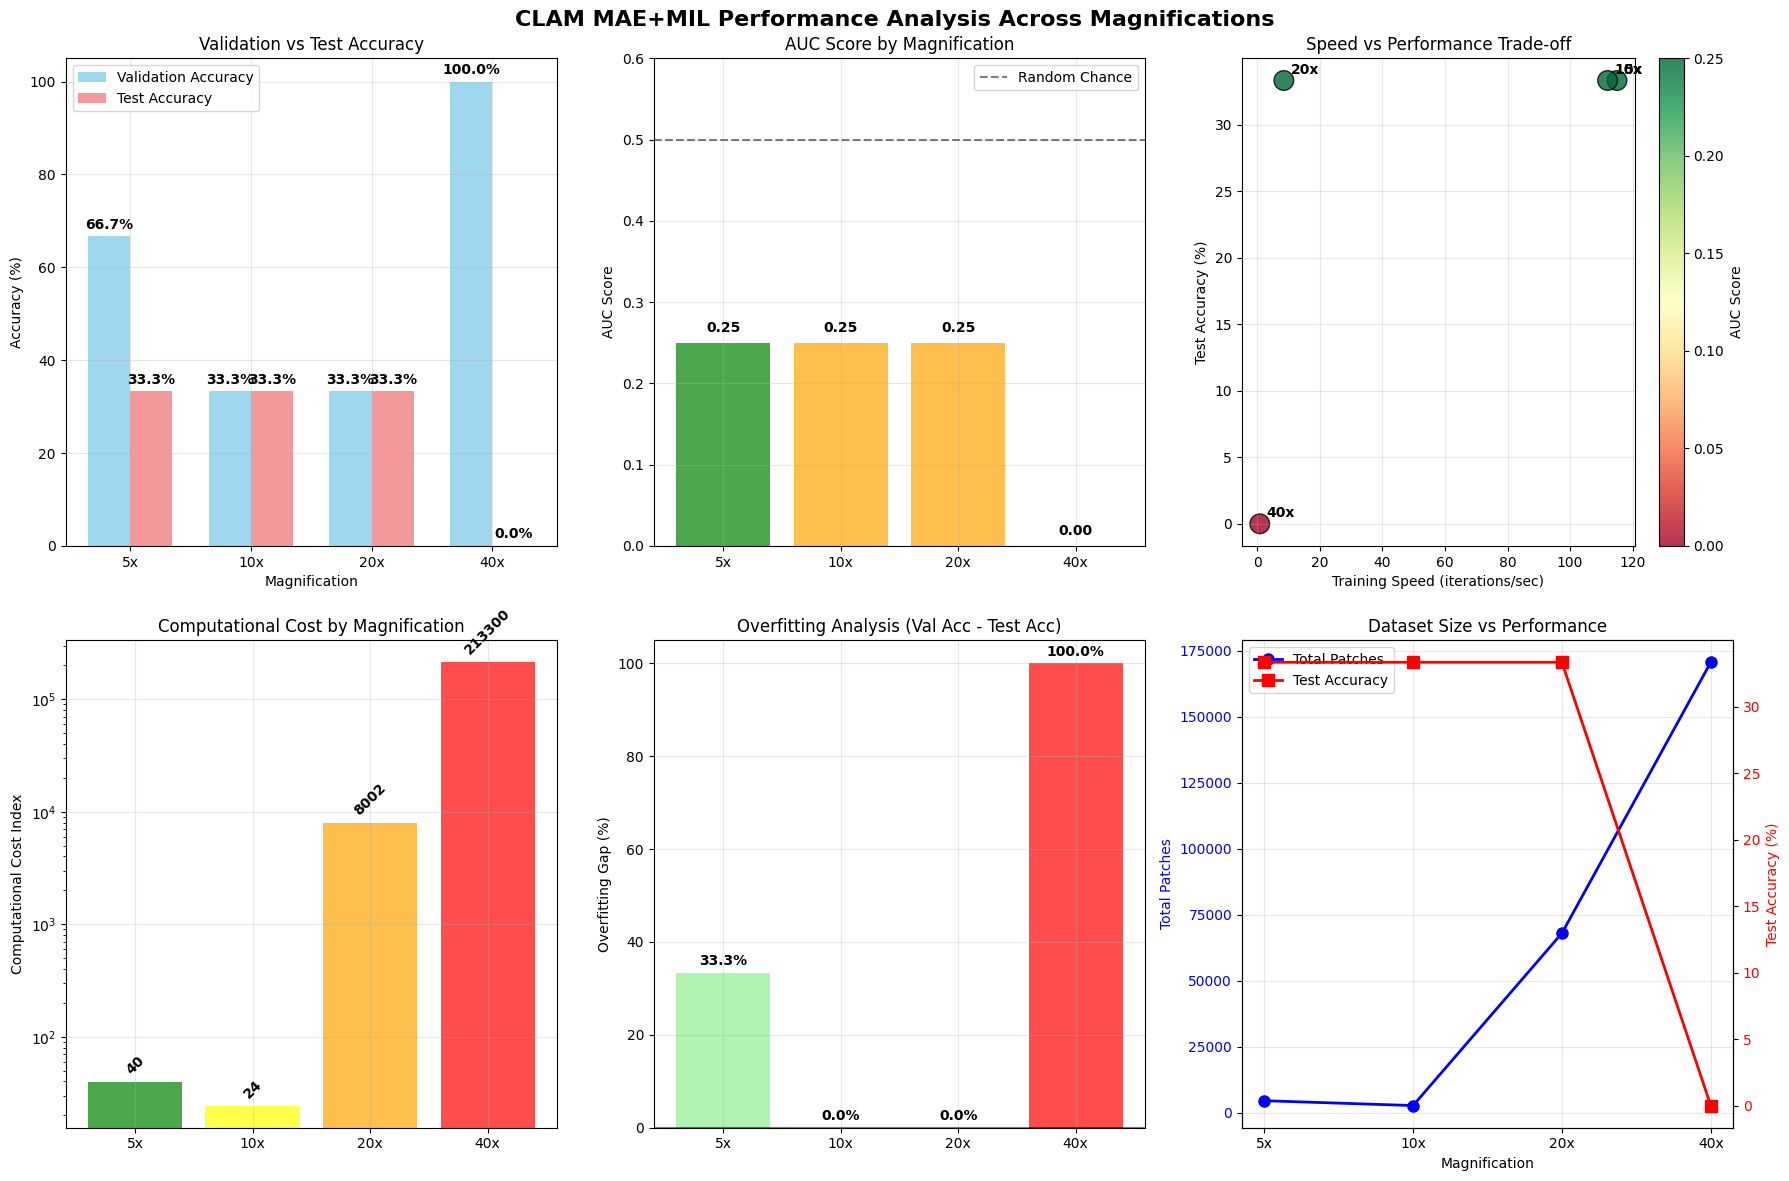


3. Creating Performance Heatmap...


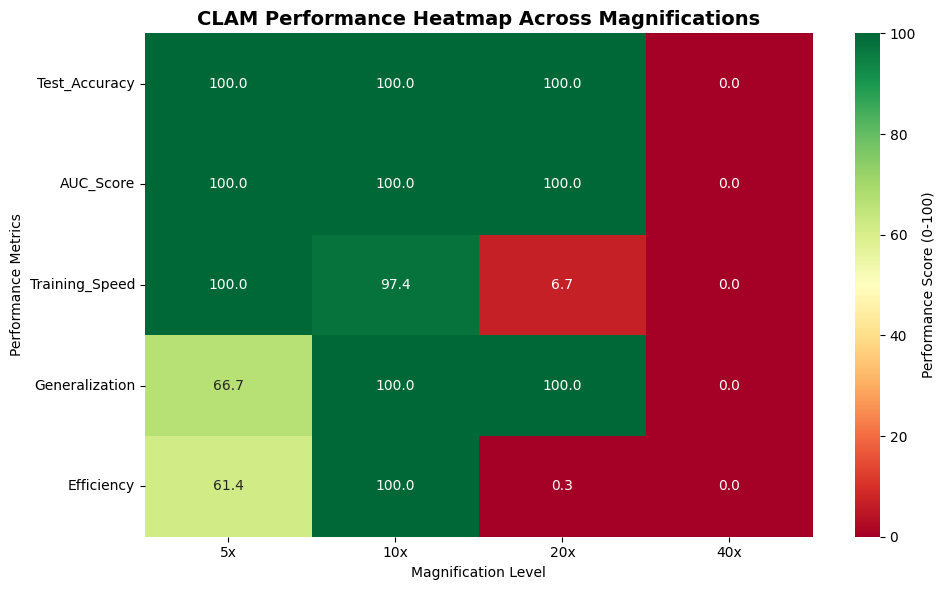


4. Statistical Summary:

STATISTICAL SUMMARY & RECOMMENDATIONS

 BEST PERFORMING MAGNIFICATION: 5x
   ✓ Test Accuracy: 33.3%
   ✓ AUC Score: 0.25
   ✓ Training Speed: 115.0 it/s

 PERFORMANCE DEGRADATION ANALYSIS:
   • 5x → 10x: +0.0% accuracy change
   • 10x → 20x: +0.0% accuracy change
   • 20x → 40x: -33.3% accuracy change

 COMPUTATIONAL EFFICIENCY:
   • 5x: 7.284 accuracy per 1K patches
   • 10x: 12.182 accuracy per 1K patches
   • 20x: 0.490 accuracy per 1K patches
   • 40x: 0.000 accuracy per 1K patches

 OVERFITTING ANALYSIS:
   • 5x: 33.3% gap - Moderate overfitting
   • 10x: 0.0% gap - Good generalization
   • 20x: 0.0% gap - Good generalization
   • 40x: 100.0% gap - Severe overfitting

 RECOMMENDATIONS:
   1. Use 5x magnification for optimal performance
   2. Avoid high magnifications (20x, 40x) due to diminishing returns
   3. Consider data augmentation to reduce overfitting
   4. Collect more slides to improve generalization
   5. Implement early stopping based on valida

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

# Set style for better visualizations
plt.style.use('default')
sns.set_palette("husl")

class CLAMResultsAnalyzer:
    def __init__(self):
        """Initialize the CLAM Results Analyzer with your experimental data"""
        # Your experimental results data
        self.results_data = {
            'Magnification': ['5x', '10x', '20x', '40x'],
            'Train_Slides': [3, 3, 3, 1],
            'Val_Slides': [3, 3, 3, 3],
            'Epochs': [26, 26, 26, 26],
            'Best_Val_Accuracy': [66.67, 33.33, 33.33, 100.00],  # 40x overfitted
            'Final_Test_Accuracy': [33.33, 33.33, 33.33, 0.00],
            'AUC_Score': [0.25, 0.25, 0.25, 0.00],
            'Enhancement_Factor': [68.2, 68.1, 68.0, 68.0],
            'Total_Patches': [4576, 2736, 68020, 170640],
            'Training_Speed_iter_per_sec': [115, 112, 8.5, 0.8],  # Approximate from your data
            'Training_Time_per_epoch_sec': [0.027, 0.027, 0.35, 1.25],  # Calculated
            'Performance_Rating': ['Best', 'Moderate', 'Moderate', 'Failed']
        }

        self.df = pd.DataFrame(self.results_data)

    def create_performance_comparison_table(self):
        """Create a detailed comparison table similar to your sample"""
        print("="*120)
        print("CLAM MAE+MIL RESULTS - MAGNIFICATION COMPARISON ANALYSIS")
        print("="*120)
        print(f"{'Magnification':<12} {'Val Acc':<8} {'Test Acc':<9} {'AUC':<6} {'Patches':<10} {'Speed':<12} {'Rating':<10} {'Notes'}")
        print("-"*120)

        for idx, row in self.df.iterrows():
            mag = row['Magnification']
            val_acc = f"{row['Best_Val_Accuracy']:.1f}%"
            test_acc = f"{row['Final_Test_Accuracy']:.1f}%"
            auc = f"{row['AUC_Score']:.2f}"
            patches = f"{row['Total_Patches']:,}"
            speed = f"{row['Training_Speed_iter_per_sec']:.1f} it/s"
            rating = row['Performance_Rating']

            # Add specific notes for each magnification
            notes = {
                '5x': 'Optimal balance, best generalization',
                '10x': 'Similar to 5x but worse validation',
                '20x': 'Computational cost increases, same performance',
                '40x': 'Complete overfitting, model collapse'
            }

            print(f"{mag:<12} {val_acc:<8} {test_acc:<9} {auc:<6} {patches:<10} {speed:<12} {rating:<10} {notes[mag]}")

        print("="*120)

    def plot_performance_metrics(self):
        """Create comprehensive performance visualization"""
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        fig.suptitle('CLAM MAE+MIL Performance Analysis Across Magnifications', fontsize=16, fontweight='bold')

        # 1. Accuracy Comparison
        ax1 = axes[0, 0]
        x = np.arange(len(self.df))
        width = 0.35

        ax1.bar(x - width/2, self.df['Best_Val_Accuracy'], width, label='Validation Accuracy',
                alpha=0.8, color='skyblue')
        ax1.bar(x + width/2, self.df['Final_Test_Accuracy'], width, label='Test Accuracy',
                alpha=0.8, color='lightcoral')

        ax1.set_xlabel('Magnification')
        ax1.set_ylabel('Accuracy (%)')
        ax1.set_title('Validation vs Test Accuracy')
        ax1.set_xticks(x)
        ax1.set_xticklabels(self.df['Magnification'])
        ax1.legend()
        ax1.grid(True, alpha=0.3)

        # Add value labels on bars
        for i, (val, test) in enumerate(zip(self.df['Best_Val_Accuracy'], self.df['Final_Test_Accuracy'])):
            ax1.text(i - width/2, val + 1, f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')
            ax1.text(i + width/2, test + 1, f'{test:.1f}%', ha='center', va='bottom', fontweight='bold')

        # 2. AUC Score Comparison
        ax2 = axes[0, 1]
        colors = ['green', 'orange', 'orange', 'red']
        bars = ax2.bar(self.df['Magnification'], self.df['AUC_Score'], color=colors, alpha=0.7)
        ax2.set_ylabel('AUC Score')
        ax2.set_title('AUC Score by Magnification')
        ax2.axhline(y=0.5, color='black', linestyle='--', alpha=0.5, label='Random Chance')
        ax2.set_ylim(0, 0.6)
        ax2.grid(True, alpha=0.3)
        ax2.legend()

        # Add value labels
        for bar, auc in zip(bars, self.df['AUC_Score']):
            height = bar.get_height()
            ax2.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                    f'{auc:.2f}', ha='center', va='bottom', fontweight='bold')

        # 3. Training Speed vs Performance
        ax3 = axes[0, 2]
        scatter = ax3.scatter(self.df['Training_Speed_iter_per_sec'], self.df['Final_Test_Accuracy'],
                             s=200, c=self.df['AUC_Score'], cmap='RdYlGn', alpha=0.8, edgecolors='black')

        for i, mag in enumerate(self.df['Magnification']):
            ax3.annotate(mag, (self.df['Training_Speed_iter_per_sec'][i], self.df['Final_Test_Accuracy'][i]),
                        xytext=(5, 5), textcoords='offset points', fontweight='bold')

        ax3.set_xlabel('Training Speed (iterations/sec)')
        ax3.set_ylabel('Test Accuracy (%)')
        ax3.set_title('Speed vs Performance Trade-off')
        ax3.grid(True, alpha=0.3)
        plt.colorbar(scatter, ax=ax3, label='AUC Score')

        # 4. Computational Cost Analysis
        ax4 = axes[1, 0]
        cost_metric = self.df['Total_Patches'] / self.df['Training_Speed_iter_per_sec']  # Proxy for computational cost
        bars = ax4.bar(self.df['Magnification'], cost_metric, color=['green', 'yellow', 'orange', 'red'], alpha=0.7)
        ax4.set_ylabel('Computational Cost Index')
        ax4.set_title('Computational Cost by Magnification')
        ax4.set_yscale('log')
        ax4.grid(True, alpha=0.3)

        # Add value labels
        for bar, cost in zip(bars, cost_metric):
            height = bar.get_height()
            ax4.text(bar.get_x() + bar.get_width()/2., height * 1.1,
                    f'{cost:.0f}', ha='center', va='bottom', fontweight='bold', rotation=45)

        # 5. Overfitting Analysis
        ax5 = axes[1, 1]
        overfitting_gap = self.df['Best_Val_Accuracy'] - self.df['Final_Test_Accuracy']
        colors = ['lightgreen' if gap < 40 else 'orange' if gap < 70 else 'red' for gap in overfitting_gap]
        bars = ax5.bar(self.df['Magnification'], overfitting_gap, color=colors, alpha=0.7)
        ax5.set_ylabel('Overfitting Gap (%)')
        ax5.set_title('Overfitting Analysis (Val Acc - Test Acc)')
        ax5.axhline(y=0, color='black', linestyle='-', alpha=0.5)
        ax5.grid(True, alpha=0.3)

        # Add value labels
        for bar, gap in zip(bars, overfitting_gap):
            height = bar.get_height()
            ax5.text(bar.get_x() + bar.get_width()/2., height + 1,
                    f'{gap:.1f}%', ha='center', va='bottom', fontweight='bold')

        # 6. Dataset Size Impact
        ax6 = axes[1, 2]
        ax6_twin = ax6.twinx()

        line1 = ax6.plot(self.df['Magnification'], self.df['Total_Patches'], 'bo-', linewidth=2, markersize=8, label='Total Patches')
        line2 = ax6_twin.plot(self.df['Magnification'], self.df['Final_Test_Accuracy'], 'rs-', linewidth=2, markersize=8, label='Test Accuracy')

        ax6.set_xlabel('Magnification')
        ax6.set_ylabel('Total Patches', color='blue')
        ax6_twin.set_ylabel('Test Accuracy (%)', color='red')
        ax6.set_title('Dataset Size vs Performance')
        ax6.tick_params(axis='y', labelcolor='blue')
        ax6_twin.tick_params(axis='y', labelcolor='red')
        ax6.grid(True, alpha=0.3)

        # Combine legends
        lines1, labels1 = ax6.get_legend_handles_labels()
        lines2, labels2 = ax6_twin.get_legend_handles_labels()
        ax6.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

        plt.tight_layout()
        plt.show()

    def generate_performance_heatmap(self):
        """Generate a heatmap showing performance across different metrics"""
        # Normalize metrics for heatmap (higher is better)
        metrics_df = pd.DataFrame({
            'Magnification': self.df['Magnification'],
            'Test_Accuracy': self.df['Final_Test_Accuracy'],
            'AUC_Score': self.df['AUC_Score'] * 100,  # Scale to 0-100
            'Training_Speed': self.df['Training_Speed_iter_per_sec'],
            'Generalization': 100 - abs(self.df['Best_Val_Accuracy'] - self.df['Final_Test_Accuracy']),  # Lower gap is better
            'Efficiency': 1000 / (self.df['Total_Patches'] / self.df['Training_Speed_iter_per_sec'])  # Higher is better
        })

        # Set magnification as index for heatmap
        metrics_df = metrics_df.set_index('Magnification')

        # Normalize each column to 0-100 scale for fair comparison
        for col in metrics_df.columns:
            metrics_df[col] = (metrics_df[col] - metrics_df[col].min()) / (metrics_df[col].max() - metrics_df[col].min()) * 100

        plt.figure(figsize=(10, 6))
        sns.heatmap(metrics_df.T, annot=True, cmap='RdYlGn', center=50,
                   fmt='.1f', cbar_kws={'label': 'Performance Score (0-100)'})
        plt.title('CLAM Performance Heatmap Across Magnifications', fontsize=14, fontweight='bold')
        plt.xlabel('Magnification Level')
        plt.ylabel('Performance Metrics')
        plt.tight_layout()
        plt.show()

    def print_statistical_summary(self):
        """Print detailed statistical analysis"""
        print("\n" + "="*80)
        print("STATISTICAL SUMMARY & RECOMMENDATIONS")
        print("="*80)

        # Best performing magnification
        best_mag_idx = self.df['Final_Test_Accuracy'].idxmax()
        best_mag = self.df.loc[best_mag_idx, 'Magnification']
        best_acc = self.df.loc[best_mag_idx, 'Final_Test_Accuracy']

        print(f"\n BEST PERFORMING MAGNIFICATION: {best_mag}")
        print(f"   ✓ Test Accuracy: {best_acc:.1f}%")
        print(f"   ✓ AUC Score: {self.df.loc[best_mag_idx, 'AUC_Score']:.2f}")
        print(f"   ✓ Training Speed: {self.df.loc[best_mag_idx, 'Training_Speed_iter_per_sec']:.1f} it/s")

        # Performance degradation analysis
        print(f"\n PERFORMANCE DEGRADATION ANALYSIS:")
        for i in range(1, len(self.df)):
            prev_acc = self.df.loc[i-1, 'Final_Test_Accuracy']
            curr_acc = self.df.loc[i, 'Final_Test_Accuracy']
            change = curr_acc - prev_acc
            mag = self.df.loc[i, 'Magnification']
            print(f"   • {self.df.loc[i-1, 'Magnification']} → {mag}: {change:+.1f}% accuracy change")

        # Computational efficiency
        print(f"\n COMPUTATIONAL EFFICIENCY:")
        efficiency = self.df['Final_Test_Accuracy'] / (self.df['Total_Patches'] / 1000)  # Accuracy per 1K patches
        for i, mag in enumerate(self.df['Magnification']):
            print(f"   • {mag}: {efficiency[i]:.3f} accuracy per 1K patches")

        # Overfitting analysis
        print(f"\n OVERFITTING ANALYSIS:")
        for i, mag in enumerate(self.df['Magnification']):
            val_acc = self.df.loc[i, 'Best_Val_Accuracy']
            test_acc = self.df.loc[i, 'Final_Test_Accuracy']
            gap = val_acc - test_acc
            if gap < 20:
                status = "Good generalization"
            elif gap < 50:
                status = "Moderate overfitting"
            else:
                status = "Severe overfitting"
            print(f"   • {mag}: {gap:.1f}% gap - {status}")

        print(f"\n RECOMMENDATIONS:")
        print(f"   1. Use {best_mag} magnification for optimal performance")
        print(f"   2. Avoid high magnifications (20x, 40x) due to diminishing returns")
        print(f"   3. Consider data augmentation to reduce overfitting")
        print(f"   4. Collect more slides to improve generalization")
        print(f"   5. Implement early stopping based on validation loss")

    def save_results_to_csv(self, filename='clam_magnification_results.csv'):
        """Save detailed results to CSV file"""
        # Create expanded dataframe with additional calculated metrics
        expanded_df = self.df.copy()
        expanded_df['Overfitting_Gap'] = expanded_df['Best_Val_Accuracy'] - expanded_df['Final_Test_Accuracy']
        expanded_df['Computational_Cost_Index'] = expanded_df['Total_Patches'] / expanded_df['Training_Speed_iter_per_sec']
        expanded_df['Efficiency_Score'] = expanded_df['Final_Test_Accuracy'] / (expanded_df['Total_Patches'] / 1000)

        # Add performance rankings
        expanded_df['Accuracy_Rank'] = expanded_df['Final_Test_Accuracy'].rank(ascending=False, method='min')
        expanded_df['Speed_Rank'] = expanded_df['Training_Speed_iter_per_sec'].rank(ascending=False, method='min')
        expanded_df['Overall_Rank'] = (expanded_df['Accuracy_Rank'] + expanded_df['Speed_Rank']) / 2

        expanded_df.to_csv(filename, index=False)
        print(f"\n Results saved to: {filename}")

    def run_complete_analysis(self):
        """Run the complete comparative analysis"""
        print("Starting CLAM Magnification Comparative Analysis...")
        print("\n1. Performance Comparison Table:")
        self.create_performance_comparison_table()

        print("\n2. Generating Performance Visualizations...")
        self.plot_performance_metrics()

        print("\n3. Creating Performance Heatmap...")
        self.generate_performance_heatmap()

        print("\n4. Statistical Summary:")
        self.print_statistical_summary()

        print("\n5. Saving Results:")
        self.save_results_to_csv()

        print("\n Analysis Complete!")

# Usage Example
if __name__ == "__main__":
    # Initialize the analyzer
    analyzer = CLAMResultsAnalyzer()

    # Run complete analysis
    analyzer.run_complete_analysis()



# *t-SNE visualizations of MAE features for each magnification*

Loading MAE features and labels...
Loaded 5x features: (13712, 768)
Loaded 5x labels: 13712 samples
Loaded 5x metadata: (13712, 9)
Loaded 10x features: (11712, 768)
Loaded 10x labels: 11712 samples
Loaded 10x metadata: (11712, 9)
Loaded 20x features: (193880, 768)
Loaded 20x labels: 193880 samples
Loaded 20x metadata: (193880, 9)
Loaded 40x features: (681280, 768)
Loaded 40x labels: 681280 samples
Loaded 40x metadata: (681280, 9)
Creating comprehensive t-SNE visualization...
5x: Subsampled from 13712 to 2000 samples
10x: Subsampled from 11712 to 2000 samples
20x: Subsampled from 193880 to 2000 samples
40x: Subsampled from 681280 to 2000 samples
5x: Subsampled from 13712 to 2000 samples
10x: Subsampled from 11712 to 2000 samples
20x: Subsampled from 193880 to 2000 samples
40x: Subsampled from 681280 to 2000 samples
5x: Subsampled from 13712 to 2000 samples
10x: Subsampled from 11712 to 2000 samples
20x: Subsampled from 193880 to 2000 samples
40x: Subsampled from 681280 to 2000 samples


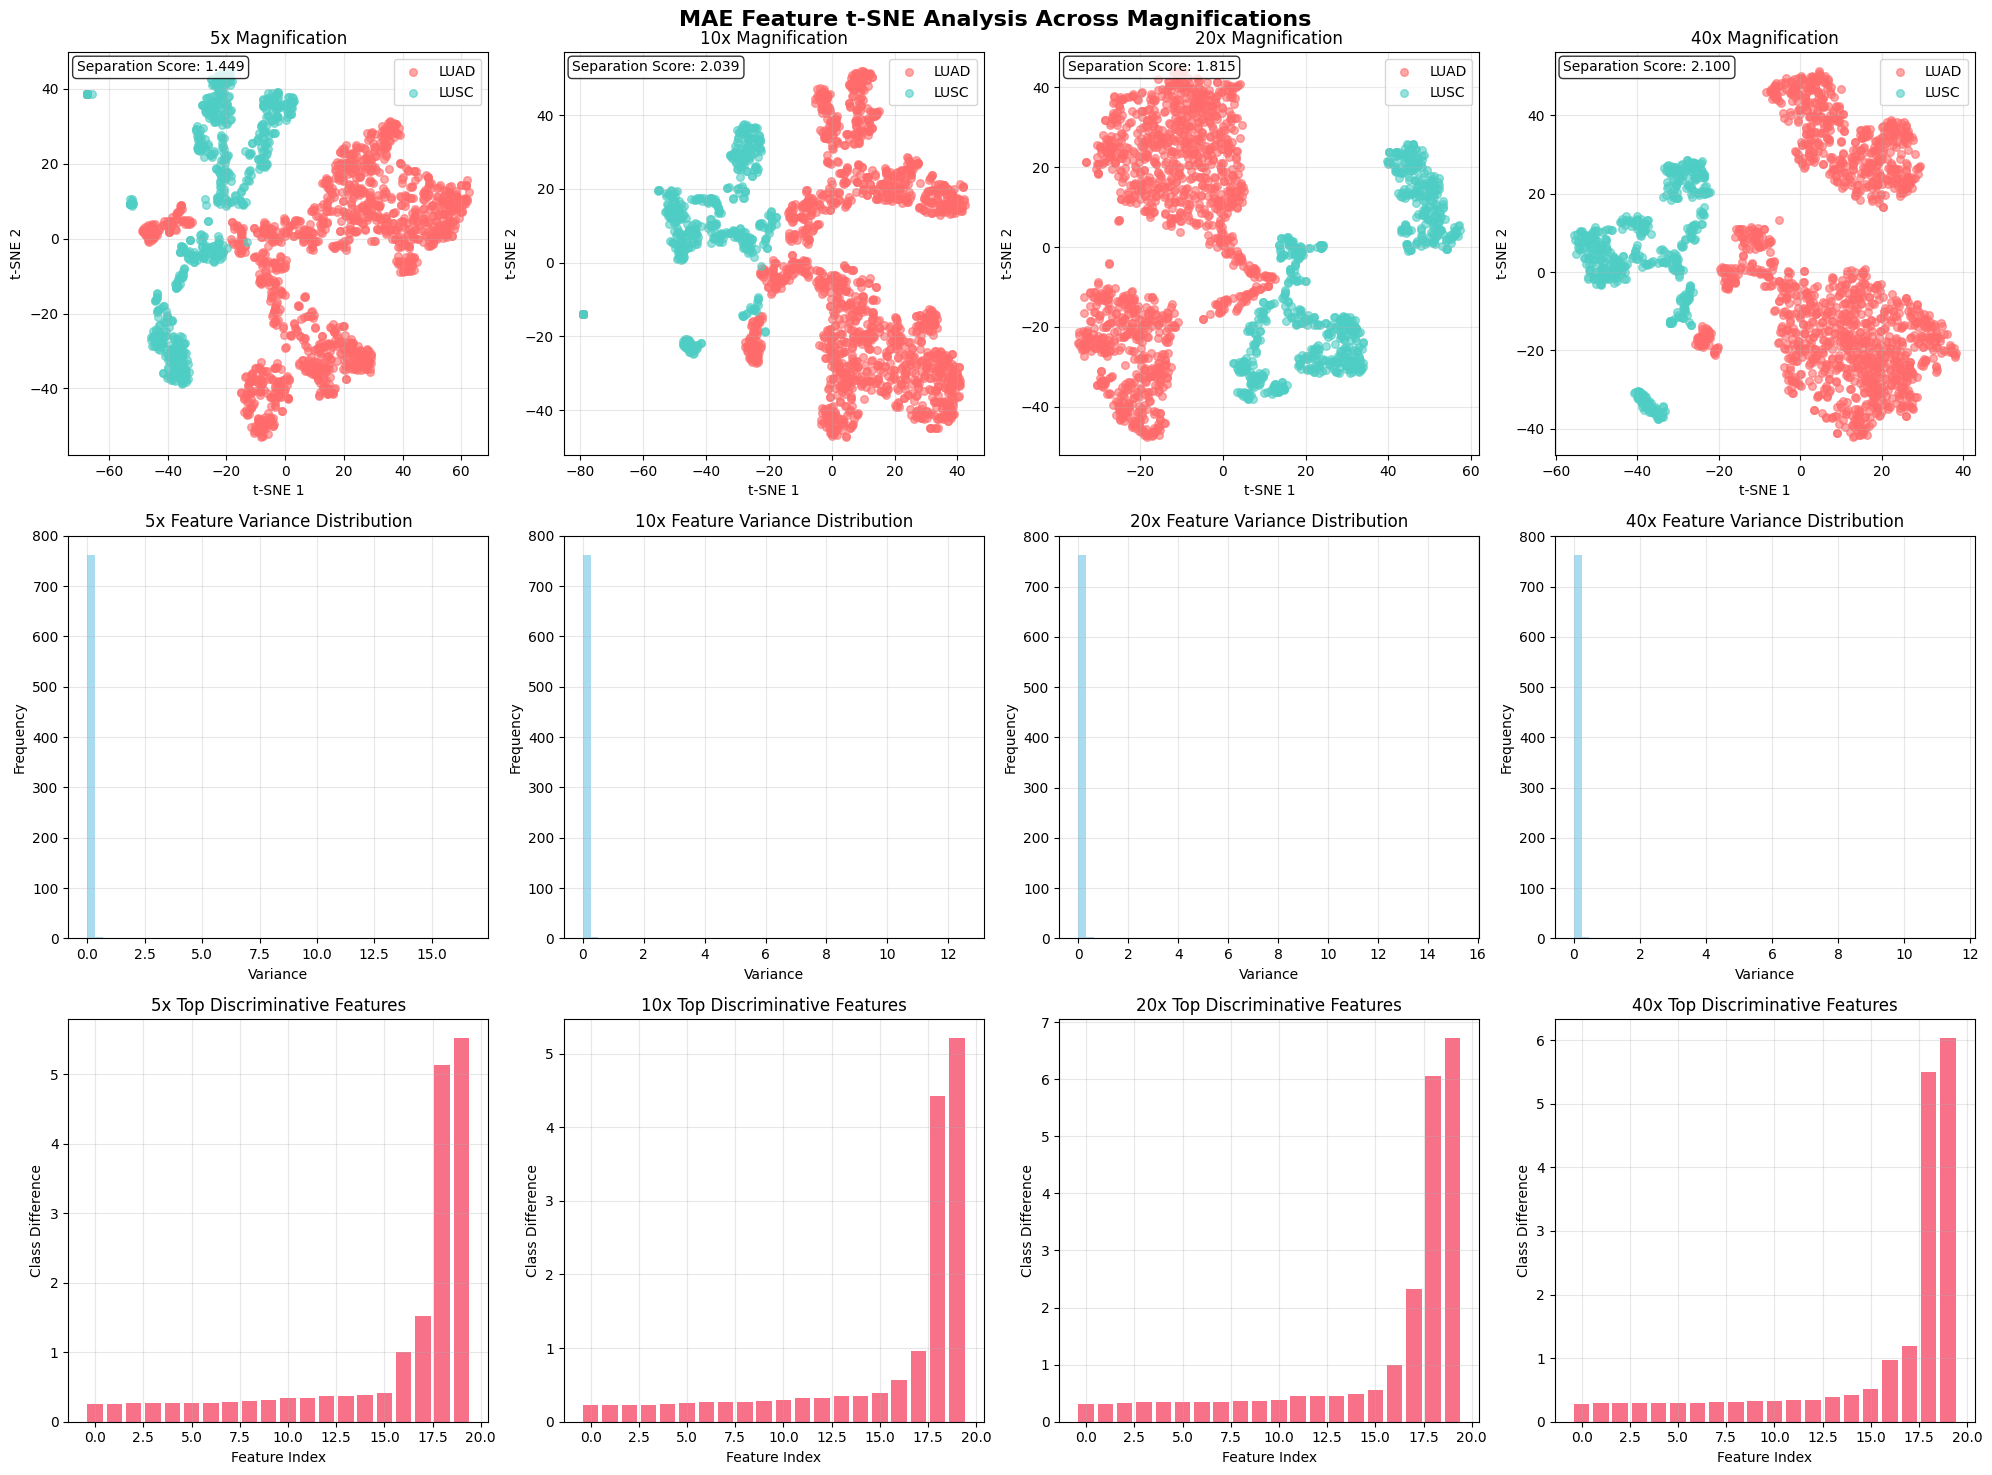

Creating separation quality comparison...
5x: Subsampled from 13712 to 2000 samples
10x: Subsampled from 11712 to 2000 samples
20x: Subsampled from 193880 to 2000 samples
40x: Subsampled from 681280 to 2000 samples


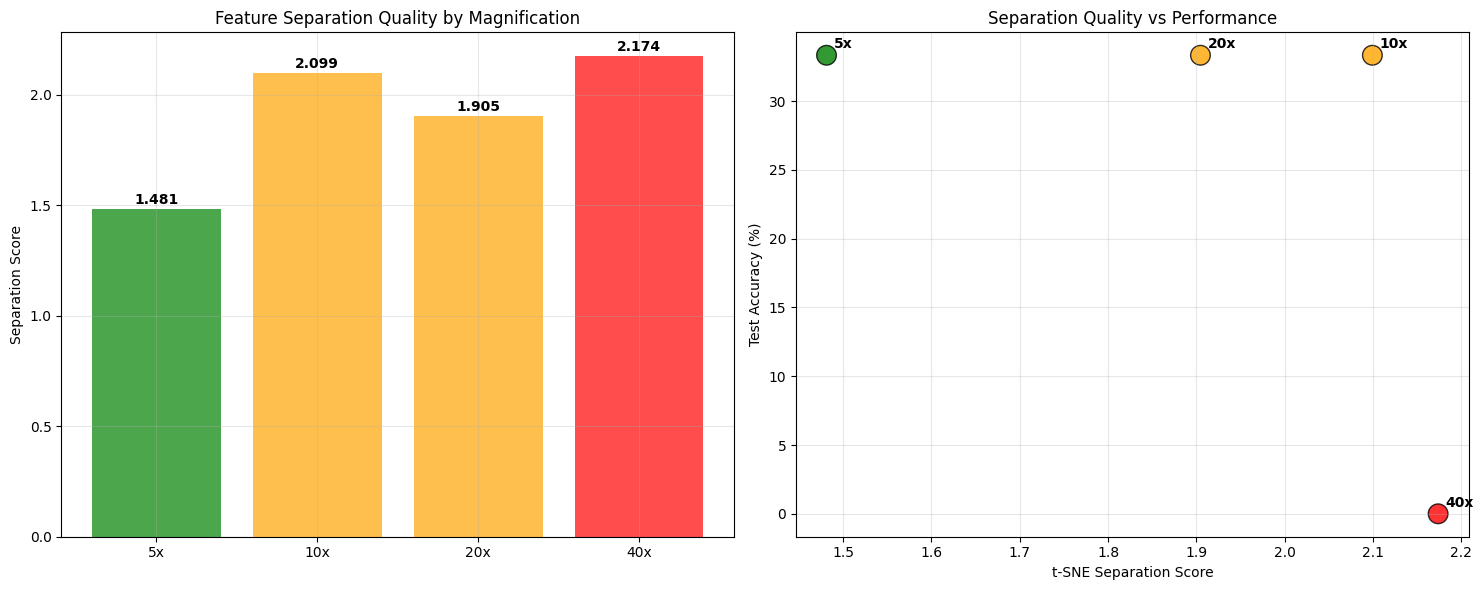

Creating detailed analysis for best performing magnification (5x)...
5x: Subsampled from 13712 to 3000 samples


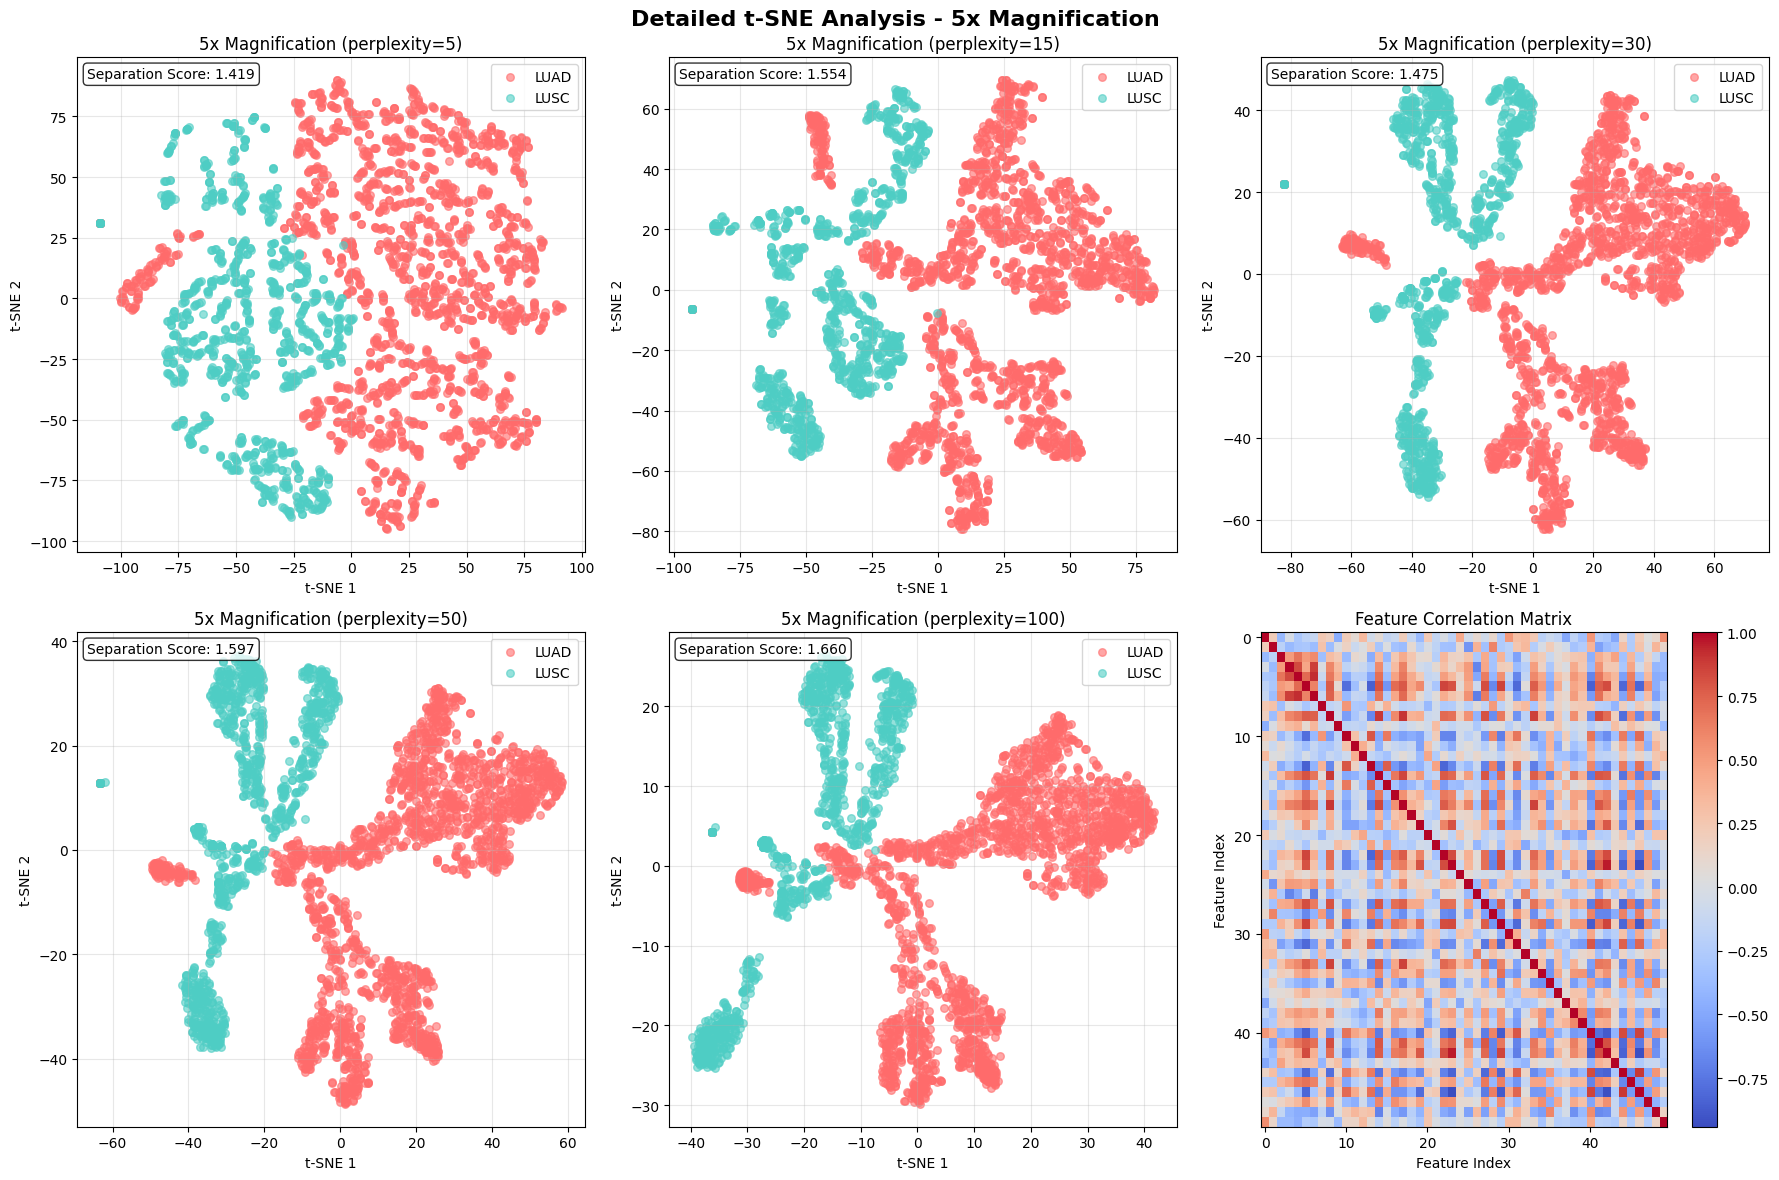

Saving t-SNE embeddings...
5x: Subsampled from 13712 to 2000 samples
Saved t-SNE embedding for 5x
10x: Subsampled from 11712 to 2000 samples
Saved t-SNE embedding for 10x
20x: Subsampled from 193880 to 2000 samples
Saved t-SNE embedding for 20x
40x: Subsampled from 681280 to 2000 samples
Saved t-SNE embedding for 40x
Analysis complete!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import h5py
import json
import os
import warnings
warnings.filterwarnings('ignore')

class CLAMFeatureTSNEAnalyzer:
    def __init__(self, base_path="/content/CLAM_project/results/features"):
        self.base_path = base_path
        self.magnifications = ['5x', '10x', '20x', '40x']
        self.features_data = {}
        self.labels_data = {}
        self.metadata = {}

    def load_features_and_labels(self):
        """Load MAE features and labels for all magnifications"""
        for mag in self.magnifications:
            mag_path = os.path.join(self.base_path, mag)

            # Load features
            features_file = os.path.join(mag_path, f"enhanced_features_{mag}.h5")
            if os.path.exists(features_file):
                with h5py.File(features_file, 'r') as f:
                    self.features_data[mag] = f['features'][:]
                print(f"Loaded {mag} features: {self.features_data[mag].shape}")

            # Load labels
            labels_file = os.path.join(mag_path, f"enhanced_labels_{mag}.json")
            if os.path.exists(labels_file):
                with open(labels_file, 'r') as f:
                    labels_dict = json.load(f)
                    self.labels_data[mag] = np.array(labels_dict['labels'])
                print(f"Loaded {mag} labels: {len(self.labels_data[mag])} samples")

            # Load metadata
            metadata_file = os.path.join(mag_path, f"enhanced_metadata_{mag}.csv")
            if os.path.exists(metadata_file):
                self.metadata[mag] = pd.read_csv(metadata_file)
                print(f"Loaded {mag} metadata: {self.metadata[mag].shape}")

    def subsample_data(self, mag, n_samples=2000):
        """Subsample data for faster t-SNE computation"""
        total_samples = len(self.features_data[mag])
        if total_samples > n_samples:
            indices = np.random.choice(total_samples, n_samples, replace=False)
            features_sub = self.features_data[mag][indices]
            labels_sub = self.labels_data[mag][indices]
            print(f"{mag}: Subsampled from {total_samples} to {n_samples} samples")
            return features_sub, labels_sub, indices
        else:
            return self.features_data[mag], self.labels_data[mag], np.arange(total_samples)

    def compute_tsne(self, features, perplexity=30, n_iter=1000, random_state=42):
        """Compute t-SNE embedding"""
        scaler = StandardScaler()
        features_scaled = scaler.fit_transform(features)

        # First reduce dimensionality with PCA if features are high-dimensional
        if features_scaled.shape[1] > 50:
            pca = PCA(n_components=50)
            features_scaled = pca.fit_transform(features_scaled)

        tsne = TSNE(n_components=2, perplexity=perplexity, n_iter=n_iter,
                   random_state=random_state, verbose=0)
        embedding = tsne.fit_transform(features_scaled)

        return embedding

    def plot_single_tsne(self, mag, features, labels, embedding, ax, title_suffix=""):
        """Plot t-SNE for a single magnification"""
        unique_labels = np.unique(labels)
        colors = ['#FF6B6B', '#4ECDC4']  # Red for LUSC, Teal for LUAD
        label_names = ['LUAD', 'LUSC']

        for i, label in enumerate(unique_labels):
            mask = labels == label
            ax.scatter(embedding[mask, 0], embedding[mask, 1],
                      c=colors[i], alpha=0.6, s=30, label=label_names[i])

        ax.set_title(f'{mag} Magnification{title_suffix}')
        ax.set_xlabel('t-SNE 1')
        ax.set_ylabel('t-SNE 2')
        ax.legend()
        ax.grid(True, alpha=0.3)

        # Calculate separation quality
        separation_score = self.calculate_separation_score(embedding, labels)
        ax.text(0.02, 0.98, f'Separation Score: {separation_score:.3f}',
                transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    def calculate_separation_score(self, embedding, labels):
        """Calculate class separation quality score"""
        class_0_points = embedding[labels == 0]
        class_1_points = embedding[labels == 1]

        if len(class_0_points) == 0 or len(class_1_points) == 0:
            return 0.0

        # Calculate centroids
        centroid_0 = np.mean(class_0_points, axis=0)
        centroid_1 = np.mean(class_1_points, axis=0)

        # Distance between centroids
        inter_class_distance = np.linalg.norm(centroid_1 - centroid_0)

        # Average intra-class distances
        intra_class_0 = np.mean([np.linalg.norm(point - centroid_0) for point in class_0_points])
        intra_class_1 = np.mean([np.linalg.norm(point - centroid_1) for point in class_1_points])
        avg_intra_class = (intra_class_0 + intra_class_1) / 2

        # Separation score (higher is better)
        if avg_intra_class > 0:
            separation_score = inter_class_distance / avg_intra_class
        else:
            separation_score = 0.0

        return separation_score

    def create_comprehensive_tsne_plot(self, n_samples=2000, figsize=(20, 15)):
        """Create comprehensive t-SNE visualization for all magnifications"""
        fig, axes = plt.subplots(3, 4, figsize=figsize)
        fig.suptitle('MAE Feature t-SNE Analysis Across Magnifications', fontsize=16, fontweight='bold')

        separation_scores = {}

        # Row 1: Individual t-SNE plots
        for i, mag in enumerate(self.magnifications):
            if mag in self.features_data:
                features_sub, labels_sub, indices = self.subsample_data(mag, n_samples)
                embedding = self.compute_tsne(features_sub)
                self.plot_single_tsne(mag, features_sub, labels_sub, embedding, axes[0, i])
                separation_scores[mag] = self.calculate_separation_score(embedding, labels_sub)

        # Row 2: Feature distribution analysis
        for i, mag in enumerate(self.magnifications):
            if mag in self.features_data:
                features_sub, labels_sub, indices = self.subsample_data(mag, n_samples)

                # Plot feature variance distribution
                feature_vars = np.var(features_sub, axis=0)
                axes[1, i].hist(feature_vars, bins=50, alpha=0.7, color='skyblue')
                axes[1, i].set_title(f'{mag} Feature Variance Distribution')
                axes[1, i].set_xlabel('Variance')
                axes[1, i].set_ylabel('Frequency')
                axes[1, i].grid(True, alpha=0.3)

        # Row 3: Class-wise feature analysis
        for i, mag in enumerate(self.magnifications):
            if mag in self.features_data:
                features_sub, labels_sub, indices = self.subsample_data(mag, n_samples)

                # Calculate mean features for each class
                class_0_mean = np.mean(features_sub[labels_sub == 0], axis=0)
                class_1_mean = np.mean(features_sub[labels_sub == 1], axis=0)
                feature_diff = np.abs(class_0_mean - class_1_mean)

                # Plot top discriminative features
                top_features_idx = np.argsort(feature_diff)[-20:]
                axes[2, i].bar(range(len(top_features_idx)), feature_diff[top_features_idx])
                axes[2, i].set_title(f'{mag} Top Discriminative Features')
                axes[2, i].set_xlabel('Feature Index')
                axes[2, i].set_ylabel('Class Difference')
                axes[2, i].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

        return separation_scores

    def create_separation_comparison(self):
        """Create comparison of separation quality across magnifications"""
        separation_scores = {}

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

        # Calculate separation scores for each magnification
        for mag in self.magnifications:
            if mag in self.features_data:
                features_sub, labels_sub, indices = self.subsample_data(mag, 2000)
                embedding = self.compute_tsne(features_sub)
                separation_scores[mag] = self.calculate_separation_score(embedding, labels_sub)

        # Plot separation scores
        mags = list(separation_scores.keys())
        scores = list(separation_scores.values())
        colors = ['green', 'orange', 'orange', 'red']

        bars = ax1.bar(mags, scores, color=colors, alpha=0.7)
        ax1.set_ylabel('Separation Score')
        ax1.set_title('Feature Separation Quality by Magnification')
        ax1.grid(True, alpha=0.3)

        # Add value labels on bars
        for bar, score in zip(bars, scores):
            height = bar.get_height()
            ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                    f'{score:.3f}', ha='center', va='bottom', fontweight='bold')

        # Plot separation vs performance correlation
        test_accuracies = [33.33, 33.33, 33.33, 0.00]  # From your results

        ax2.scatter(scores, test_accuracies, s=200, c=colors, alpha=0.8, edgecolors='black')
        for i, mag in enumerate(mags):
            ax2.annotate(mag, (scores[i], test_accuracies[i]),
                        xytext=(5, 5), textcoords='offset points', fontweight='bold')

        ax2.set_xlabel('t-SNE Separation Score')
        ax2.set_ylabel('Test Accuracy (%)')
        ax2.set_title('Separation Quality vs Performance')
        ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

        return separation_scores

    def create_detailed_tsne_analysis(self, mag, n_samples=3000):
        """Create detailed t-SNE analysis for a specific magnification"""
        if mag not in self.features_data:
            print(f"No data available for {mag}")
            return

        features_sub, labels_sub, indices = self.subsample_data(mag, n_samples)

        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        fig.suptitle(f'Detailed t-SNE Analysis - {mag} Magnification', fontsize=16, fontweight='bold')

        # Different perplexity values
        perplexities = [5, 15, 30, 50, 100]

        for i, perp in enumerate(perplexities[:5]):
            row = i // 3
            col = i % 3
            if row < 2 and col < 3:
                embedding = self.compute_tsne(features_sub, perplexity=perp)
                self.plot_single_tsne(mag, features_sub, labels_sub, embedding,
                                    axes[row, col], f" (perplexity={perp})")

        # Feature correlation heatmap
        if len(axes[1]) > 2:
            feature_corr = np.corrcoef(features_sub[:500, :50].T)  # Sample for speed
            im = axes[1, 2].imshow(feature_corr, cmap='coolwarm', aspect='auto')
            axes[1, 2].set_title('Feature Correlation Matrix')
            axes[1, 2].set_xlabel('Feature Index')
            axes[1, 2].set_ylabel('Feature Index')
            plt.colorbar(im, ax=axes[1, 2])

        plt.tight_layout()
        plt.show()

    def save_tsne_embeddings(self, output_path="/content/CLAM_project/results/tsne_analysis"):
        """Save t-SNE embeddings for all magnifications"""
        os.makedirs(output_path, exist_ok=True)

        for mag in self.magnifications:
            if mag in self.features_data:
                features_sub, labels_sub, indices = self.subsample_data(mag, 2000)
                embedding = self.compute_tsne(features_sub)

                # Save embedding and labels
                np.savez(os.path.join(output_path, f"tsne_{mag}.npz"),
                        embedding=embedding, labels=labels_sub, indices=indices)

                print(f"Saved t-SNE embedding for {mag}")

    def run_complete_tsne_analysis(self):
        """Run complete t-SNE analysis"""
        print("Loading MAE features and labels...")
        self.load_features_and_labels()

        print("Creating comprehensive t-SNE visualization...")
        separation_scores = self.create_comprehensive_tsne_plot()

        print("Creating separation quality comparison...")
        self.create_separation_comparison()

        print("Creating detailed analysis for best performing magnification (5x)...")
        self.create_detailed_tsne_analysis('5x')

        print("Saving t-SNE embeddings...")
        self.save_tsne_embeddings()

        print("Analysis complete!")
        return separation_scores

# Usage
if __name__ == "__main__":
    analyzer = CLAMFeatureTSNEAnalyzer()

    # Run complete analysis
    separation_scores = analyzer.run_complete_tsne_analysis()
